In [2]:
%load_ext autoreload
%autoreload 2

import jax.numpy as jnp

from mGST.utility_functions_comparisons import get_target_operators_gate_set_name, get_compressed_rep_from_mgst_output, kraus_tensor_to_mgst

from mGST.simulate import apply_noisy_kraus_tensors_to_target_gate_set, get_random_noisy_kraus_tensors_for_gate_set, run_optimization_workflow_multi_init_realizations

from mGST.gauge_analysis import max_num_parameters, min_num_parameters

from mGST.analysis import get_all_realizations_for_key, compute_mve_and_wve_for_all_realizations, combine_error_results, compute_avg_and_std_along_keys

from mGST.visualization import plot_cost_function, plot_many_mean_std_vs_x

from mGST.typing import TrustRegionOptions, OperatorSchedule

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Parameters

In [3]:
num_shots = 1000
seq_len_list = [1, 8, 14]
num_qubits = 2
dim = 2 ** num_qubits
state_rank = dim # max
povm_rank = dim # max
kraus_rank = 4 # start with a small rank
num_gates = 6
num_povm = dim
gate_set_name = "2QXYICZ"
noise_strength = 5e-2

title_init = rf"{num_qubits}Q | $r_\mathrm{{Kraus}}$: {kraus_rank} | $r_\mathrm{{POVM}}$: {povm_rank} | $r_\mathrm{{State}}$: {state_rank} | Random Noisy Gate Set | Shots: {num_shots}"

num_realizations = 5
num_max_random_inits = 10
num_max_iterations_random_inits = 5
threshold_multiplier = 3.0 # for the random inits optimization
batch_size = 30 * dim # from mGST estimates see `compressive_gst`

mve_seq_length = 10
num_circuits_sampled = int(1e3)
num_random_runs = 10
title_mve = title_init + f" \n Random inits: {num_max_random_inits} | Realizations: {num_realizations}"

In [4]:
min_expected, max_expected = min_num_parameters(num_qubits=num_qubits, num_gates=num_gates, state_rank=state_rank, povm_rank=povm_rank, kraus_rank=kraus_rank), max_num_parameters(num_qubits=num_qubits, num_gates=num_gates, state_rank=state_rank, povm_rank=povm_rank, kraus_rank=kraus_rank)
print(f"Min expected parameters: {min_expected}, Max expected parameters: {max_expected}")

Min expected parameters: 623, Max expected parameters: 815


# Target tensors

In [5]:
target_operators, gate_labels = get_target_operators_gate_set_name(gate_set_name=gate_set_name)

random_kraus_tensors = get_random_noisy_kraus_tensors_for_gate_set(
    num_gates=num_gates,
    dim=dim,
    rank_kraus=kraus_rank,
    noise_strength=noise_strength,
    seed=42
)

noisy_gate_set_superop = apply_noisy_kraus_tensors_to_target_gate_set(
    kraus_tensors_noisy=random_kraus_tensors,
    target_gate_set=target_operators,
    is_target_vectorized=True,
)

INFO:2026-10-28 15:50:46,070:jax._src.xla_bridge:927: Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
2026-10-28 15:50:46,070 - jax._src.xla_bridge - INFO - Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:2026-10-28 15:50:46,087:jax._src.xla_bridge:927: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/

In [6]:
kraus_tensor_noisy, povm_psd_noisy, state_psd_noisy = get_compressed_rep_from_mgst_output(
    *noisy_gate_set_superop.values(),
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank)

kraus_target_superop = kraus_tensor_to_mgst(target_operators["kraus"])

target_gate_set_superops = {
    "kraus": kraus_target_superop,
    "povm": target_operators["povm"],
    "state": target_operators["state"],
}

# Gathering them all in one place
noisy_gate_set_psd = {
    "kraus": kraus_tensor_noisy,
    "povm": povm_psd_noisy,
    "state": state_psd_noisy,
}

# Optimization

In [14]:
num_iterations_outer = 20
num_iterations_tr = 5
num_iterations_cg = 10 
tol_grad = 1e-8 # it was 1e-4 before. 1e-8 is suggested in the book.
relative_precision = 1e-3 # changed due to the changes in convergence criteria
global_gradient_norm_tol = 1e-10

tr_options_distance = TrustRegionOptions(num_iterations=num_iterations_tr, verbose=False, verbose_cg=False, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, radius_heuristic="typical_distance")

schedule_distance = OperatorSchedule.default(num_iterations_outer, tr_options_distance)

optimization_schedule = {op: schedule_distance for op in ["povm", "kraus", "state"]}

optimization_options_silence = {
    "schedule": optimization_schedule,
    "num_iterations_outer": num_iterations_outer,
    "relative_precision": relative_precision,
    "global_gradient_norm_tol": global_gradient_norm_tol,
    "noise_threshold": None,
    "compute_least_squares": 1,
    "optimization_verbose": False,
    "absolute_tolerance": 1, # for a global convergence criteria
}
optimization_options_silence

{'schedule': {'povm': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=False, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, verbose_cg=False, linearize=False, radius_heuristic='typical_distance'))]),
  'kraus': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=False, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, verbose_cg=False, linearize=False, radius_heuristic='typical_distance'))]),
  'state': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=False, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, ver

## First, lets do one that we know works

In [80]:
from mGST.simulate import generate_sequence_indices, compute_probability_matrices, run_optimization_workflow
from mGST.utility_functions_comparisons import get_initial_gate_set_for_optimization
from mGST.trust_region import are_all_tensors_in_gate_set_isometries
from mGST.analysis import compute_mve_and_wve_from_optimization_results

In [62]:
num_seq_good = int(1e3)
seq_len_list = [1, 8, 14]
seed = 42

indices_dict_r = generate_sequence_indices(
    num_gates=num_gates,
    num_circuits=num_seq_good,
    seq_len_list=seq_len_list,
)
probability_matrices_r = compute_probability_matrices(
    *noisy_gate_set_psd.values(),
    gate_indices=indices_dict_r["gate_indices"],
    num_shots=num_shots,
    seed=seed,
)

In [168]:
# compute the noise threshold so I know what to expect in the rest of the experiments
from mGST.trust_region import estimate_noise_floor_threshold
    
noise_threshold = estimate_noise_floor_threshold(multiplier=threshold_multiplier, num_shots=num_shots, probability_matrix=probability_matrices_r["sampled"])
noise_threshold

Array(0.00041831, dtype=float64)

In [68]:
# initialized at a perturbed point of the target gate set
spam_depolarization = 1e-2

init_gate_set_psd = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    project_kraus_to_isometry=True, # because it is max rank, even false would return an isometry
)
print("All isometries (interior SPAM init):", are_all_tensors_in_gate_set_isometries(init_gate_set_psd))

All isometries (interior SPAM init): True


In [69]:
final_result_test = run_optimization_workflow(
            num_shots=num_shots,
            init_operators=init_gate_set_psd,
            operators_psd_true=noisy_gate_set_psd,
            target_superops=target_gate_set_superops,
            use_exact_probabilities=False, # test first with finite shots
            optimization_options=optimization_options_silence,
            warmup_run=False,
            use_log_likelihood=True,
            indices_dict=indices_dict_r, 
            probability_matrices=probability_matrices_r,
            verbose=True,
            gauge_optimize=True, # why not?
        )

/Users/emiliano.godinez/Documents/phd/iqm-benchmarks/src/mGST/simulate.py:690: UserWarning: When both `indices_dict` and `probability_matrices` are provided, make sure these are compatible.
  warnings.warn("When both `indices_dict` and `probability_matrices` are provided, make sure these are compatible.")


Using log-likelihood for the cost function optimization 🧮
🔰 Starting Riemannian Optimization 🔰
‼️ Full optimization finished at iteration 11/20 ‼️ 
 Reason: Relative change in reducible cost 5.95e-04 below target relative precision 1.00e-03 🎯.. 
 Trust region radii carried over: {'kraus': 0.038273277230987154, 'povm': 0.0078125, 'state': 0.125}.


In [71]:
final_result_test.keys()

dict_keys(['optimized_operators', 'cost_fn_history', 'probability_matrices', 'indices_dict', 'times', 'convergence_reason', 'init_operators', 'superops_gauged', 'target_model_pygsti'])

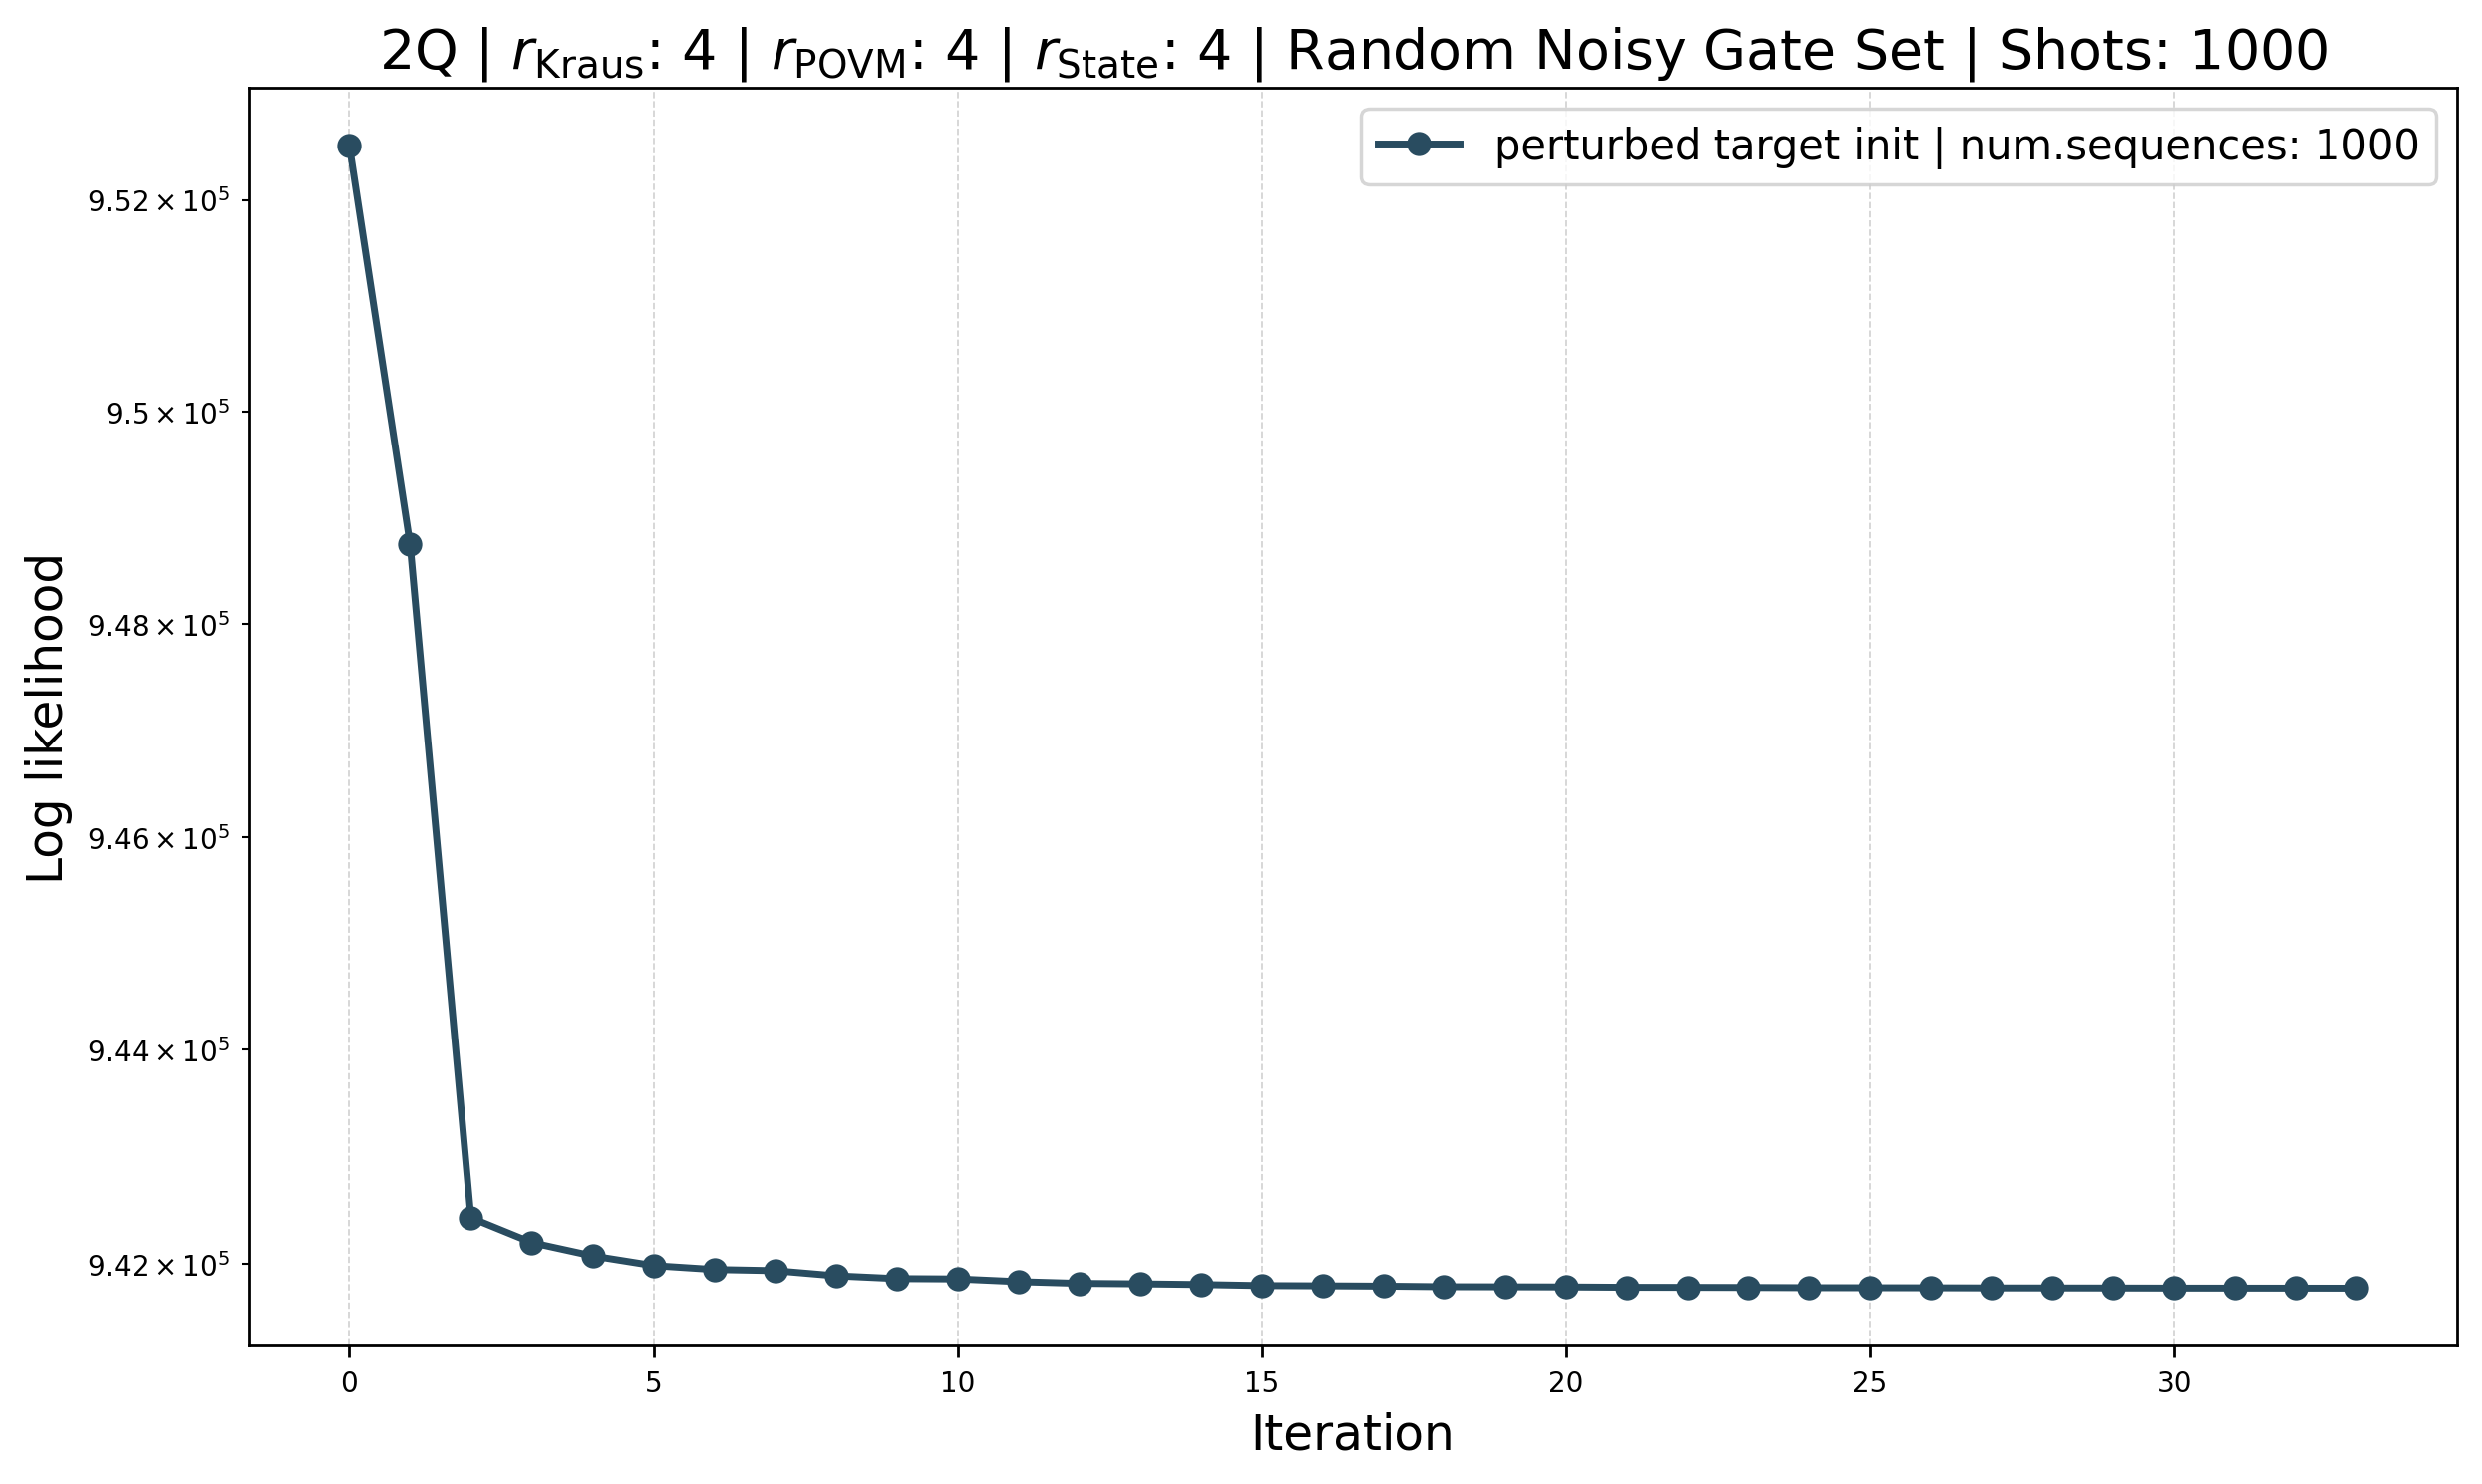

In [76]:
labels = [f"perturbed target init | num.sequences: {num_seq_good}"]
plot_cost_function([final_result_test["cost_fn_history"]["main"]], title=title_init, labels=labels, ylabel="Log likelihood")

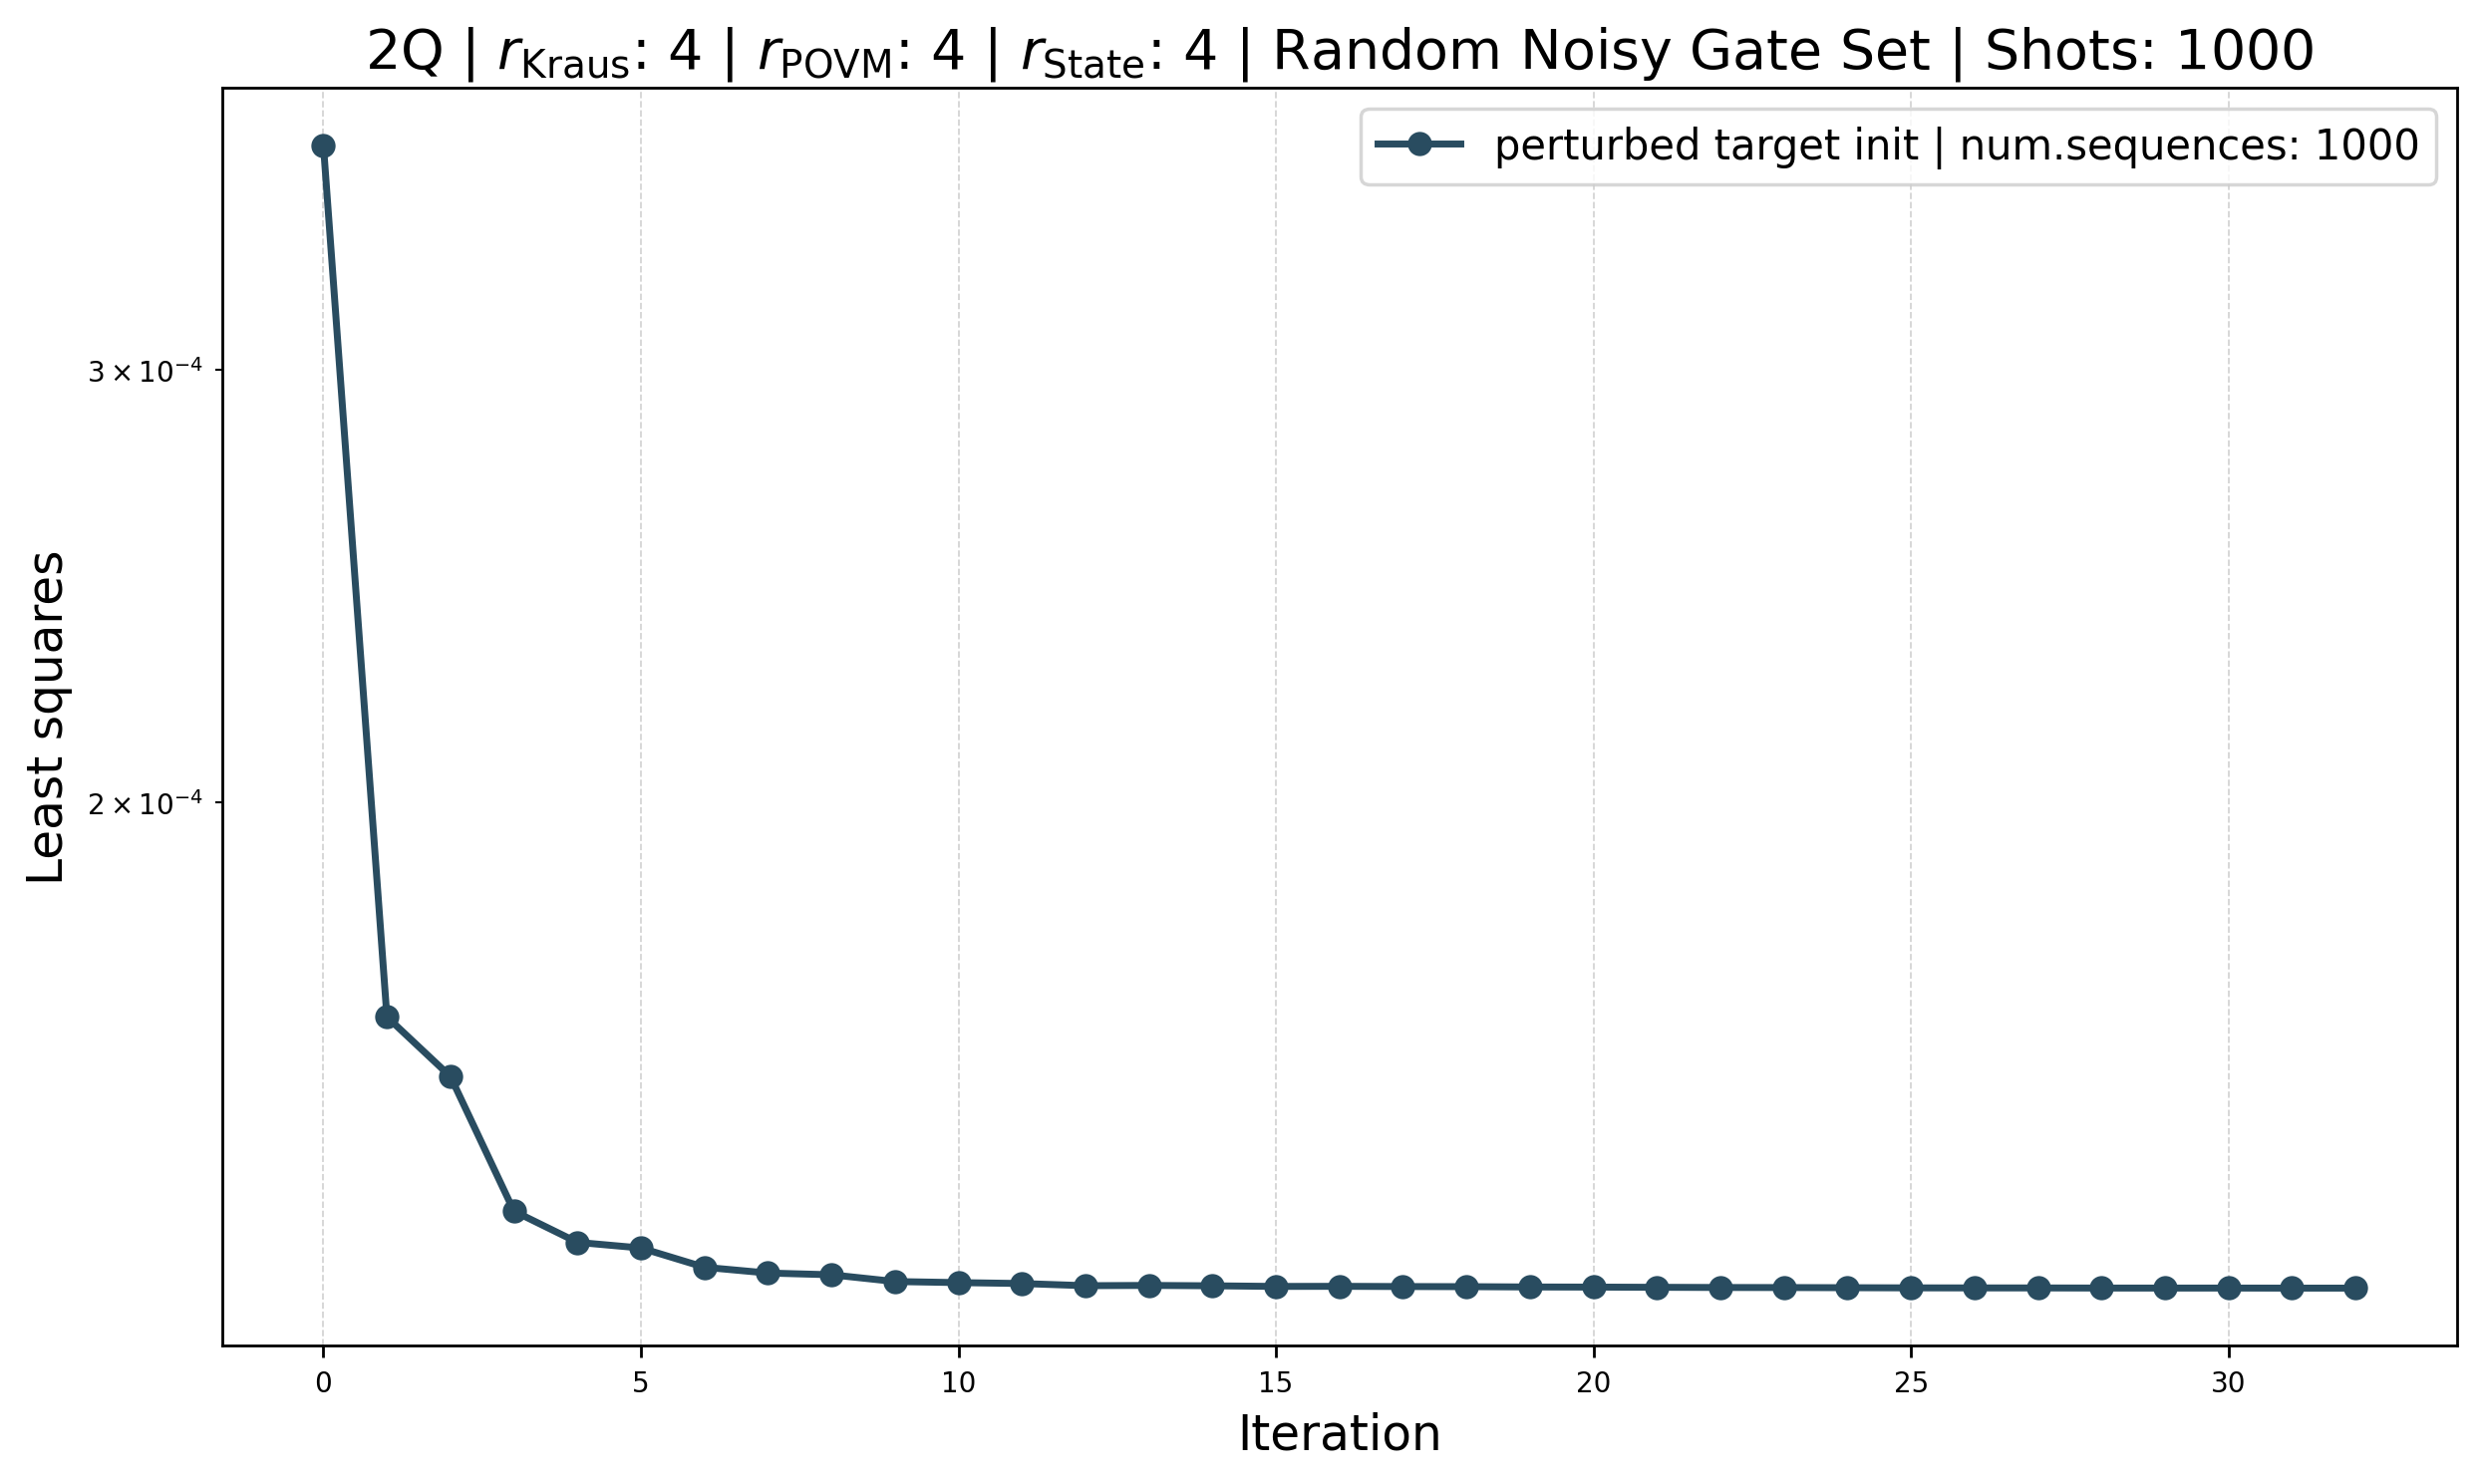

In [77]:
plot_cost_function([final_result_test["cost_fn_history"]["least_squares"]], title=title_init, labels=labels, ylabel="Least squares")

In [82]:
final_result_test.keys()

dict_keys(['optimized_operators', 'cost_fn_history', 'probability_matrices', 'indices_dict', 'times', 'convergence_reason', 'init_operators', 'superops_gauged', 'target_model_pygsti'])

In [88]:
mve_results_test, wve_results_test = compute_mve_and_wve_from_optimization_results(
            optimization_results_dict={num_seq_good: final_result_test},
            true_superops=noisy_gate_set_superop,
            sequence_length=mve_seq_length,
            num_circuits_sampled=num_circuits_sampled,
            num_repetitions=num_random_runs,
            verbose=False,
            which_data="optimized_operators",
        )
mve_results_test

{'1000': {'mean': Array(0.00376728, dtype=float64),
  'std': Array(4.57926501e-05, dtype=float64)}}

# Optimization over many realizations

In [ ]:
from mGST.simulate import generate_random_initial_operators
from mGST.trust_region import are_all_tensors_in_gate_set_isometries

# okay so this is not a problem
# it seems that the random (kraus) tensors are already drawn with that specific rank
# so compressing them back to that rank does not change their isometry property!
random_initial_operators_test = generate_random_initial_operators(
    num_gates=num_gates,
    dim=dim,
    kraus_rank=kraus_rank,
    povm_rank=povm_rank,
    state_rank=state_rank
)
are_all_tensors_in_gate_set_isometries(random_initial_operators_test)

True

In [155]:
final_results_0, partial_results_0 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[100, 150],
    num_realizations=2,
    num_max_iterations_random_inits=10,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/2
  📊 num_sequences=100
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 1/10. f(x) on full data: 3.516020e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 2/10. f(x) on full data: 1.914298e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 3/10. f(x) on full data: 1.046245e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 4/10. f(x) on full 

In [144]:
final_results_2, partial_results_2 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[500, 550],
    num_realizations=num_realizations,
    num_max_iterations_random_inits=10,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/5
  📊 num_sequences=500
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 1/10. f(x) on full data: 4.124467e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 2/10. f(x) on full data: 3.632932e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 3/10. f(x) on full data: 3.122876e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 4/10. f(x) on full 

In [137]:
final_results_1, partial_results_1 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[600, 650],
    num_realizations=2,
    num_max_iterations_random_inits=10,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/2
  📊 num_sequences=600
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 1/10. f(x) on full data: 3.984704e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 2/10. f(x) on full data: 3.688626e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 3/10. f(x) on full data: 3.070940e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 4/10. f(x) on full 

In [130]:
final_results_3, partial_results_3 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[700, 750],
    num_realizations=2,
    num_max_iterations_random_inits=10, # double to see if this helps
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/2
  📊 num_sequences=700
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 1/10. f(x) on full data: 3.825898e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 2/10. f(x) on full data: 3.517233e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 3/10. f(x) on full data: 3.252241e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 4/10. f(x) on full 

In [111]:
final_results_4, partial_results_4 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[1000],
    num_realizations=2, # we have 10 random inits x 2 realizations = 20 total runs, should be enough
    num_max_iterations_random_inits=num_max_iterations_random_inits,
    num_max_random_inits=num_max_random_inits,
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/2
  📊 num_sequences=1000
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
🏁 Iteration 1/5. f(x) on full data: 4.543229e-02.
🏁 Iteration 2/5. f(x) on full data: 3.892643e-02.
🏁 Iteration 3/5. f(x) on full data: 3.468989e-02.
🏁 Iteration 4/5. f(x) on full data: 3.215612e-02.
🏁 Iteration 5/5. f(x) on full data: 3.267702e-02.
🎲👾 Running optimization workflow with random initialization 2/10 🎲👾
🏁 Iteration 1/5. f(x) on full data: 4.316541e-02.
🏁 Iteration 2/5. f(x) on full data: 3.759018e-02.
🏁 Iteration 3/5. f(x) on full data: 3.106781e-02.
🏁 Iteration 4/5. f(x) on full data: 3.167611e-02.
🏁 Iteration 5/5. f(x) on full data: 3.158526e-02.
🎲👾 Running optimization workflow with random initialization 3/10 🎲👾
🏁 Iteration 1/5. f(x) on full data: 4.323597e-02.
🏁 Iteration 2/5. f(x) on full data: 3.736308e-02.
🏁 Iteration 3/5. f(x) on full data: 3.396236e-02.
🏁 Iteration 4/5. f(x) on full data: 3.427119e-02.
🏁 Iteration 5/5. f(x) on full data: 3.360163e-02.
🎲👾 Ru

In [ ]:
final_results_5, partial_results_5 = run_optimization_workflow_multi_init_realizations(
    num_shots=num_shots,
    operators_psd_true=noisy_gate_set_psd,
    target_superops=target_gate_set_superops,
    optimization_options=optimization_options_silence,
    num_sequences_list=[1000],
    num_realizations=2, # we have 10 random inits x 2 realizations = 20 total runs, should be enough
    num_max_iterations_random_inits=20,
    num_max_random_inits=num_max_random_inits, # 10
    batch_size=batch_size,
    threshold_multiplier=threshold_multiplier,
    debug=True,     # also captures partial results
)

🔁 Realization 1/2
  📊 num_sequences=1000
🎲👾 Running optimization workflow with random initialization 1/10 🎲👾
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 1/20. f(x) on full data: 4.607554e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 2/20. f(x) on full data: 4.015752e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 3/20. f(x) on full data: 3.833228e-02.
‼️ Full optimization finished at iteration 1/1 ‼️ 
 Reason: No convergence criteria met yet ⏳.. 
 Trust region radii carried over: {'kraus': None, 'povm': None, 'state': None}.
🏁 Iteration 4/20. f(x) on full

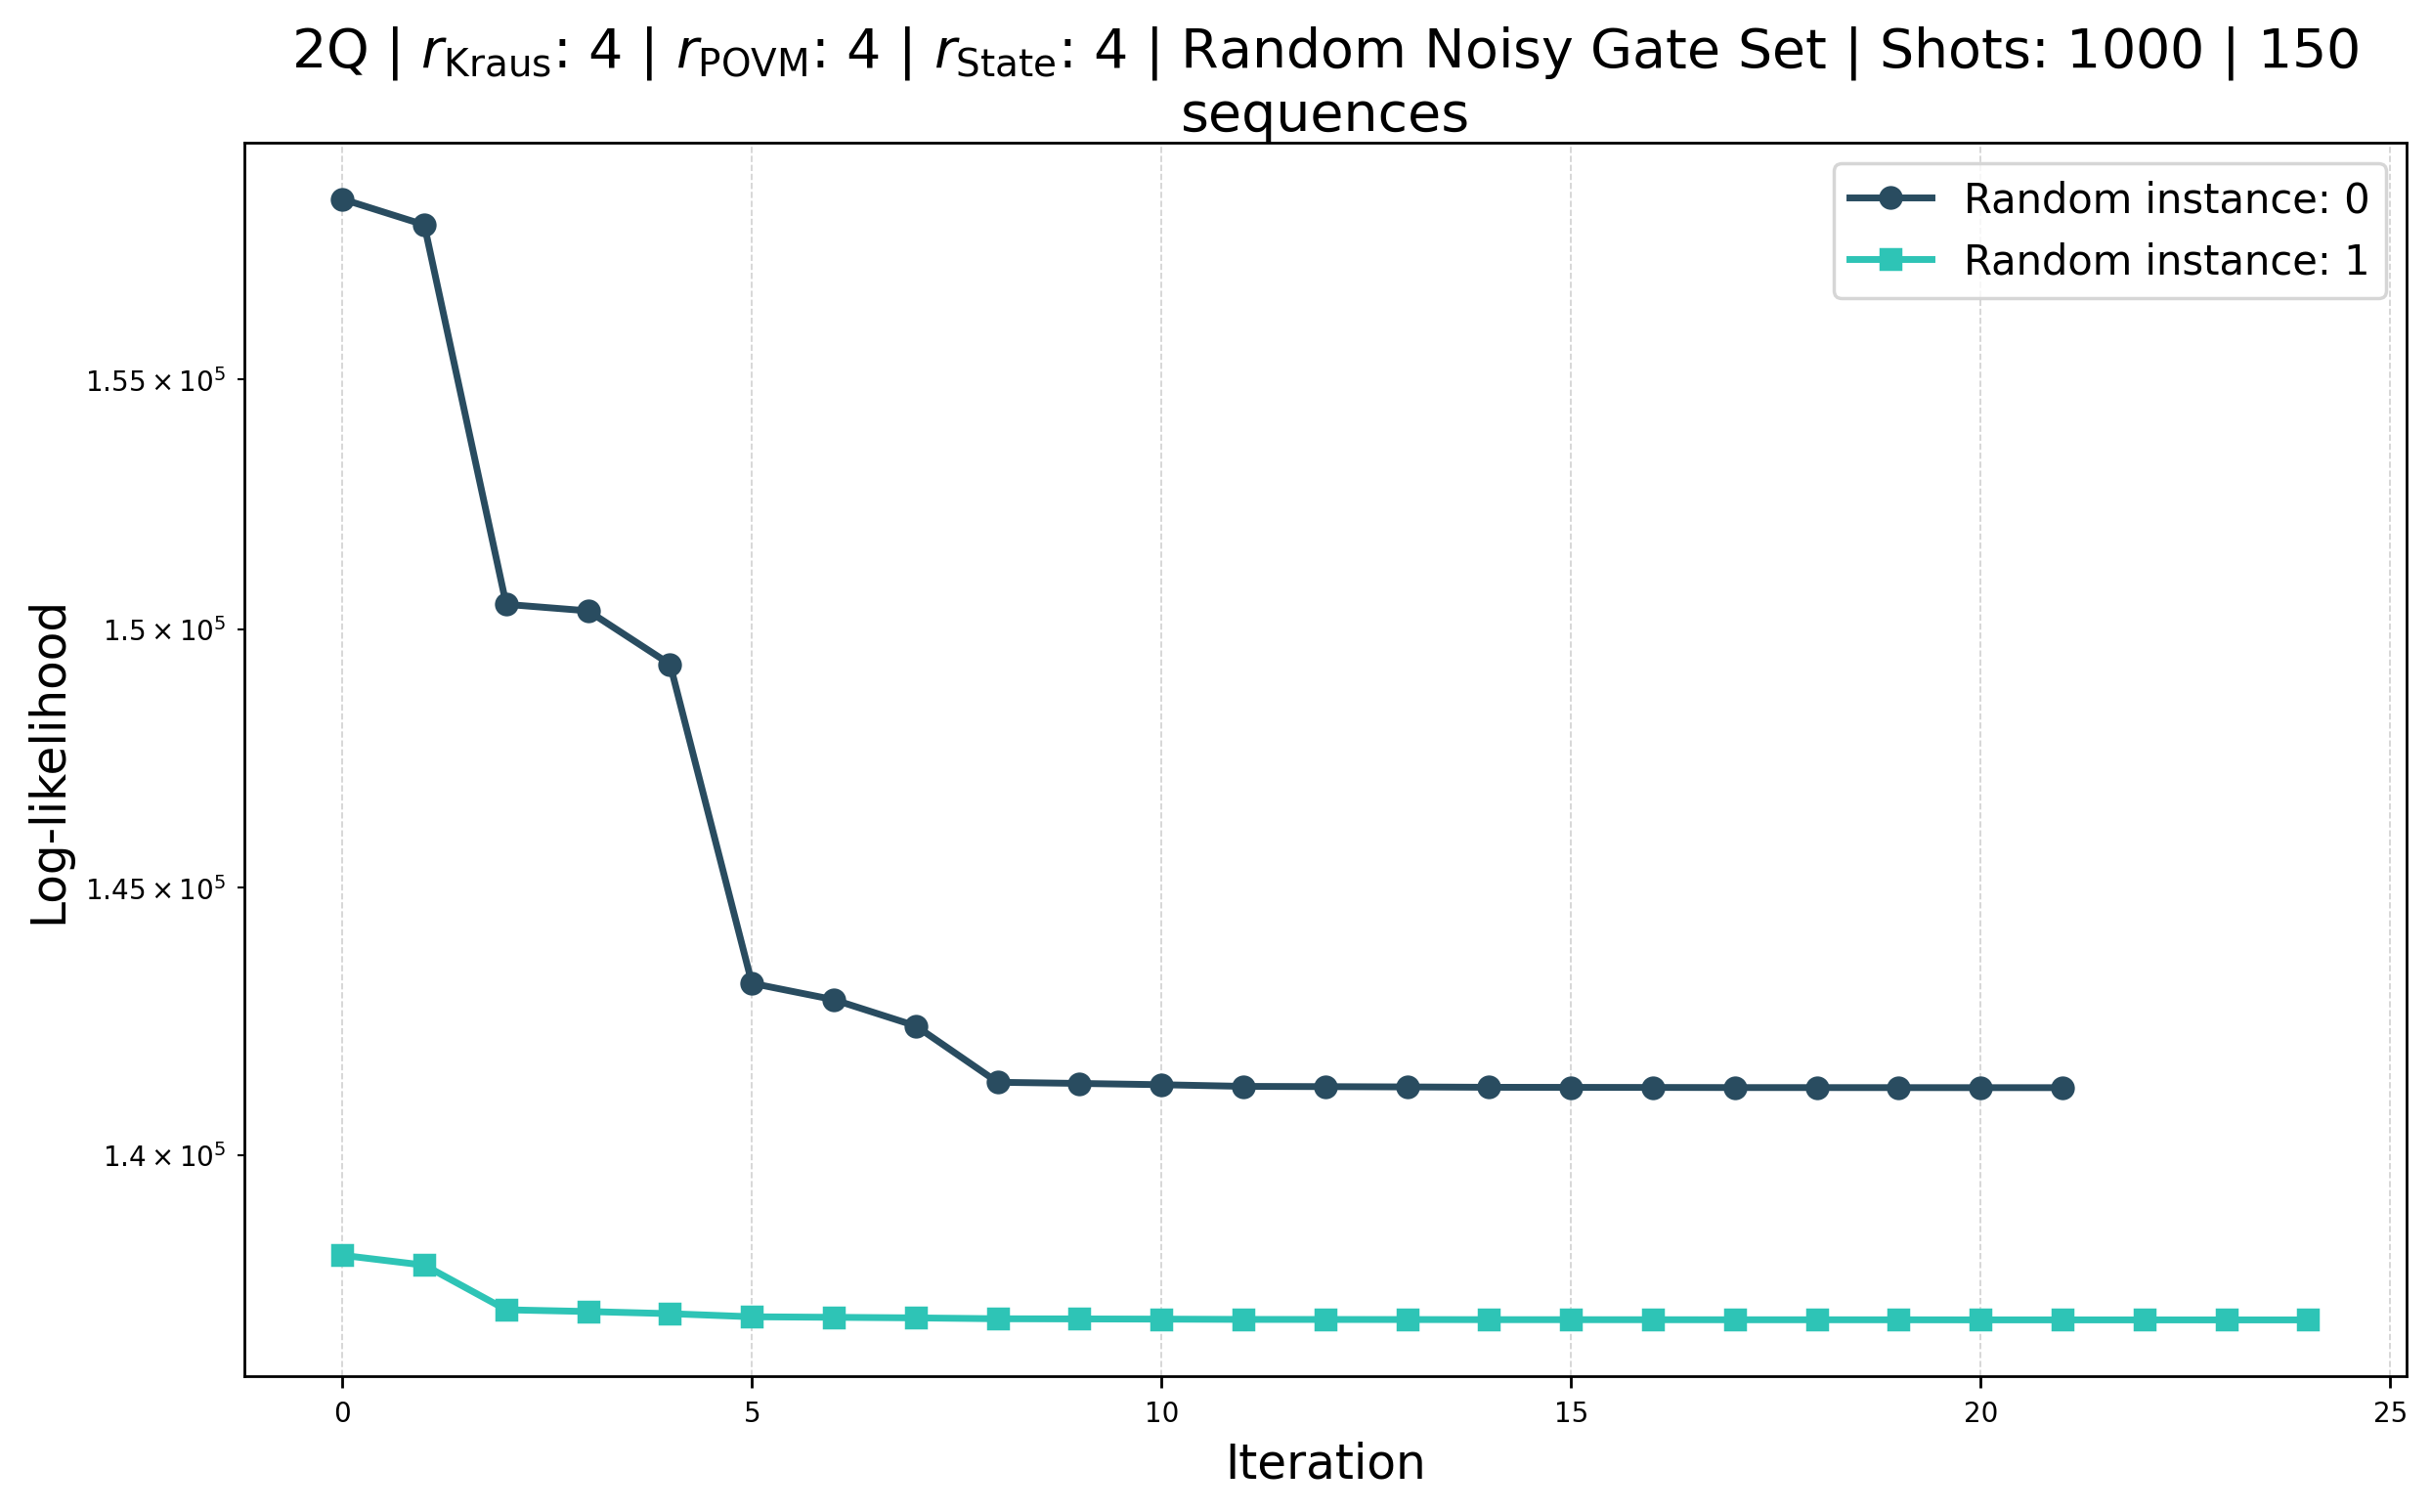

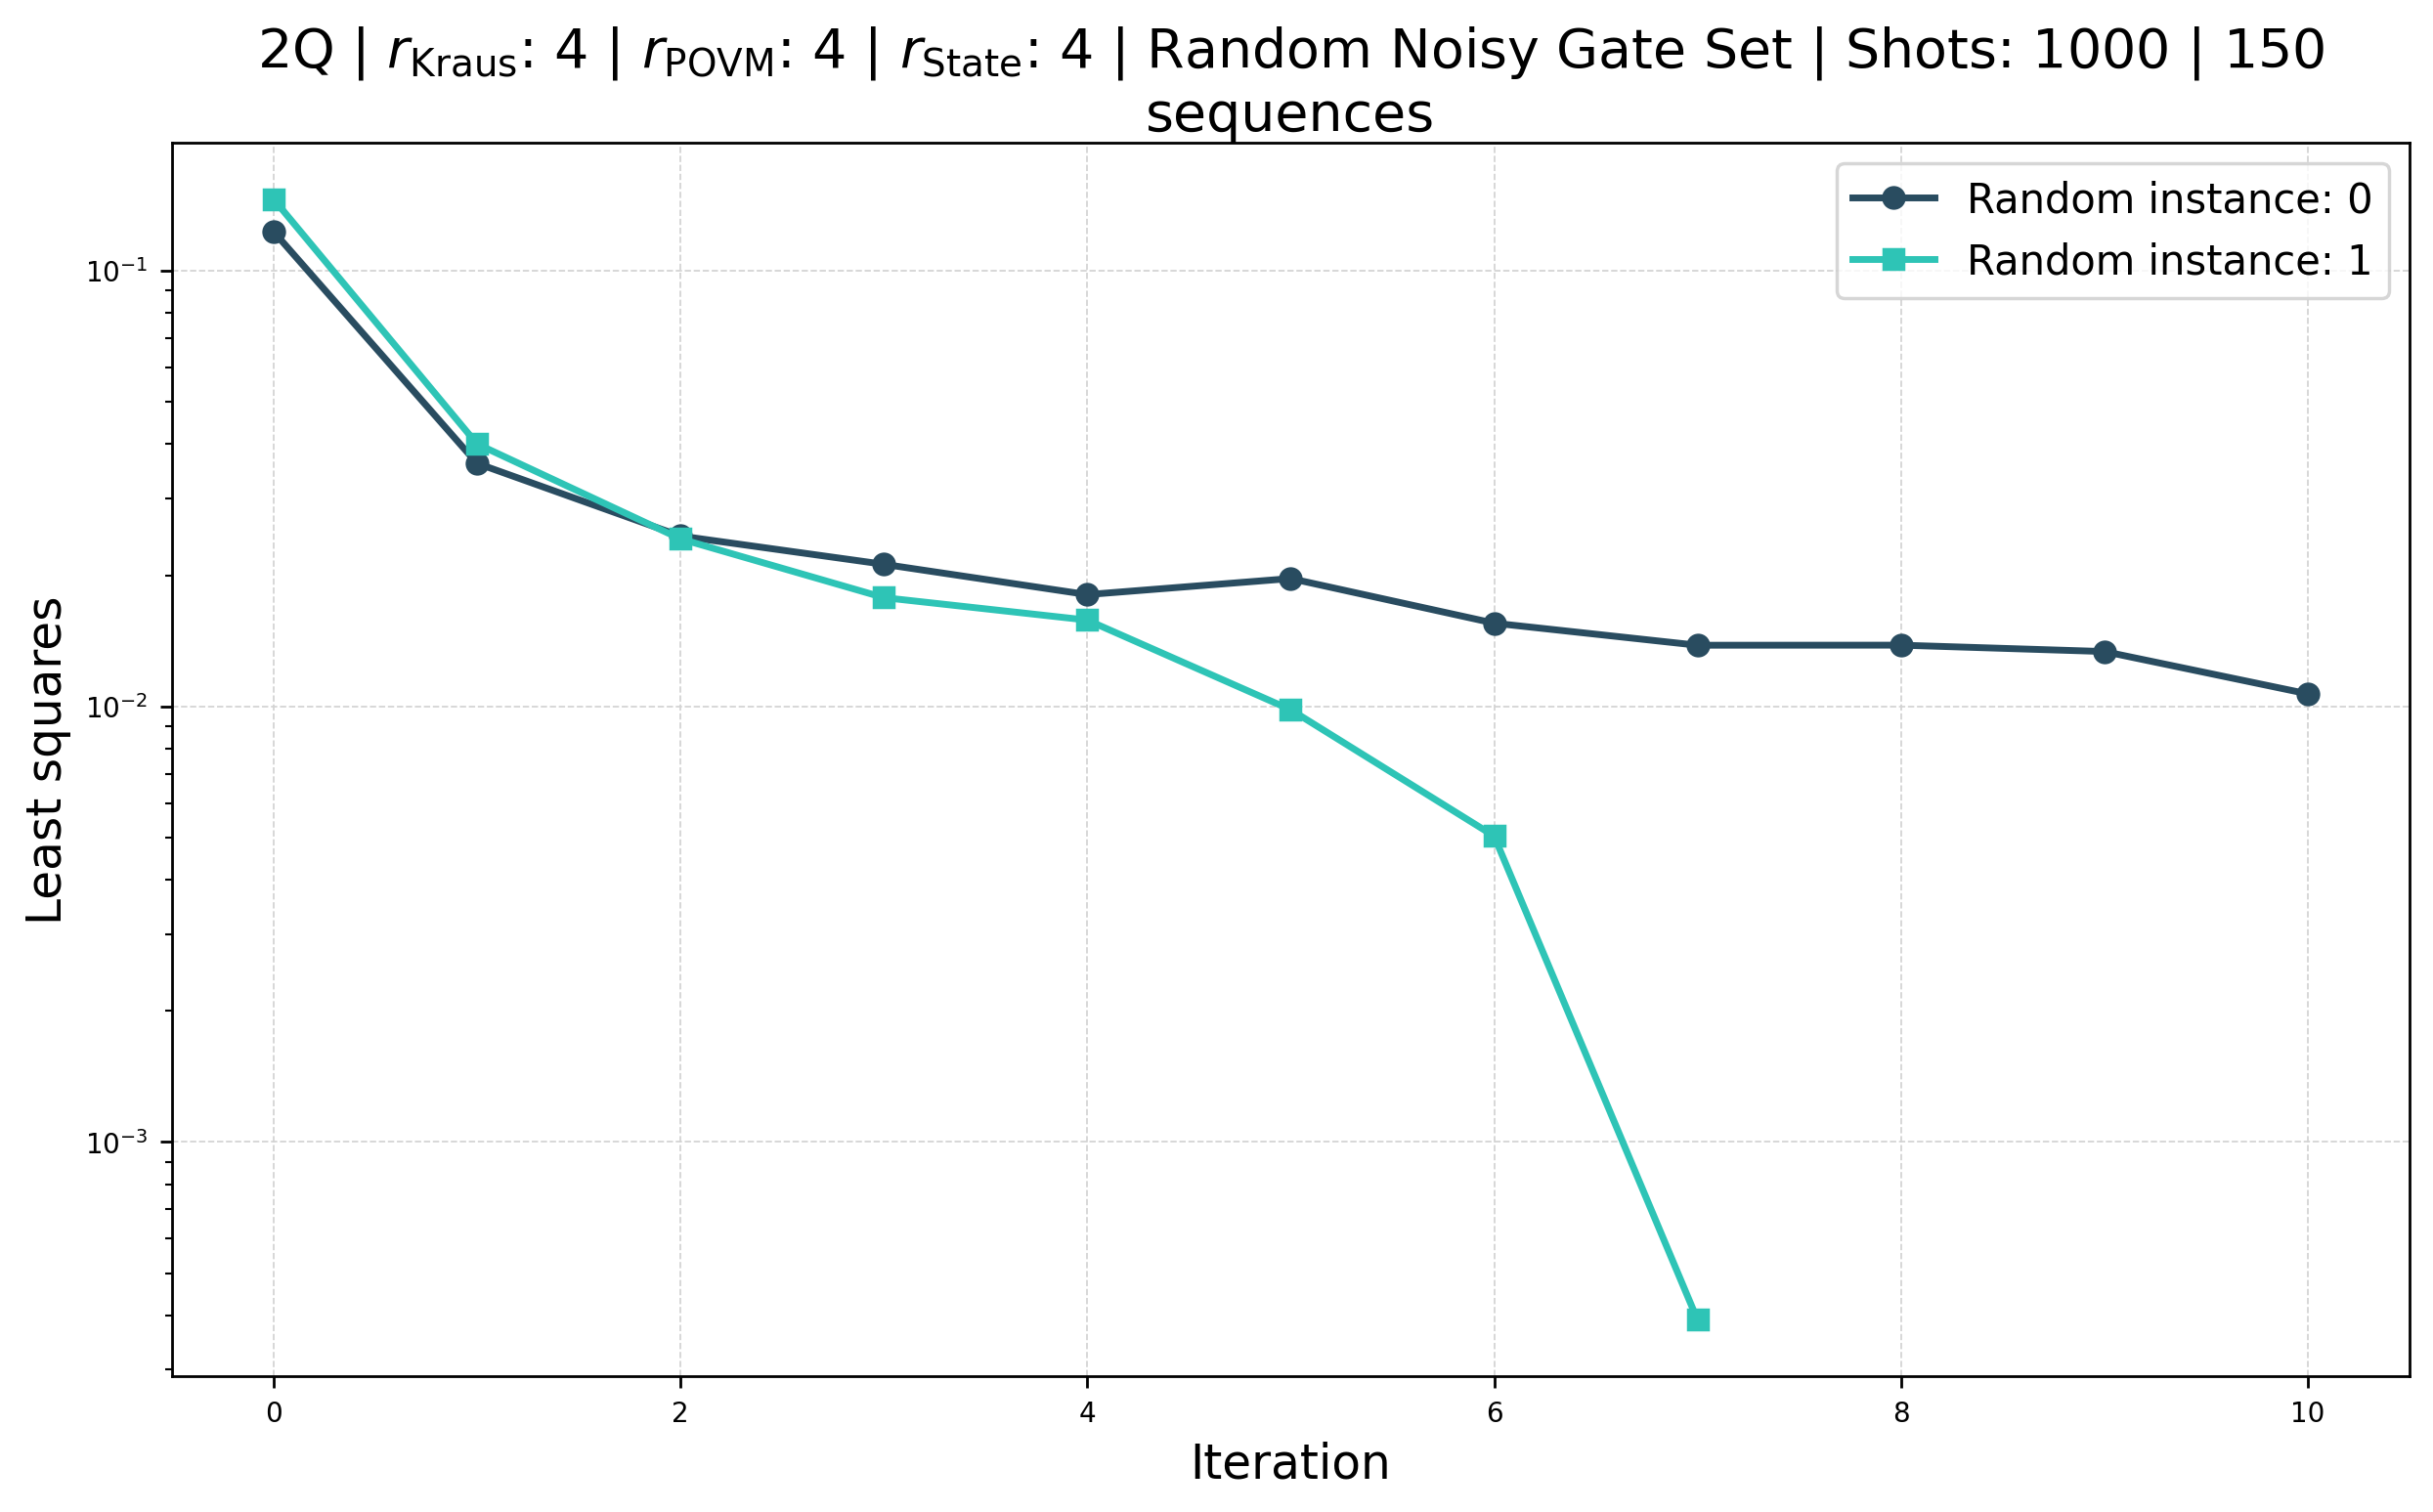

In [174]:
sequences_test = 150

final_results_test = get_all_realizations_for_key(final_results_0, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_0, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

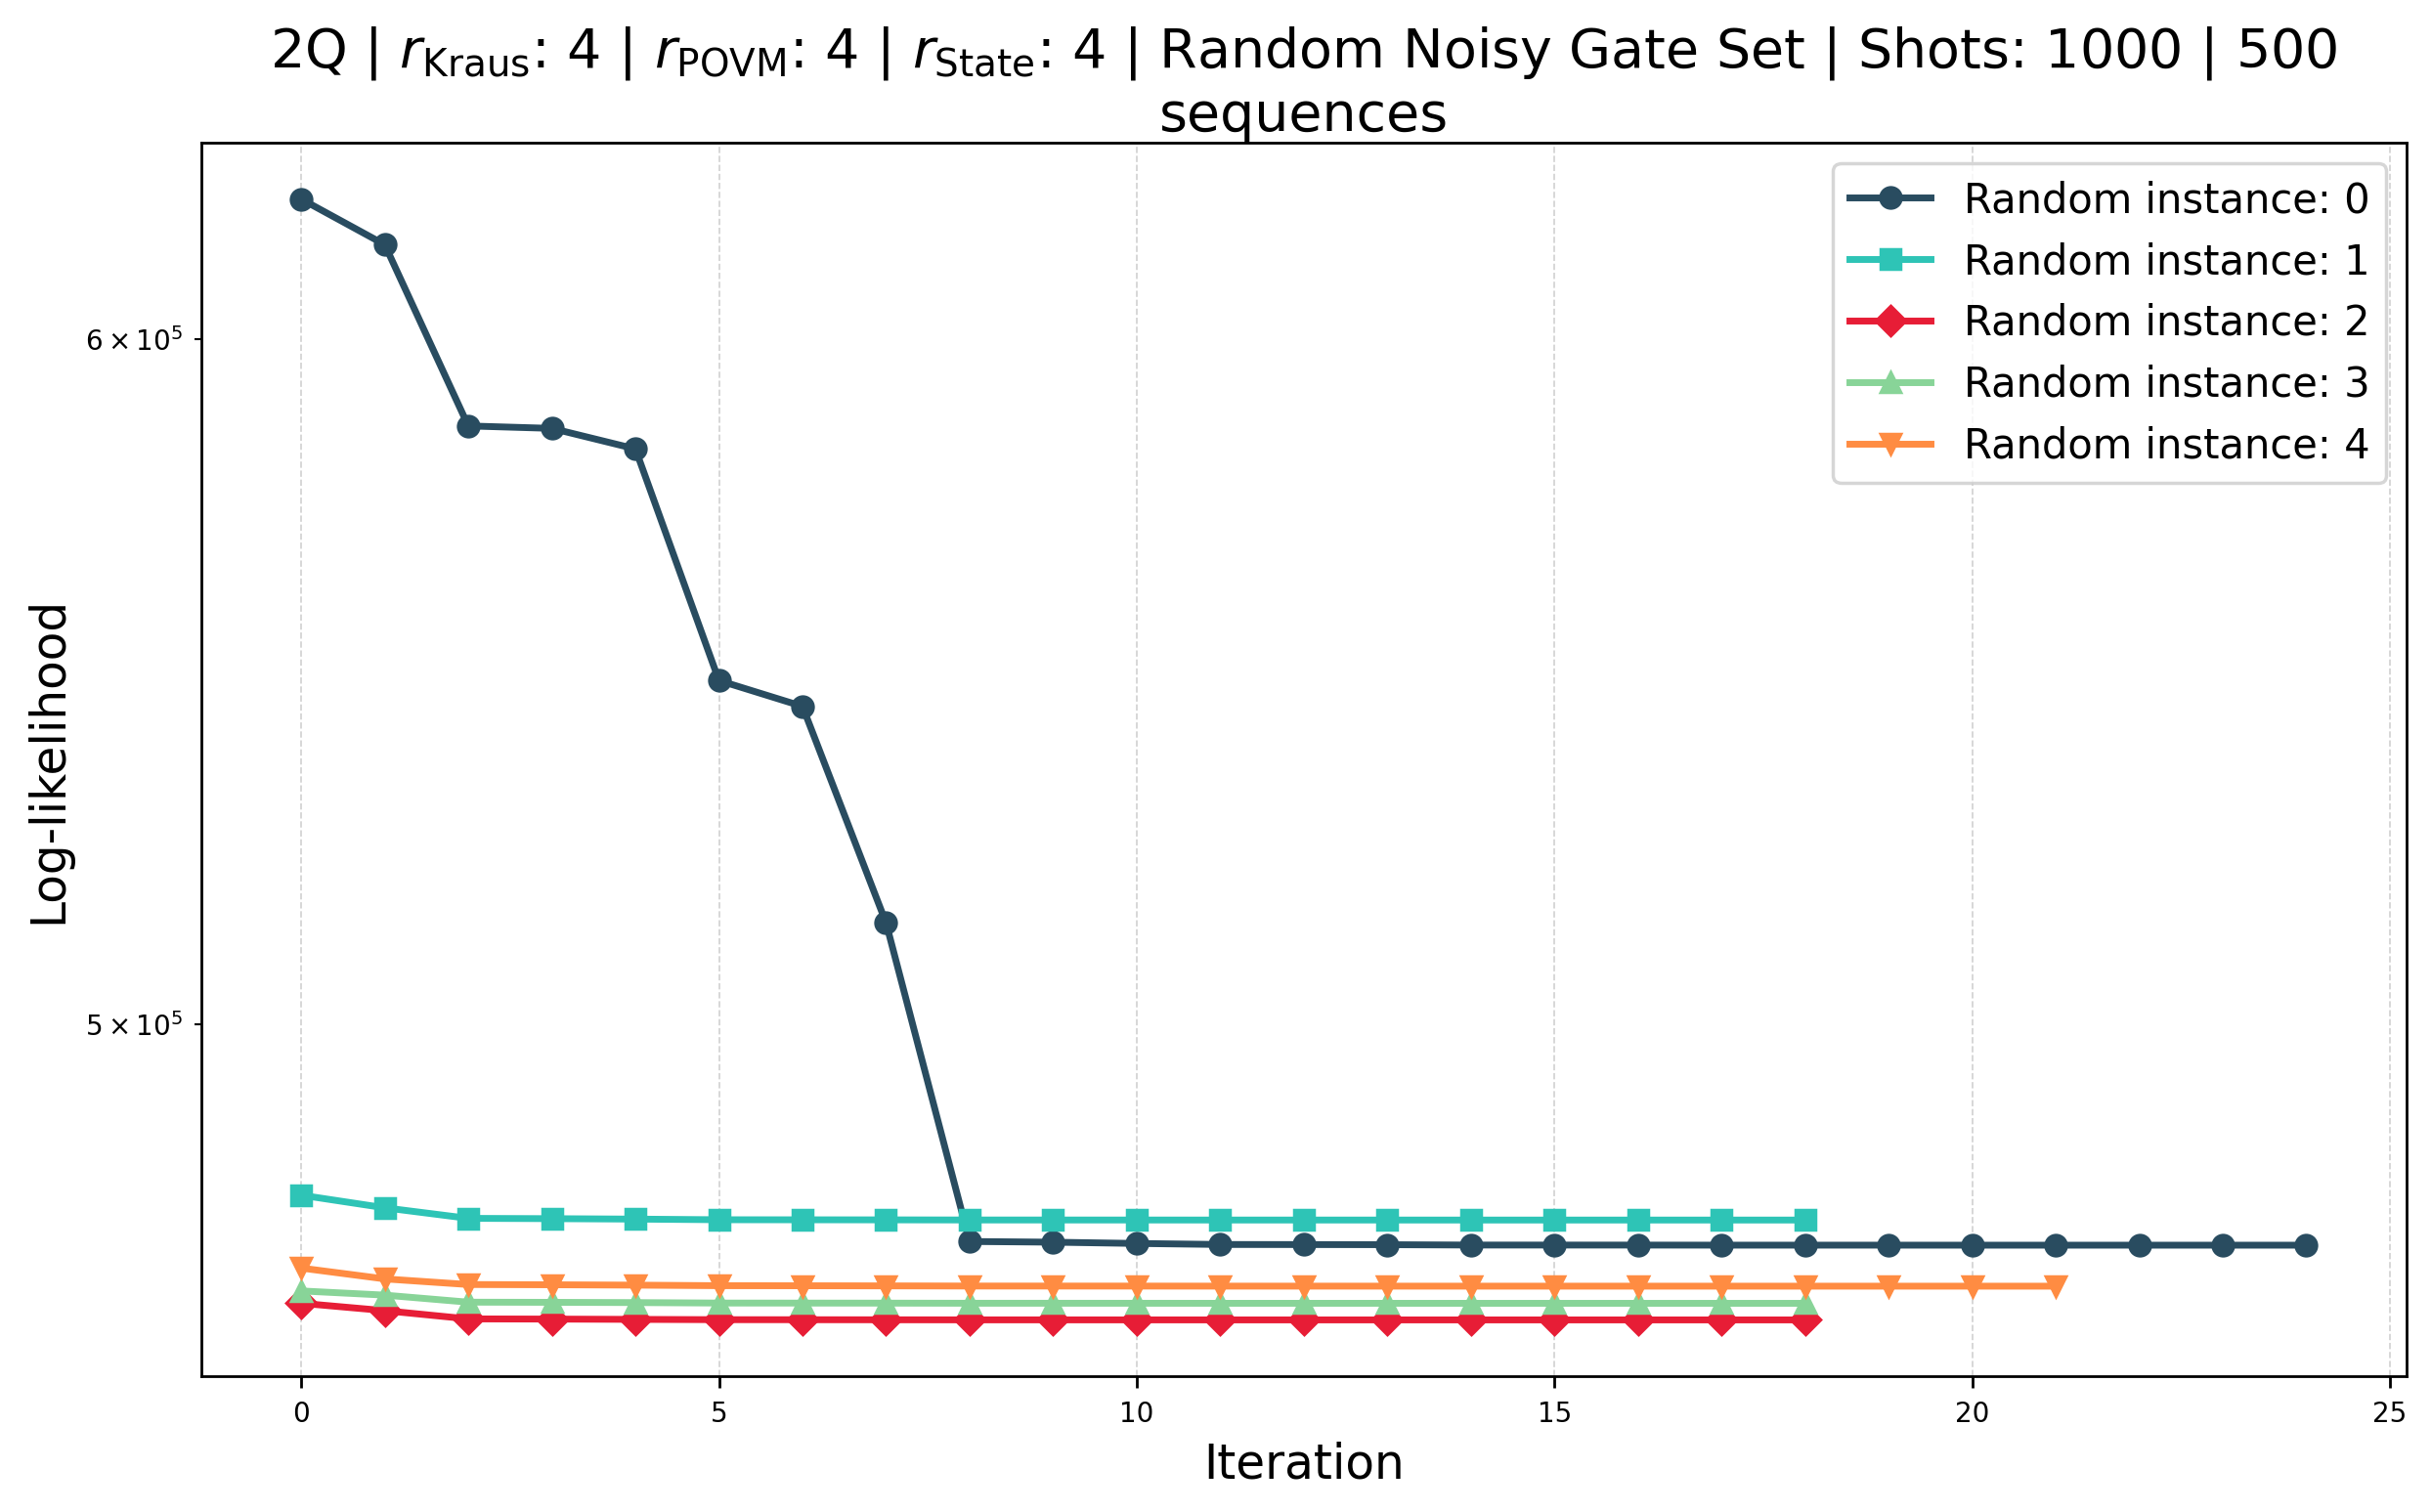

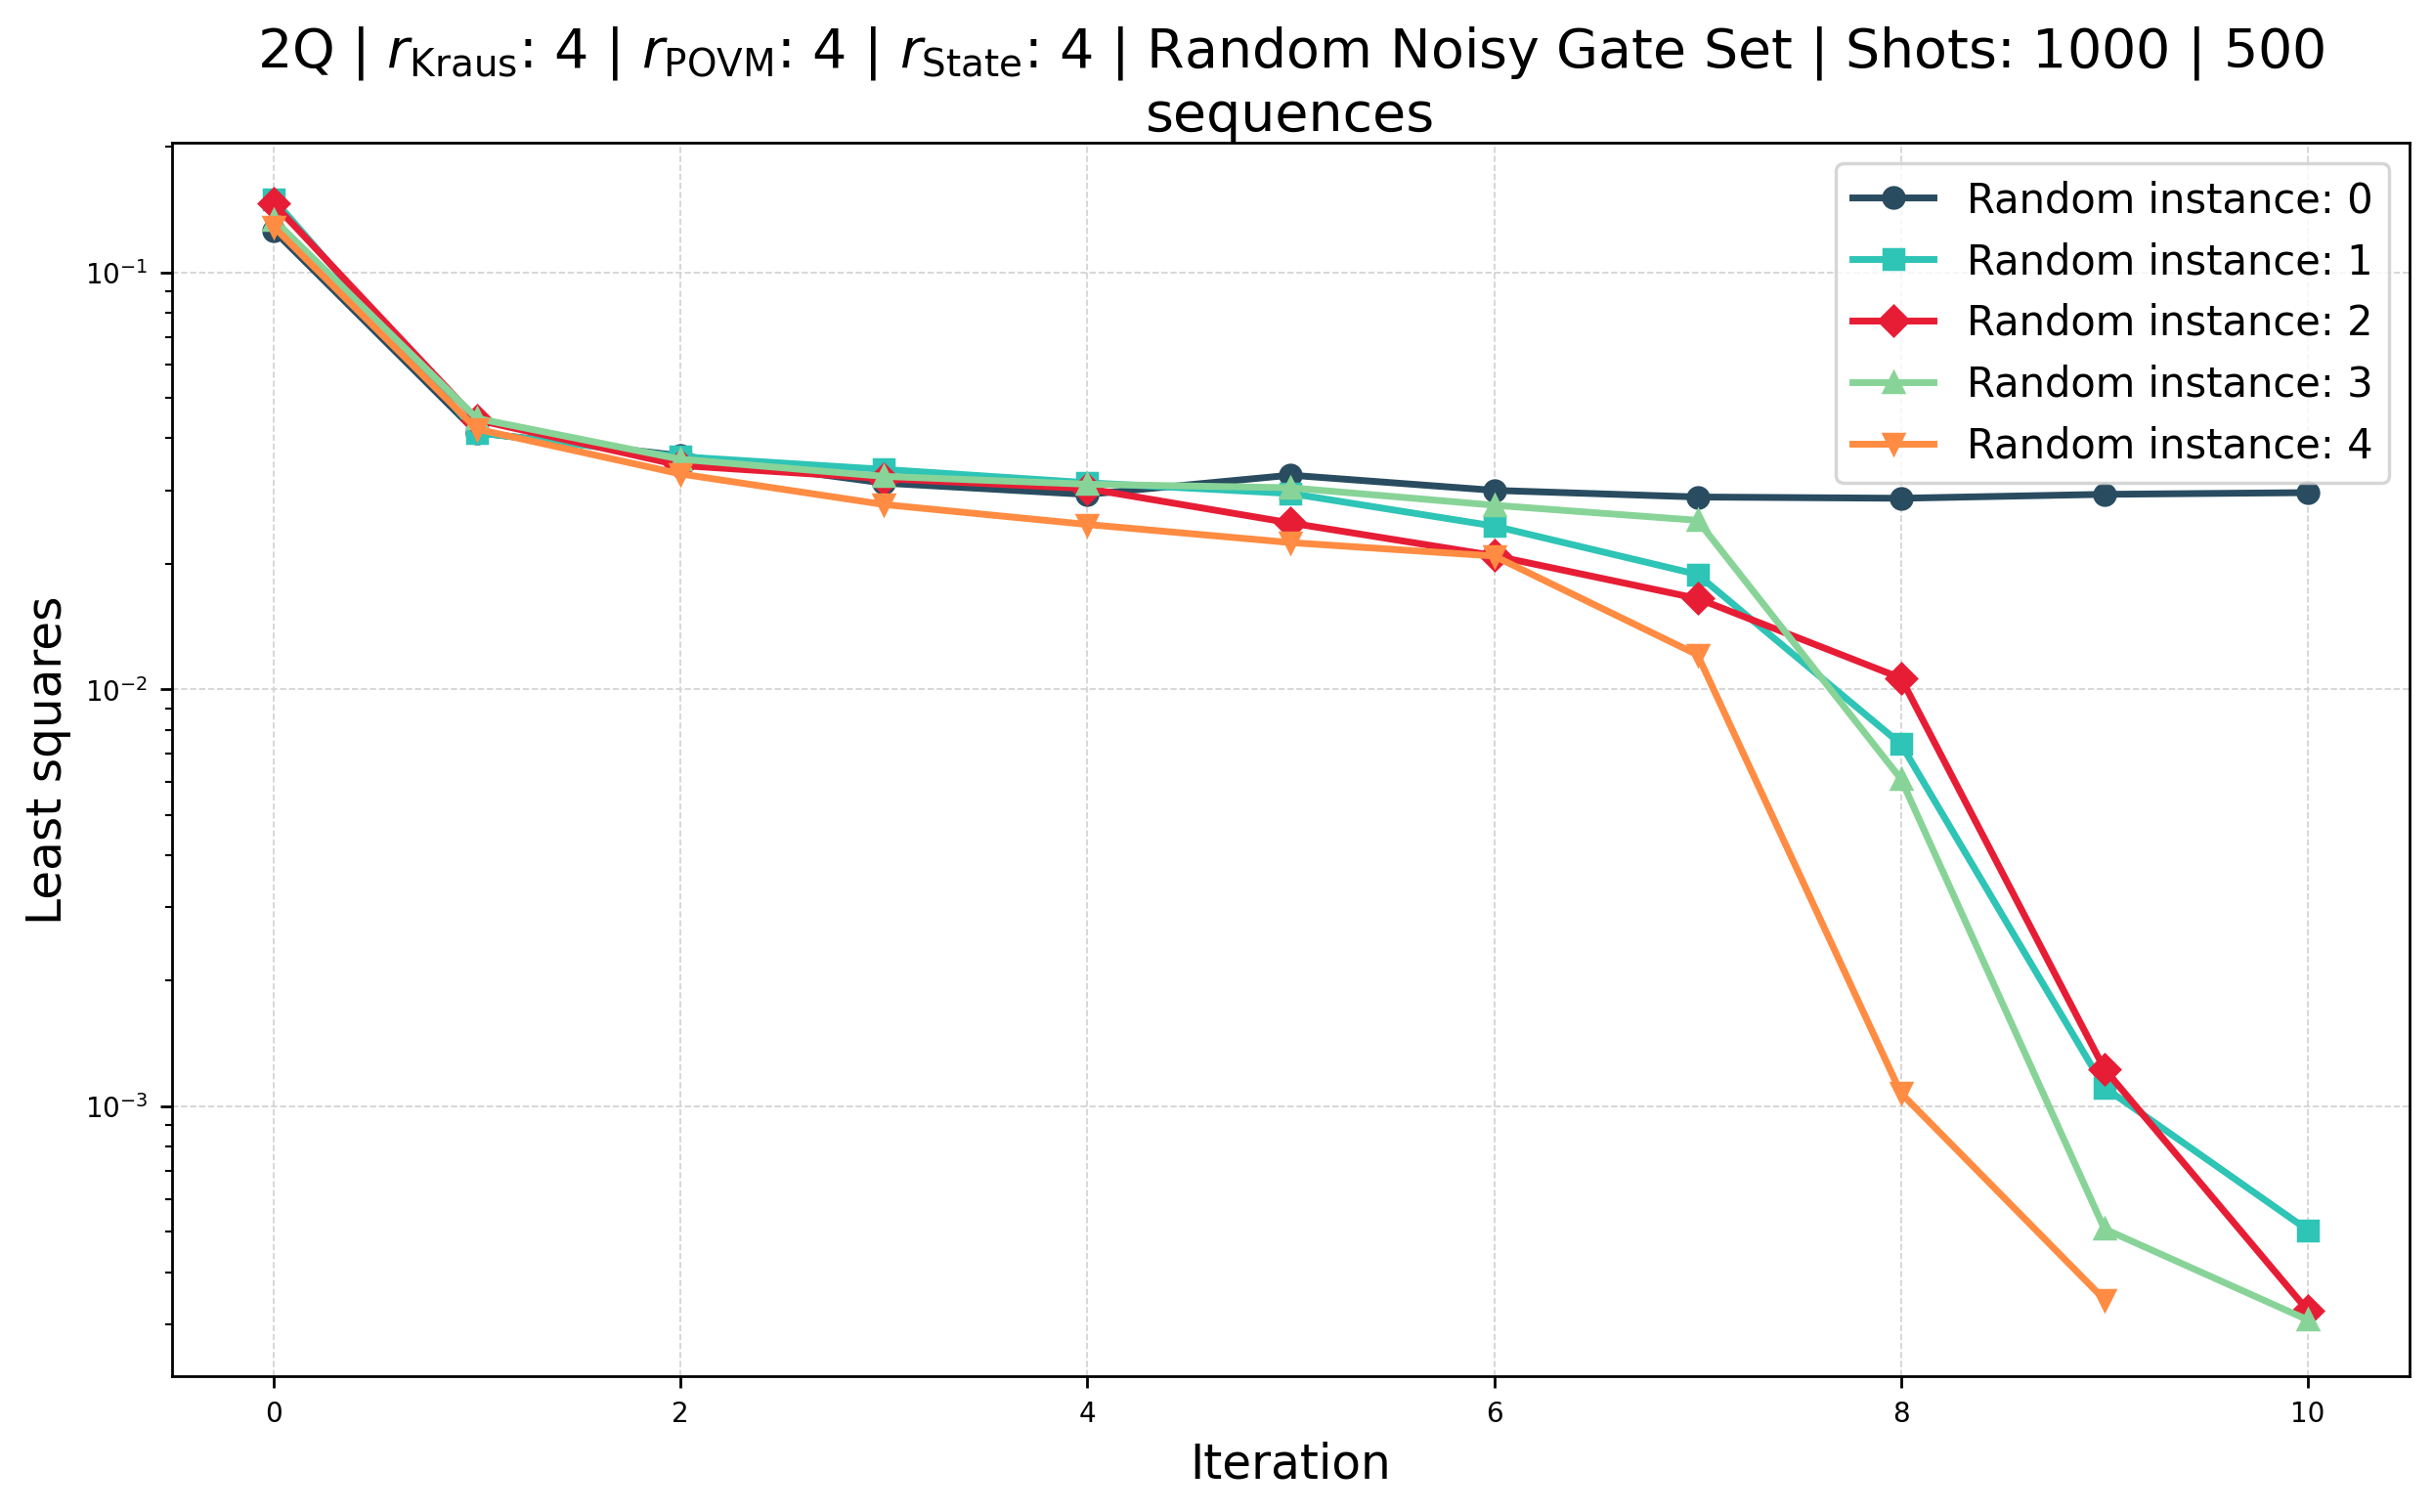

In [176]:
sequences_test = 500

final_results_test = get_all_realizations_for_key(final_results_2, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_2, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

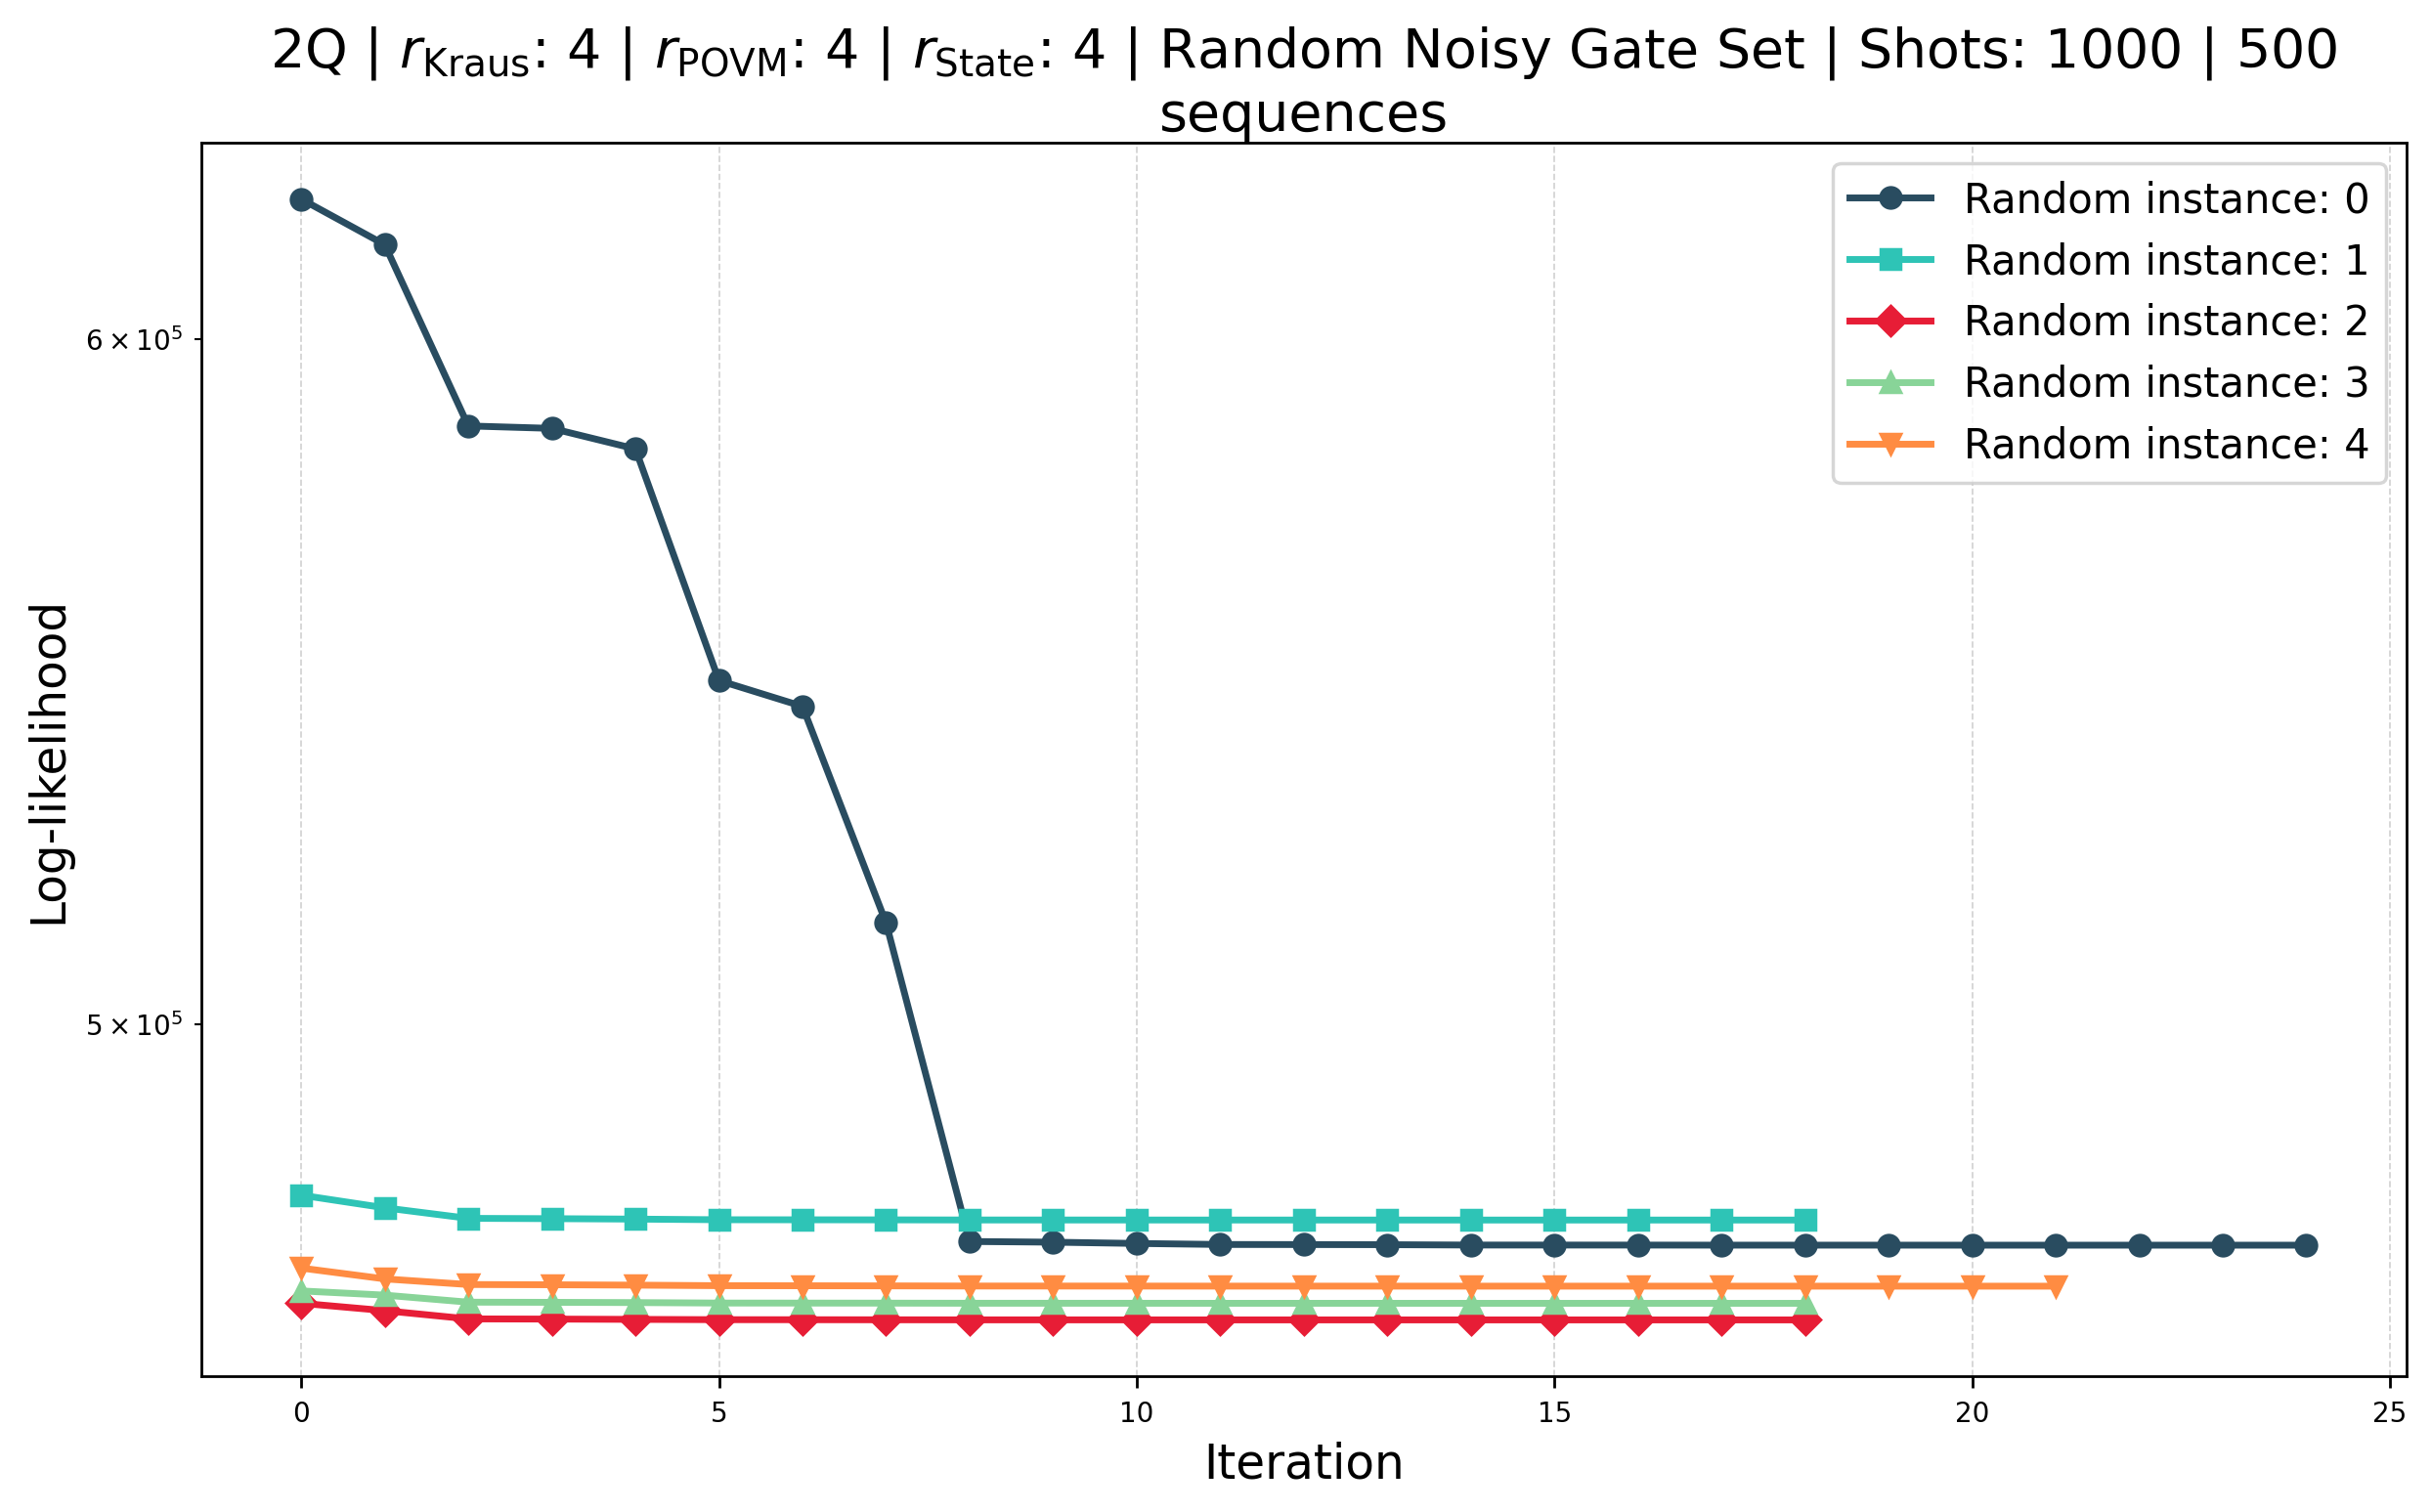

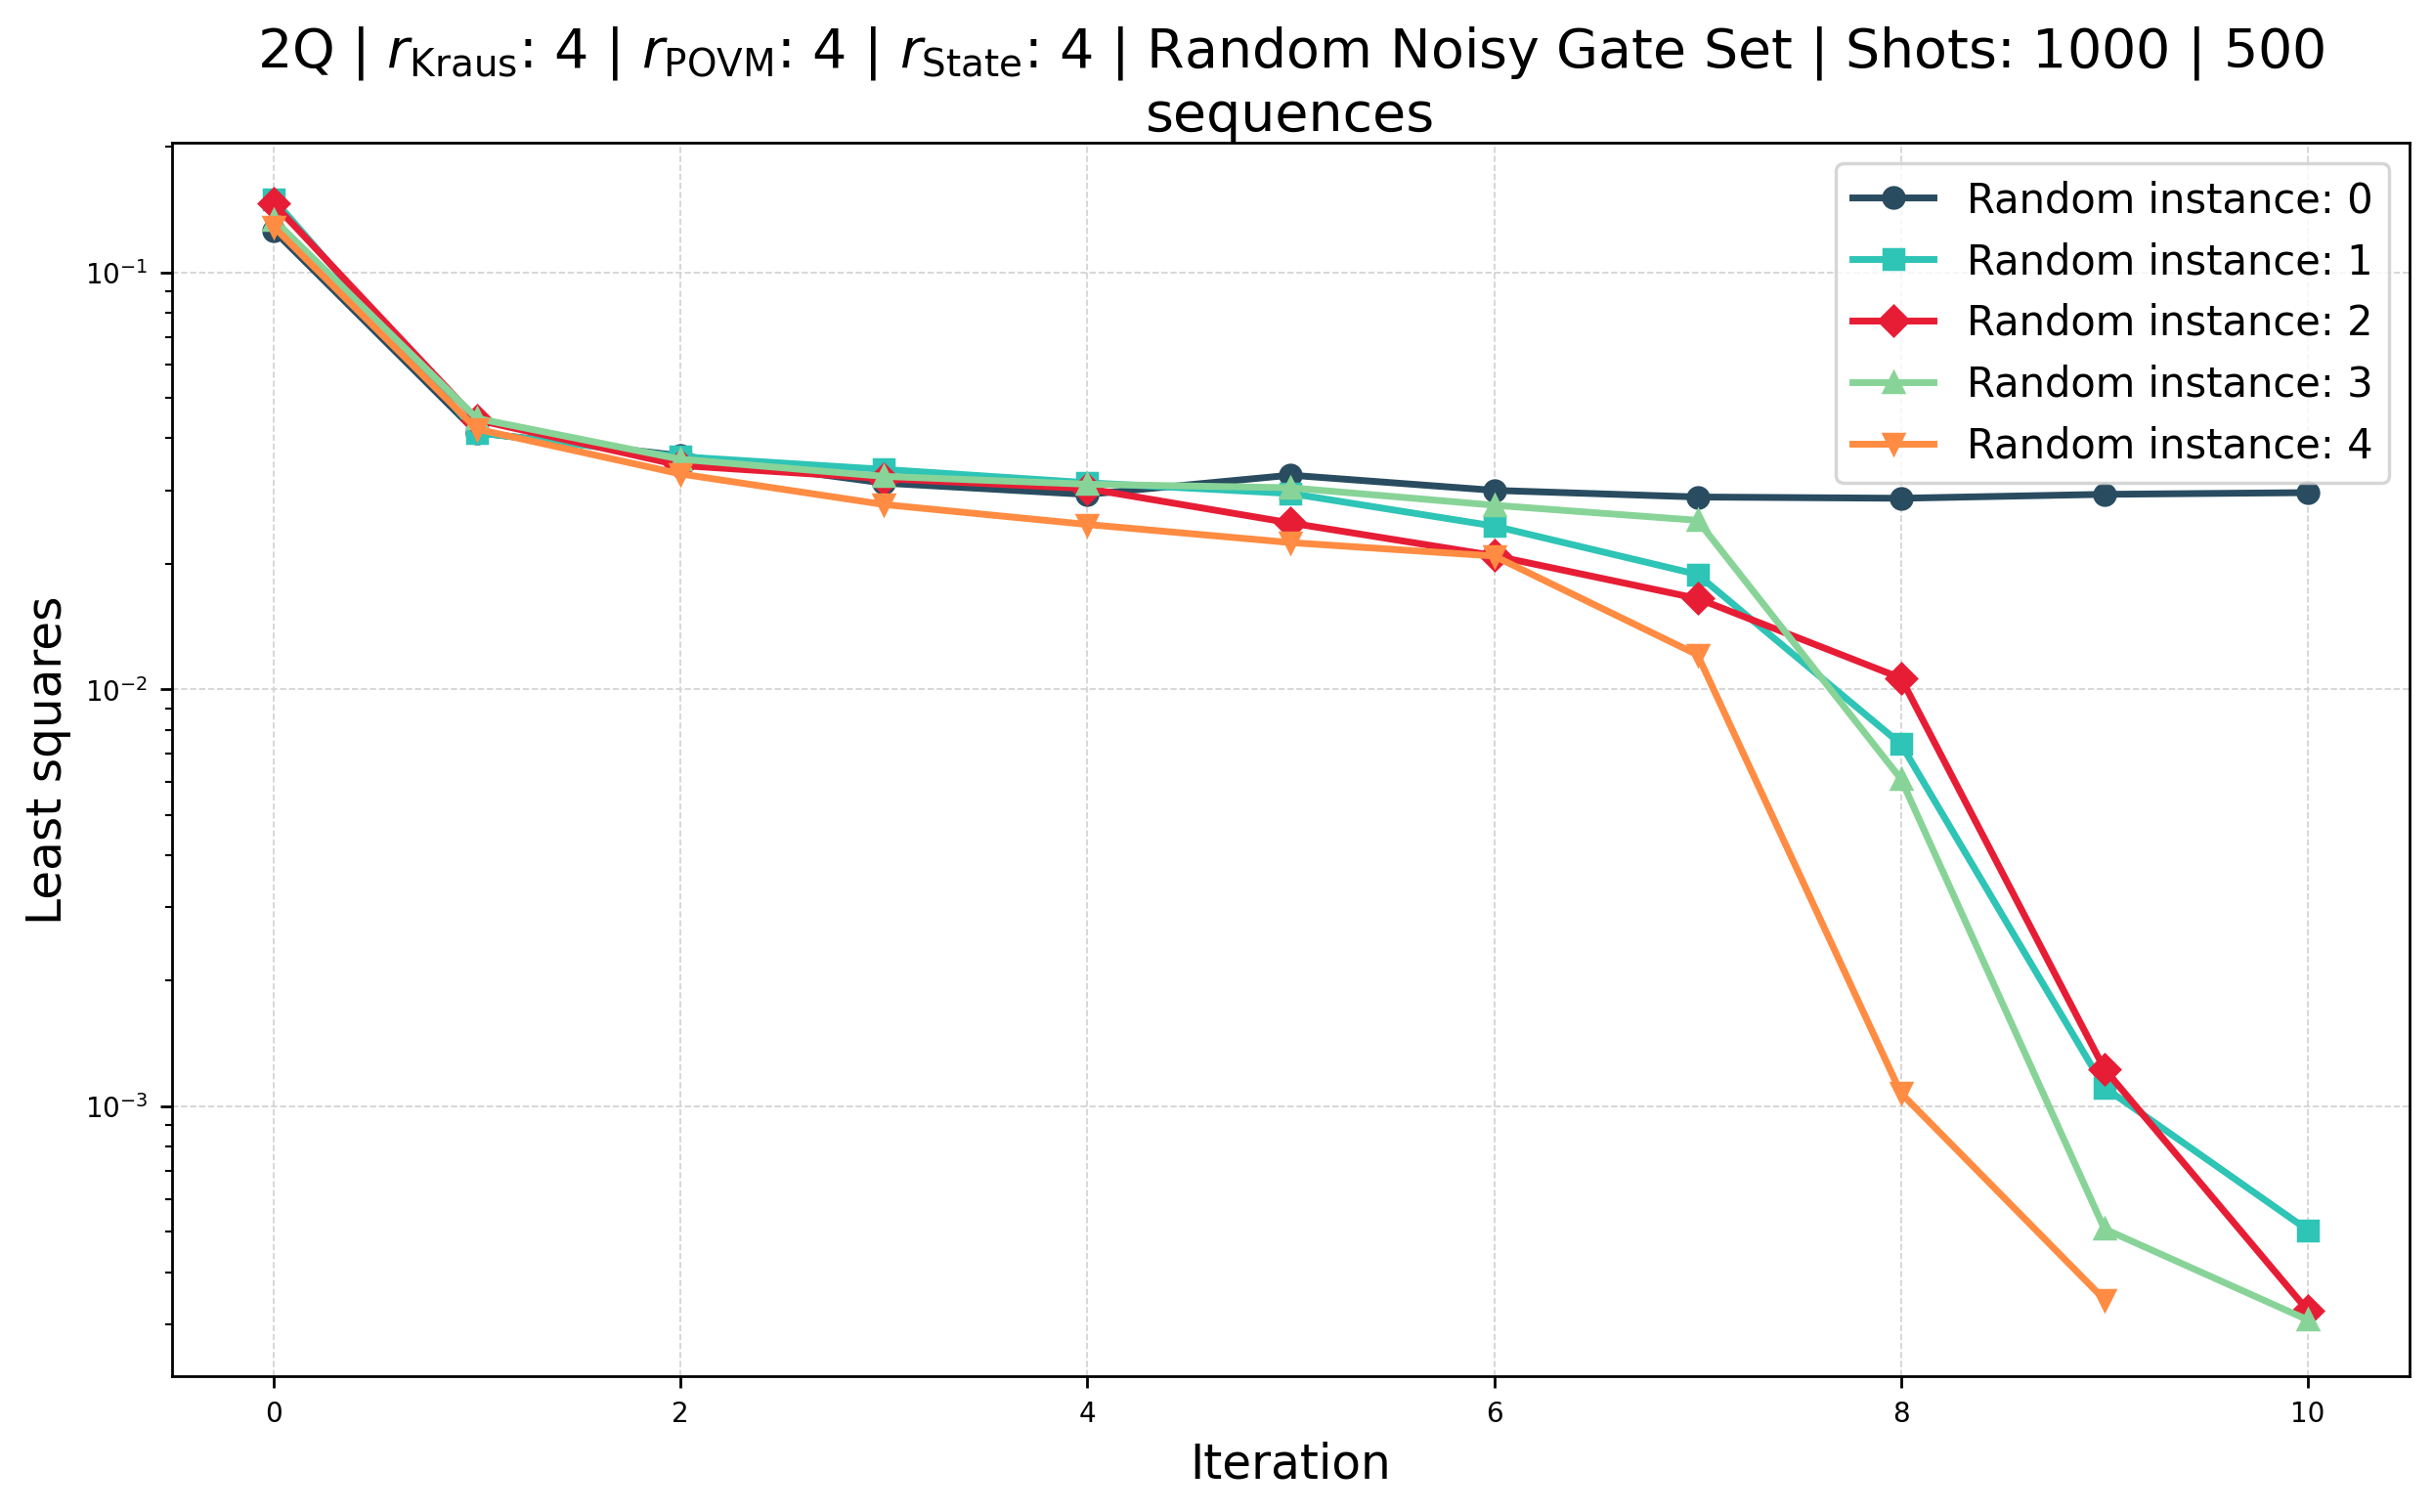

In [146]:
sequences_test = 500

final_results_test = get_all_realizations_for_key(final_results_2, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_2, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

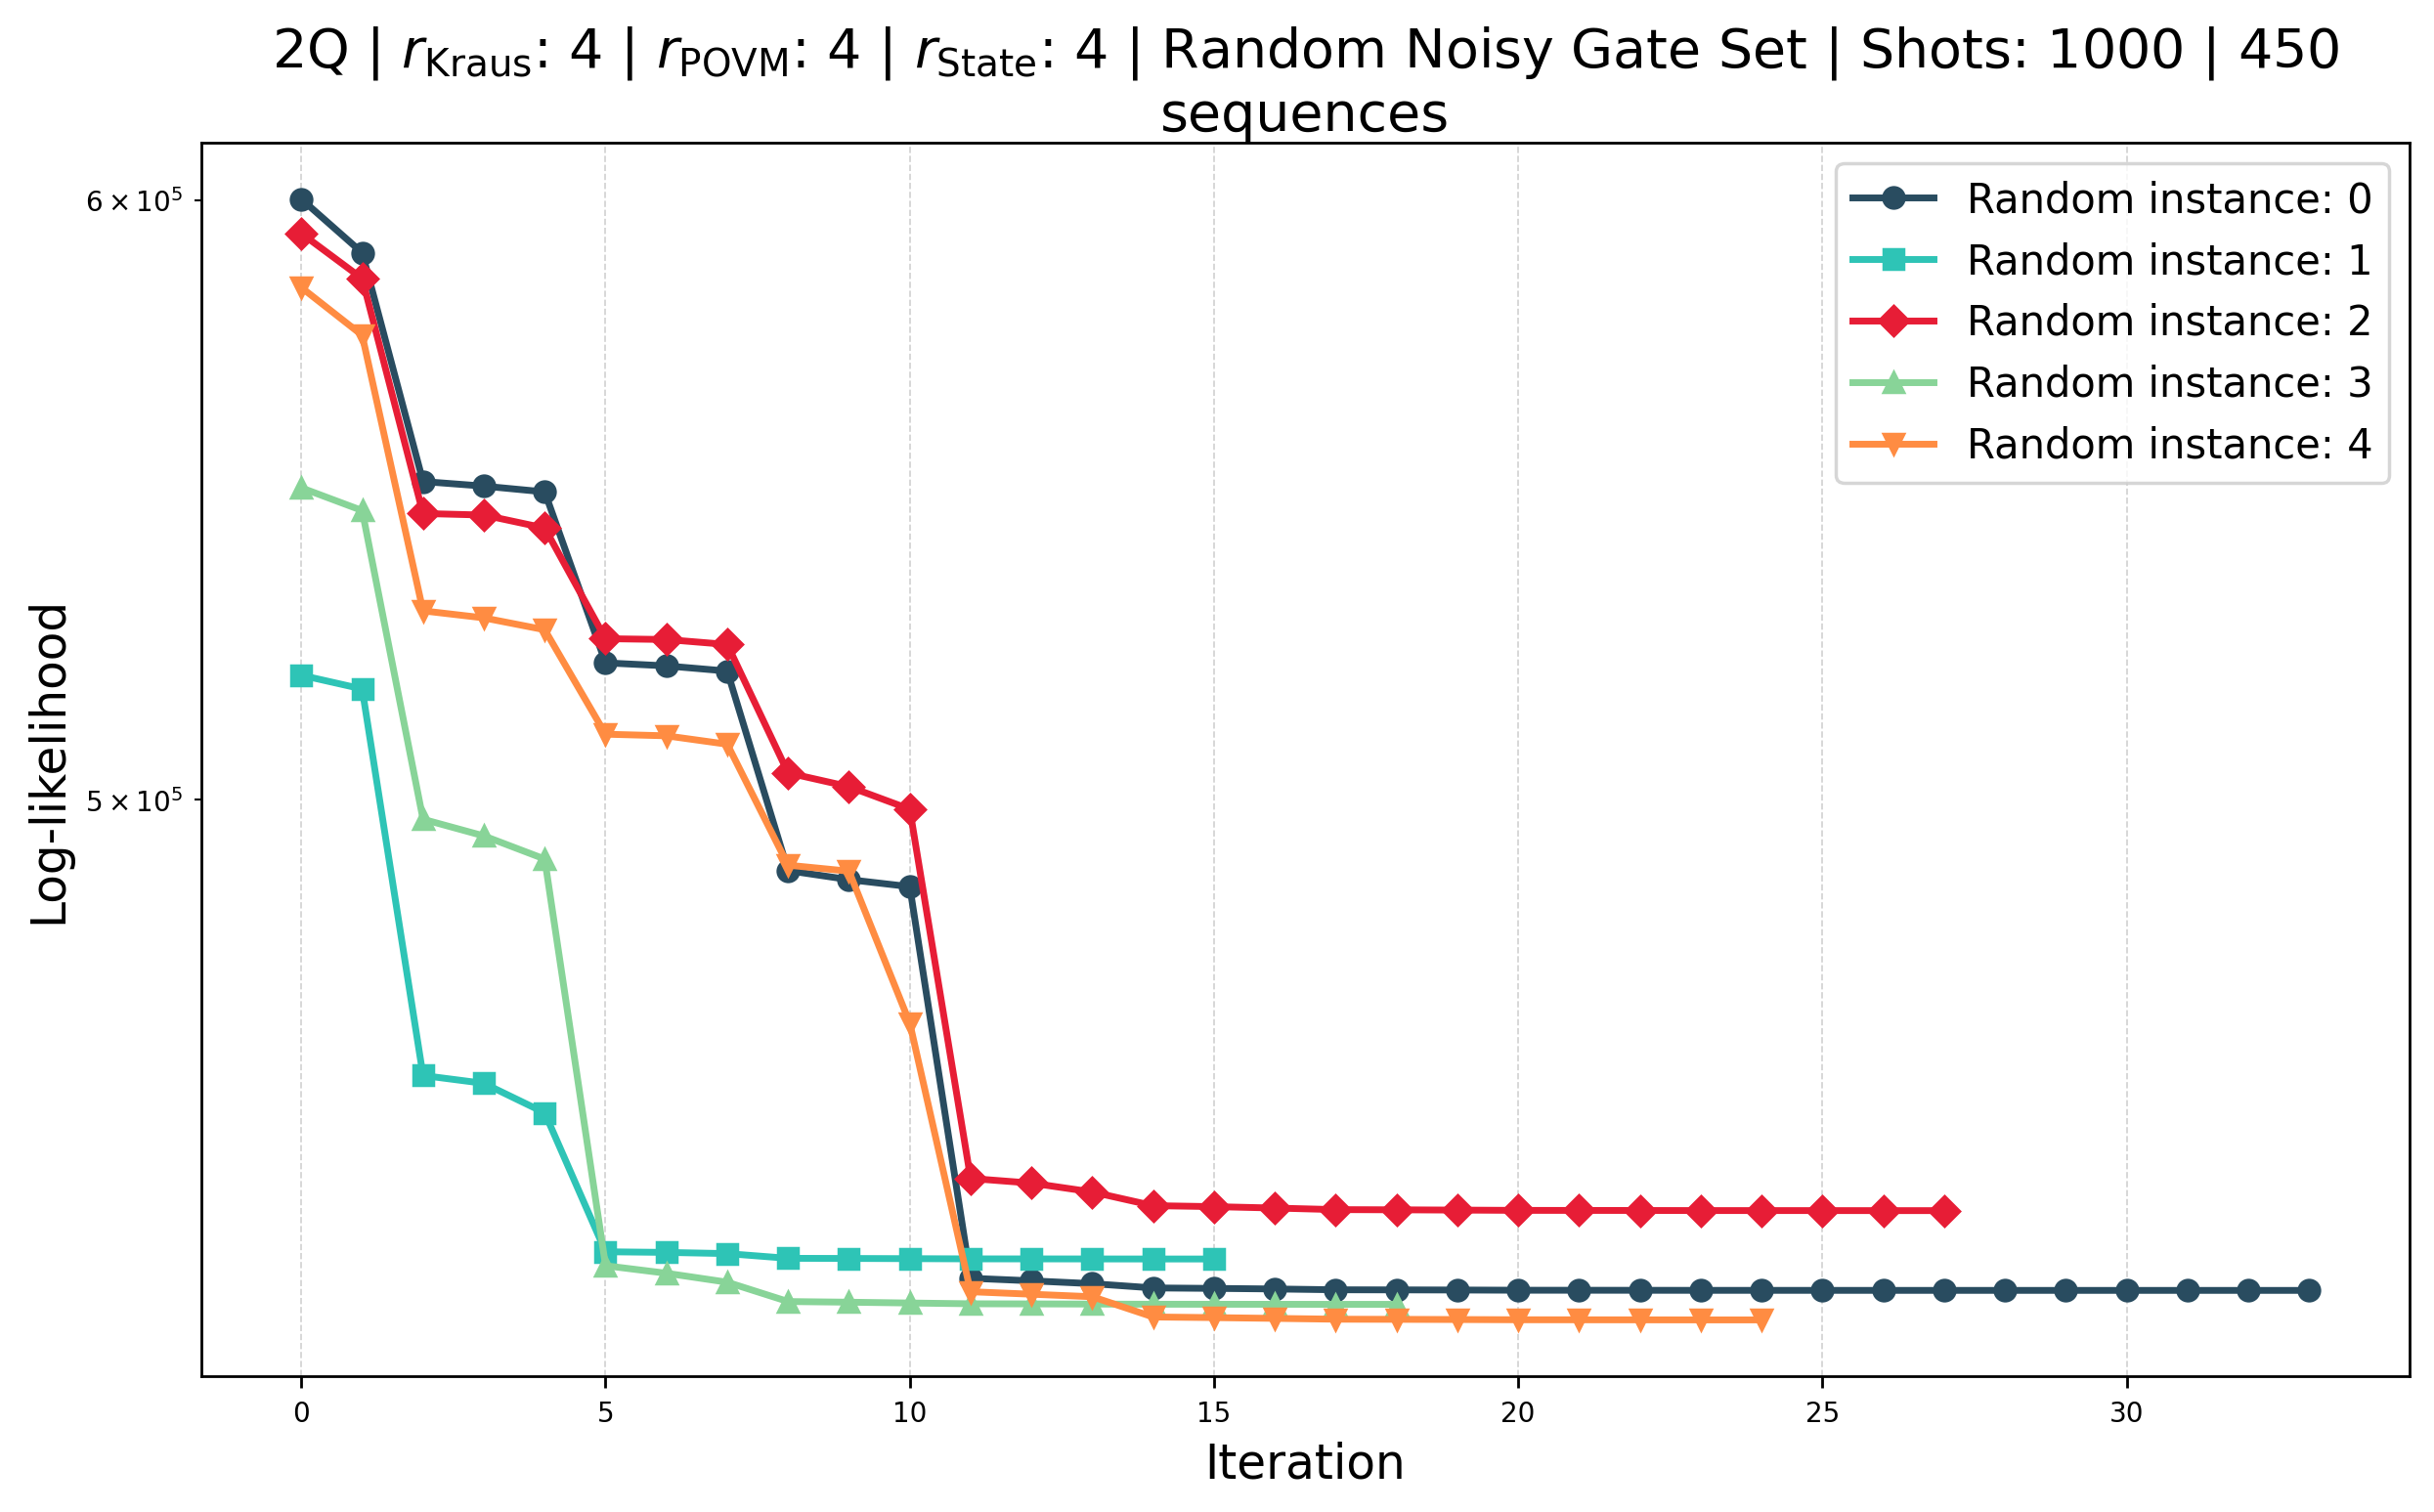

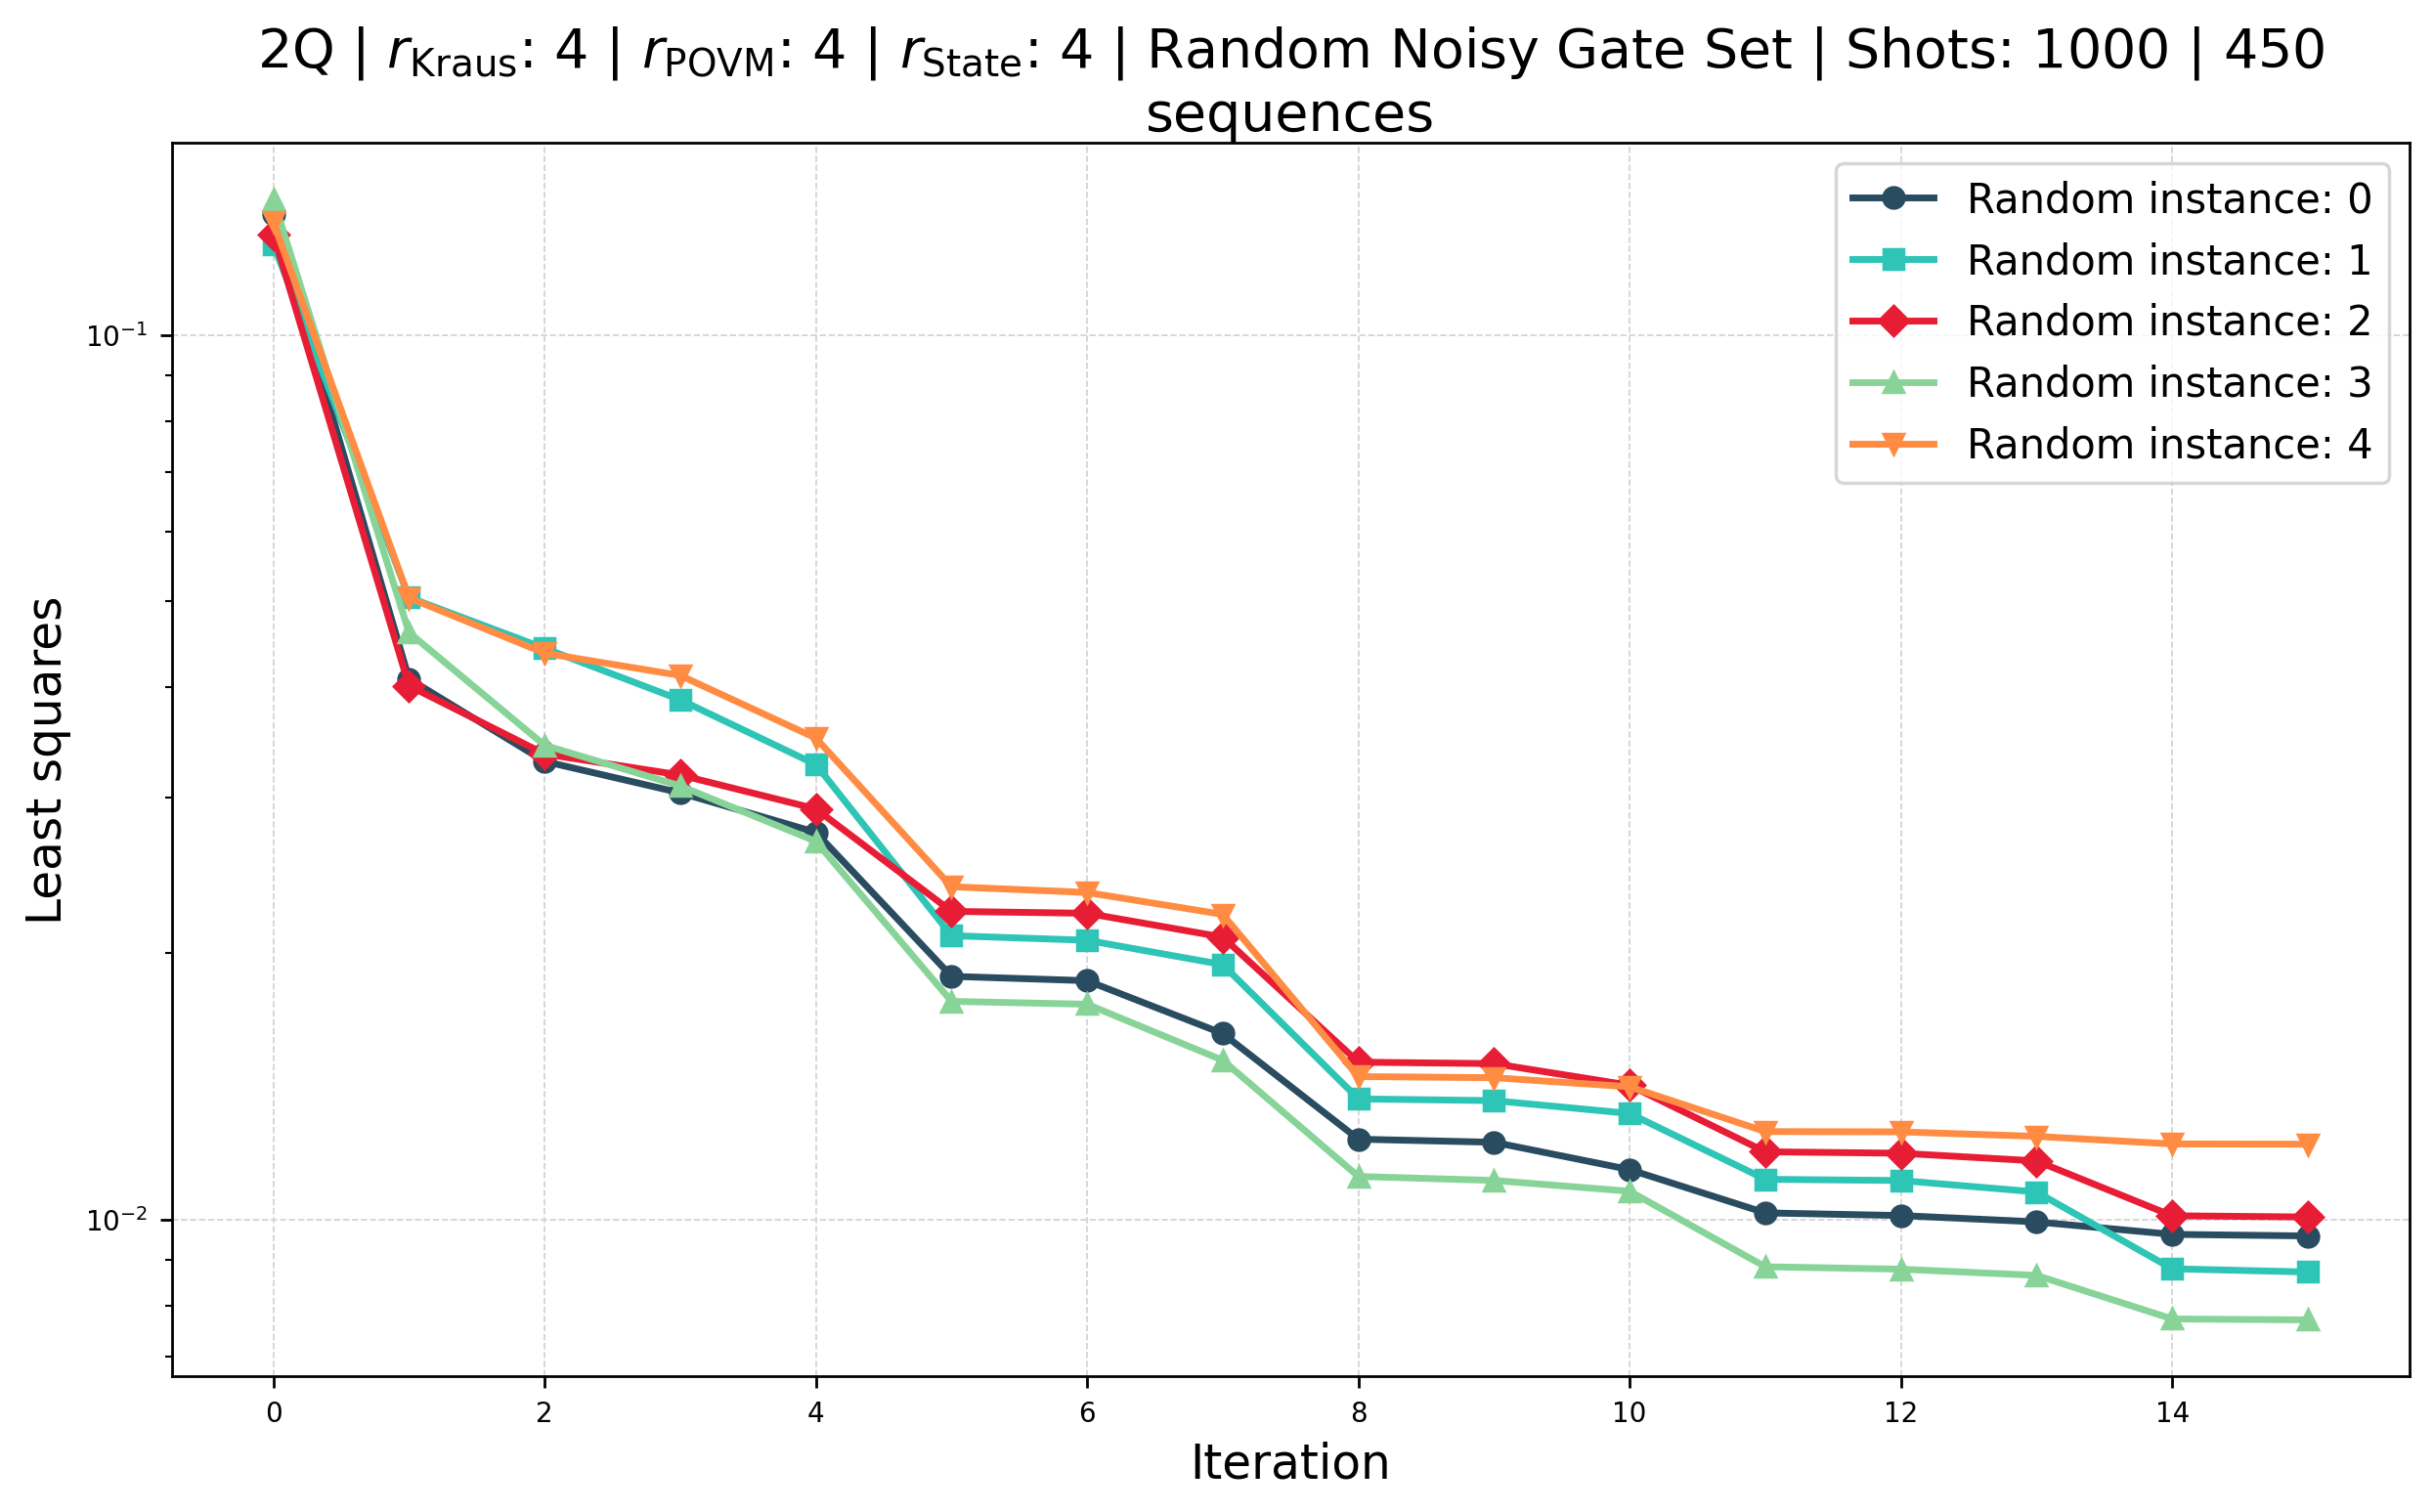

In [48]:
sequences_test = 450

final_results_test = get_all_realizations_for_key(final_results_2, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_2, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

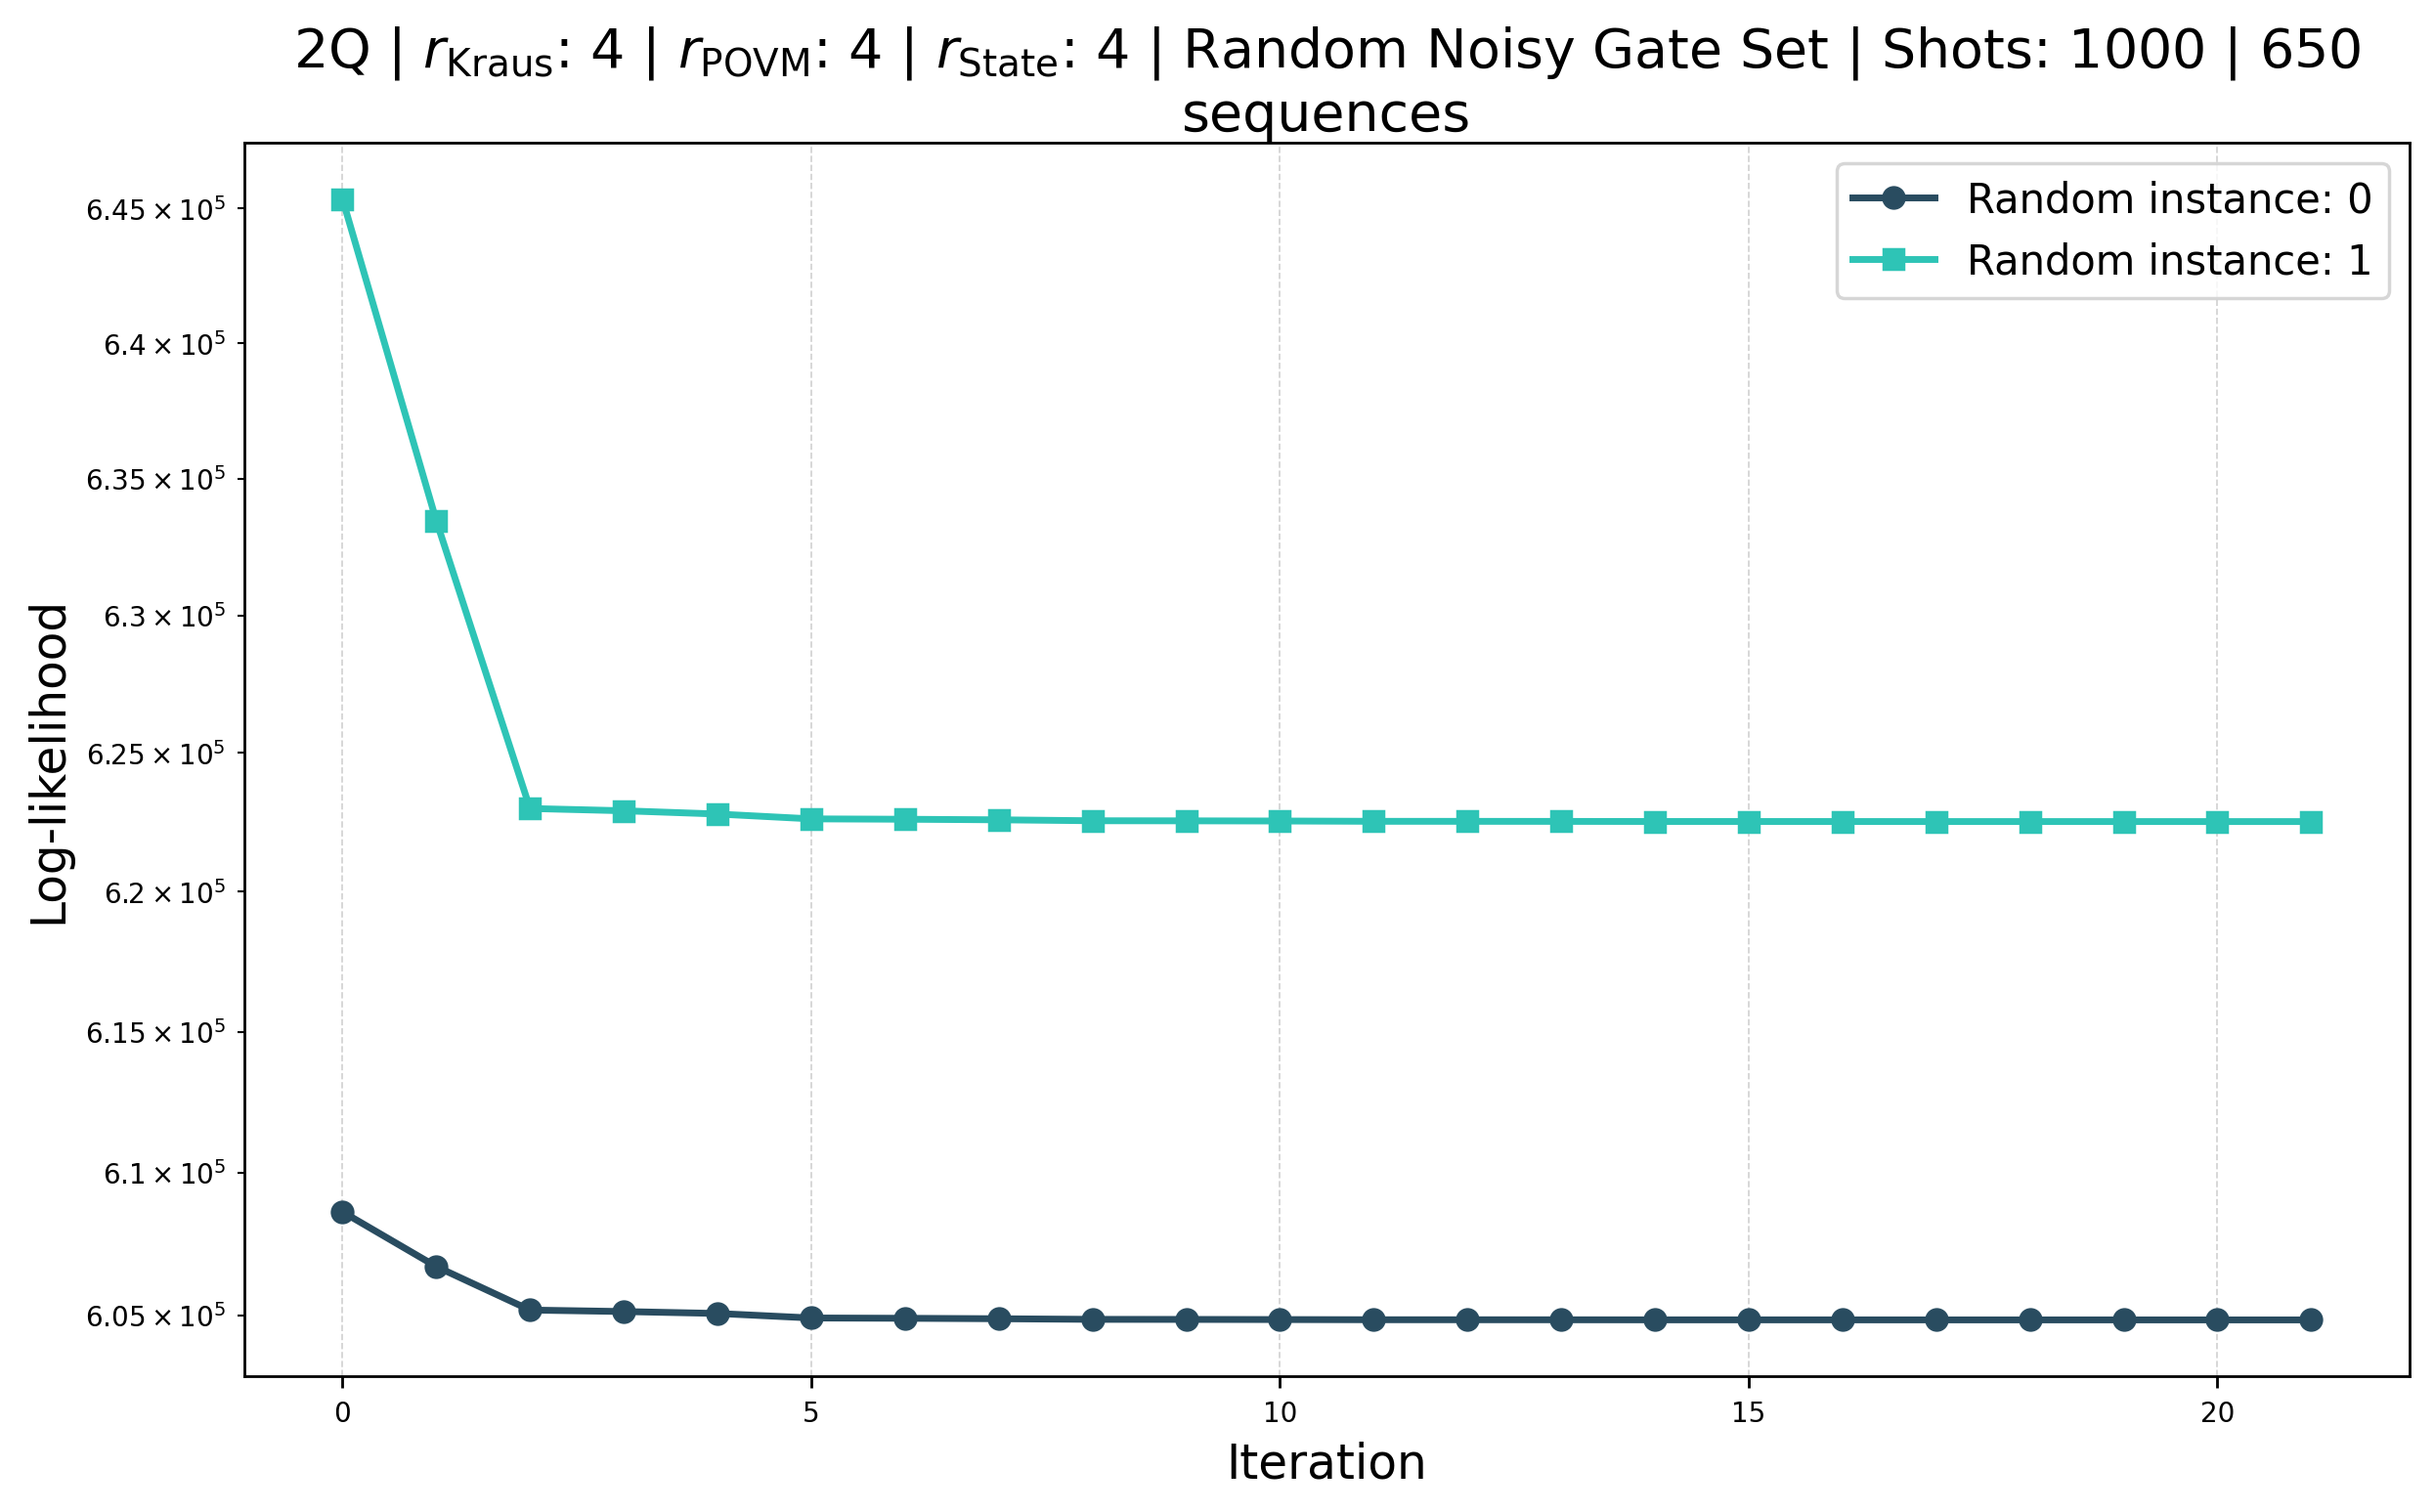

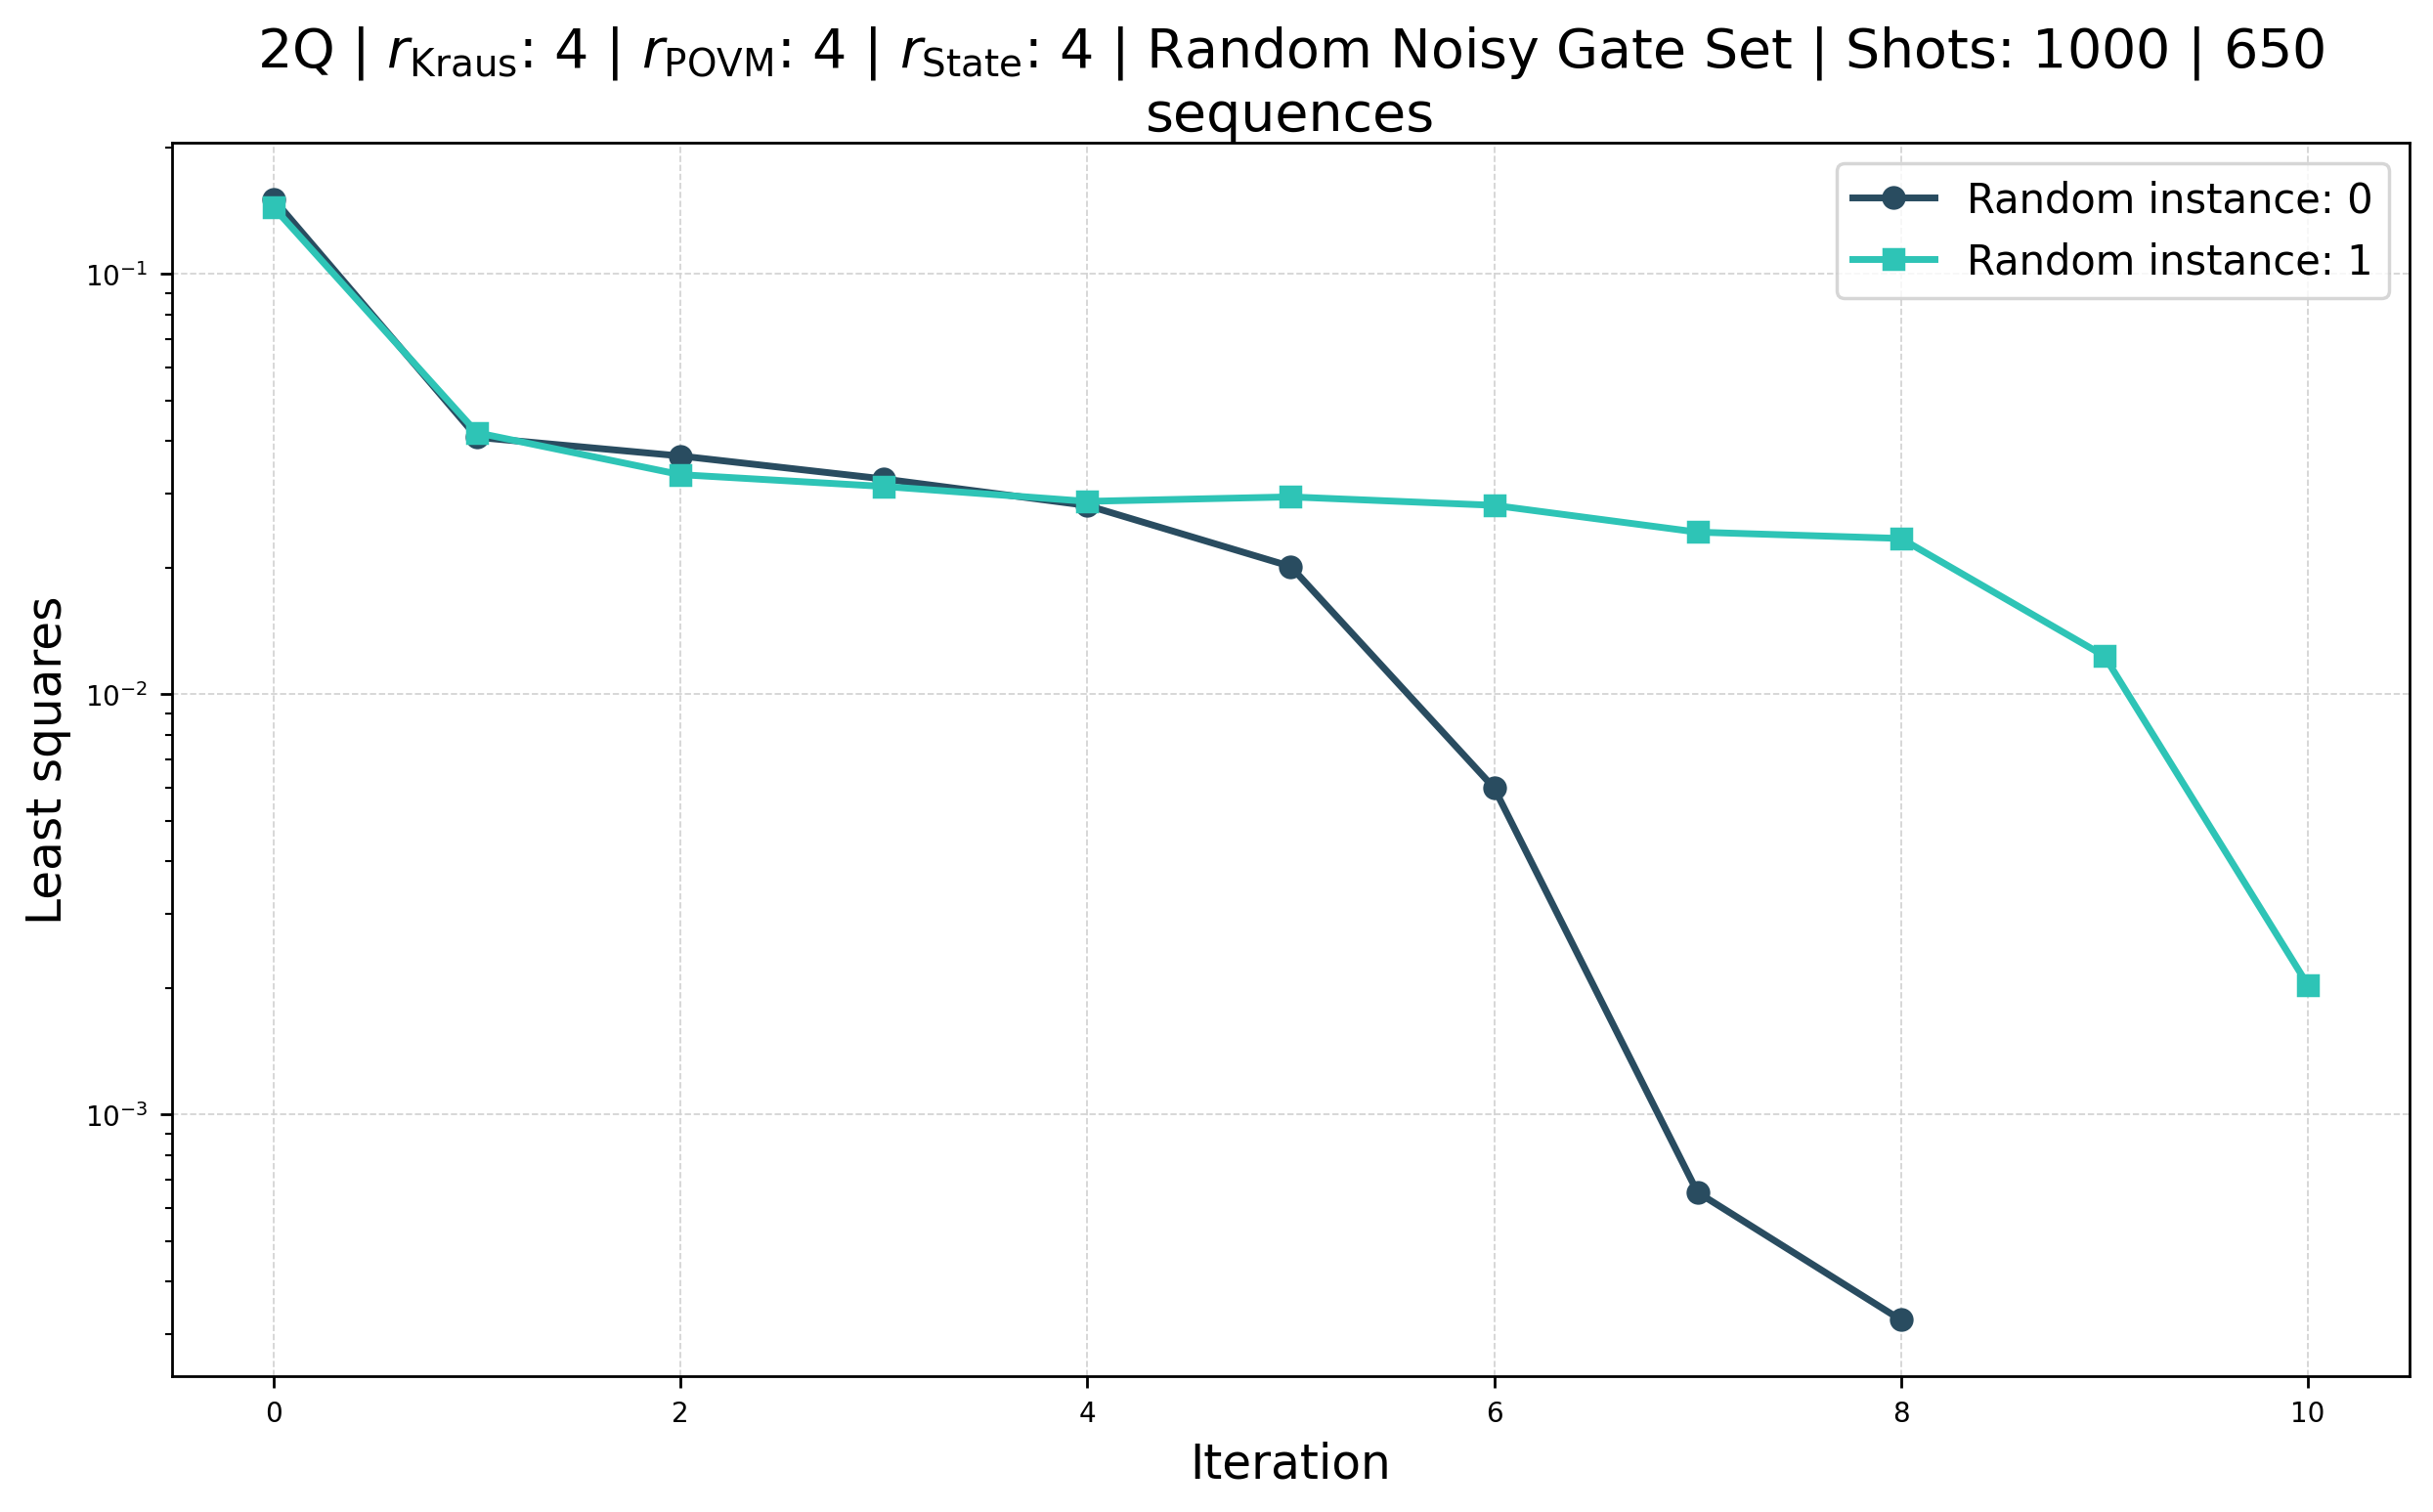

In [138]:
sequences_test = 650

final_results_test = get_all_realizations_for_key(final_results_1, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_1, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

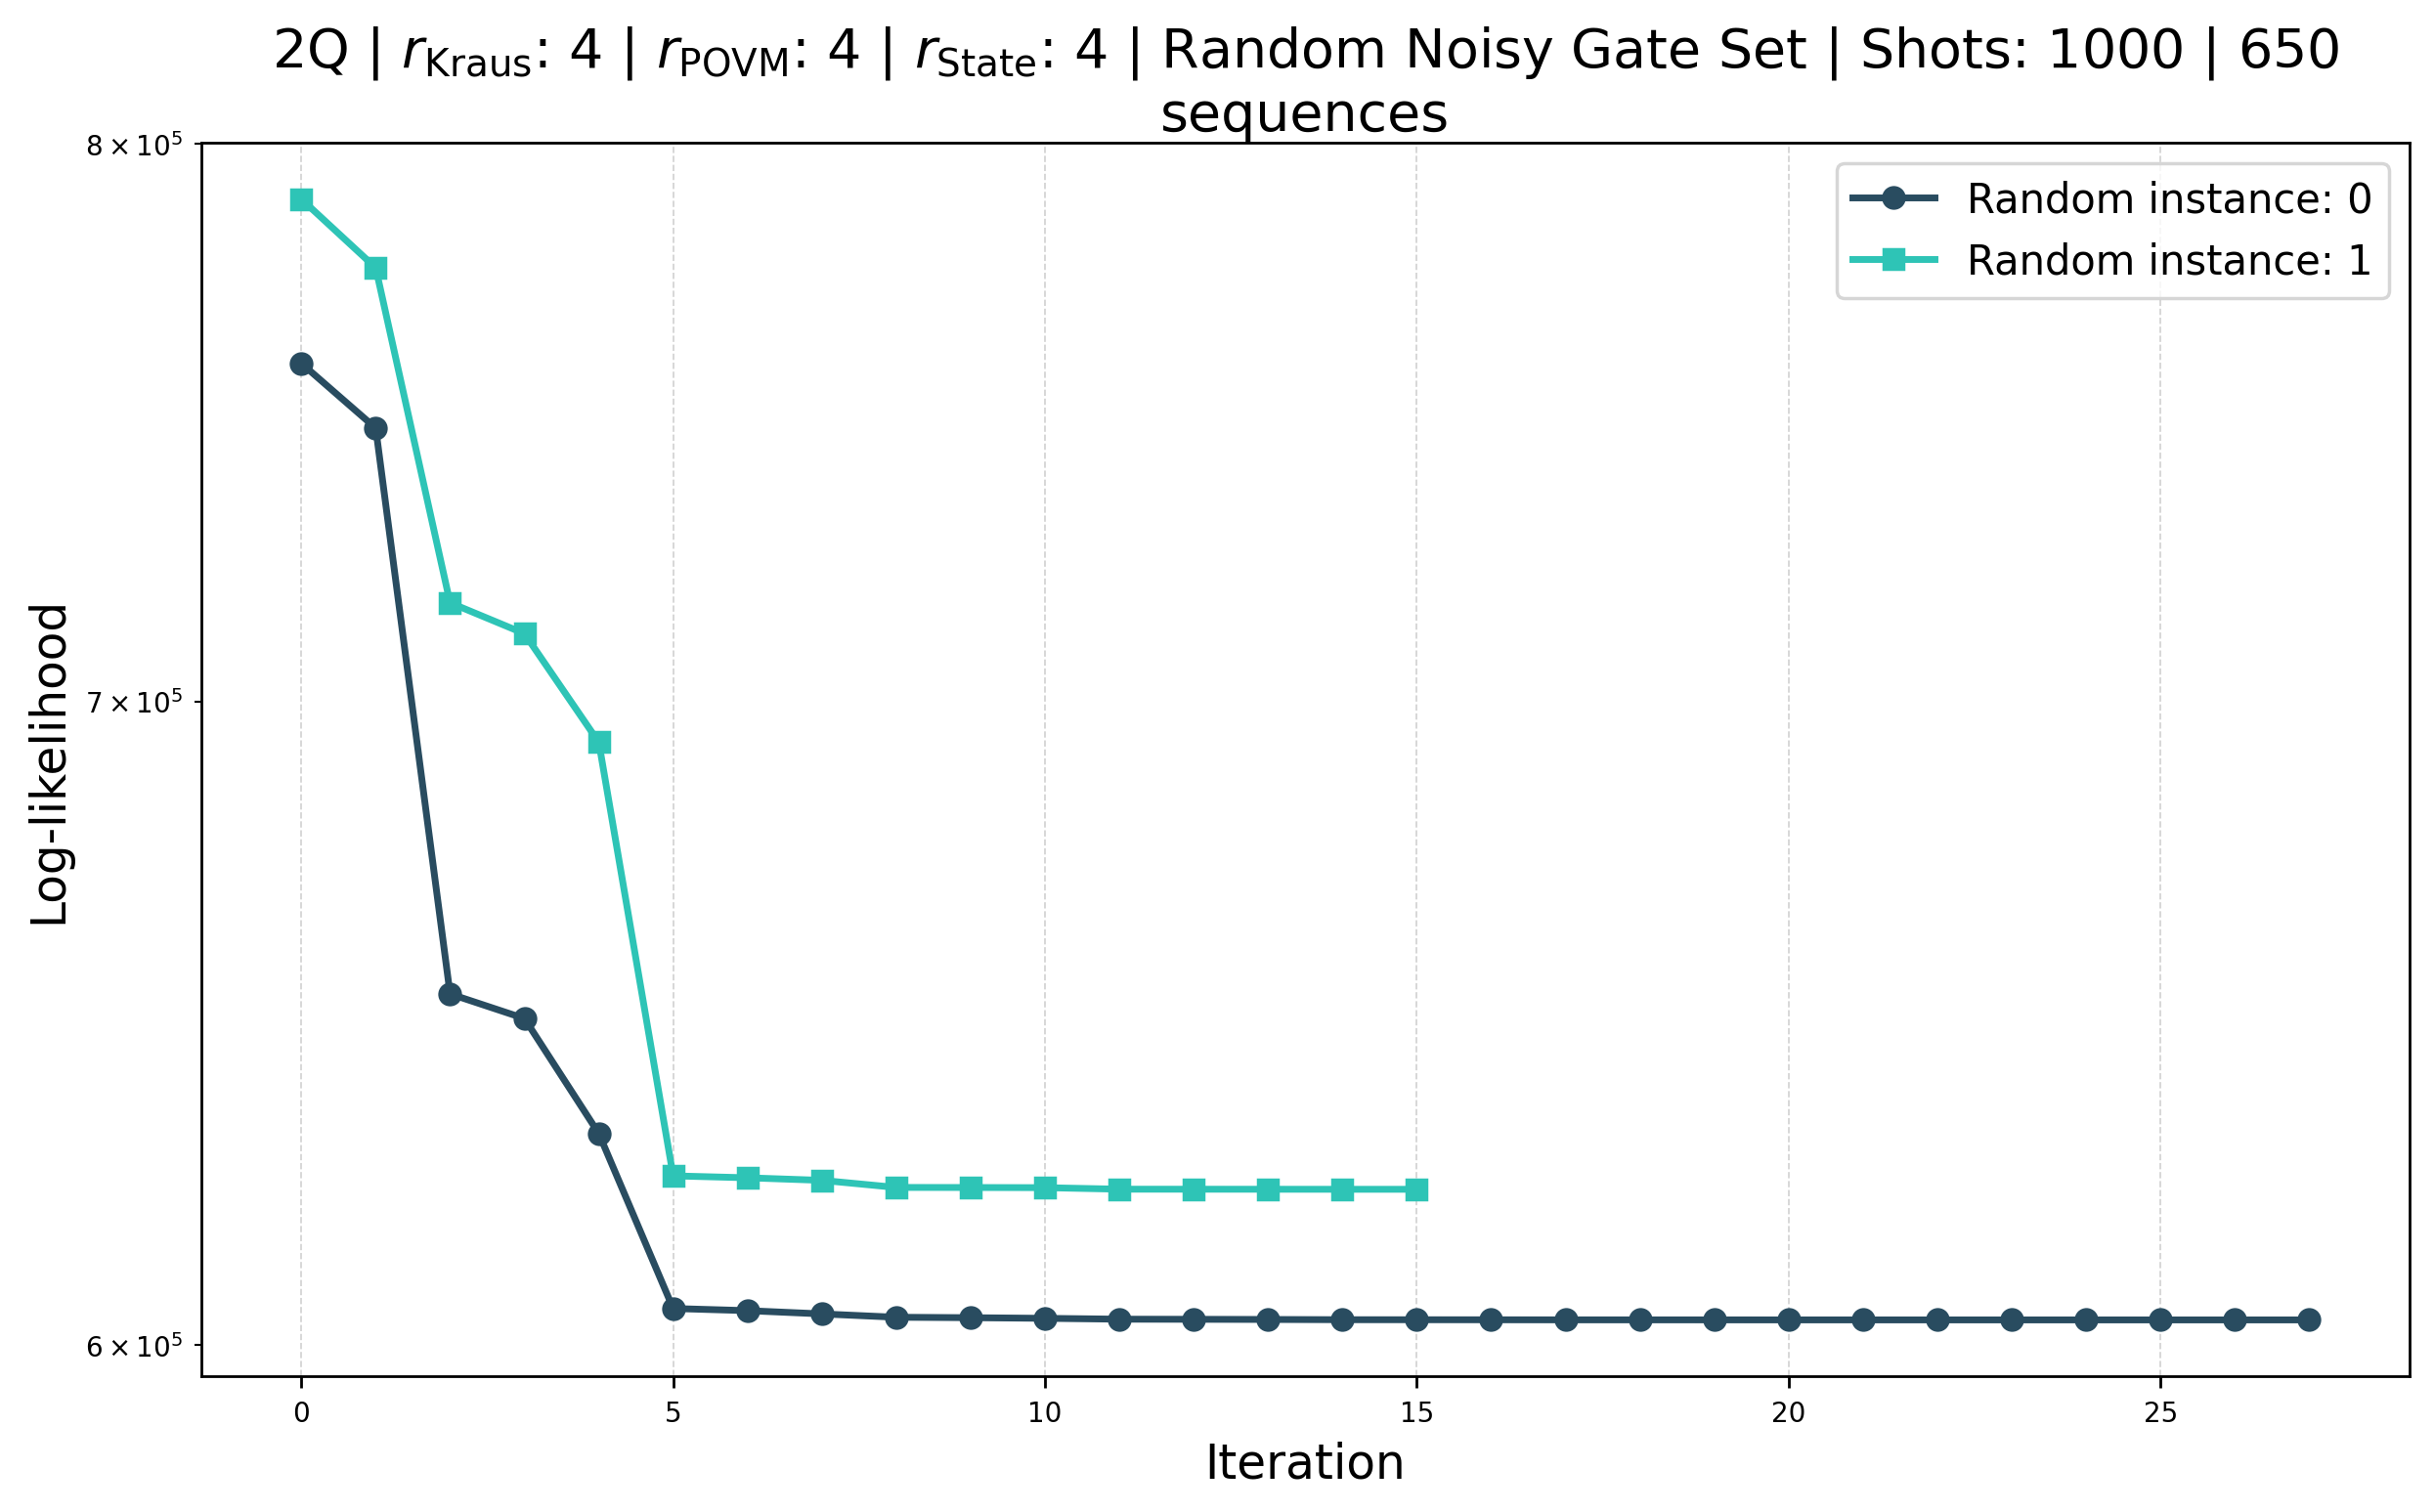

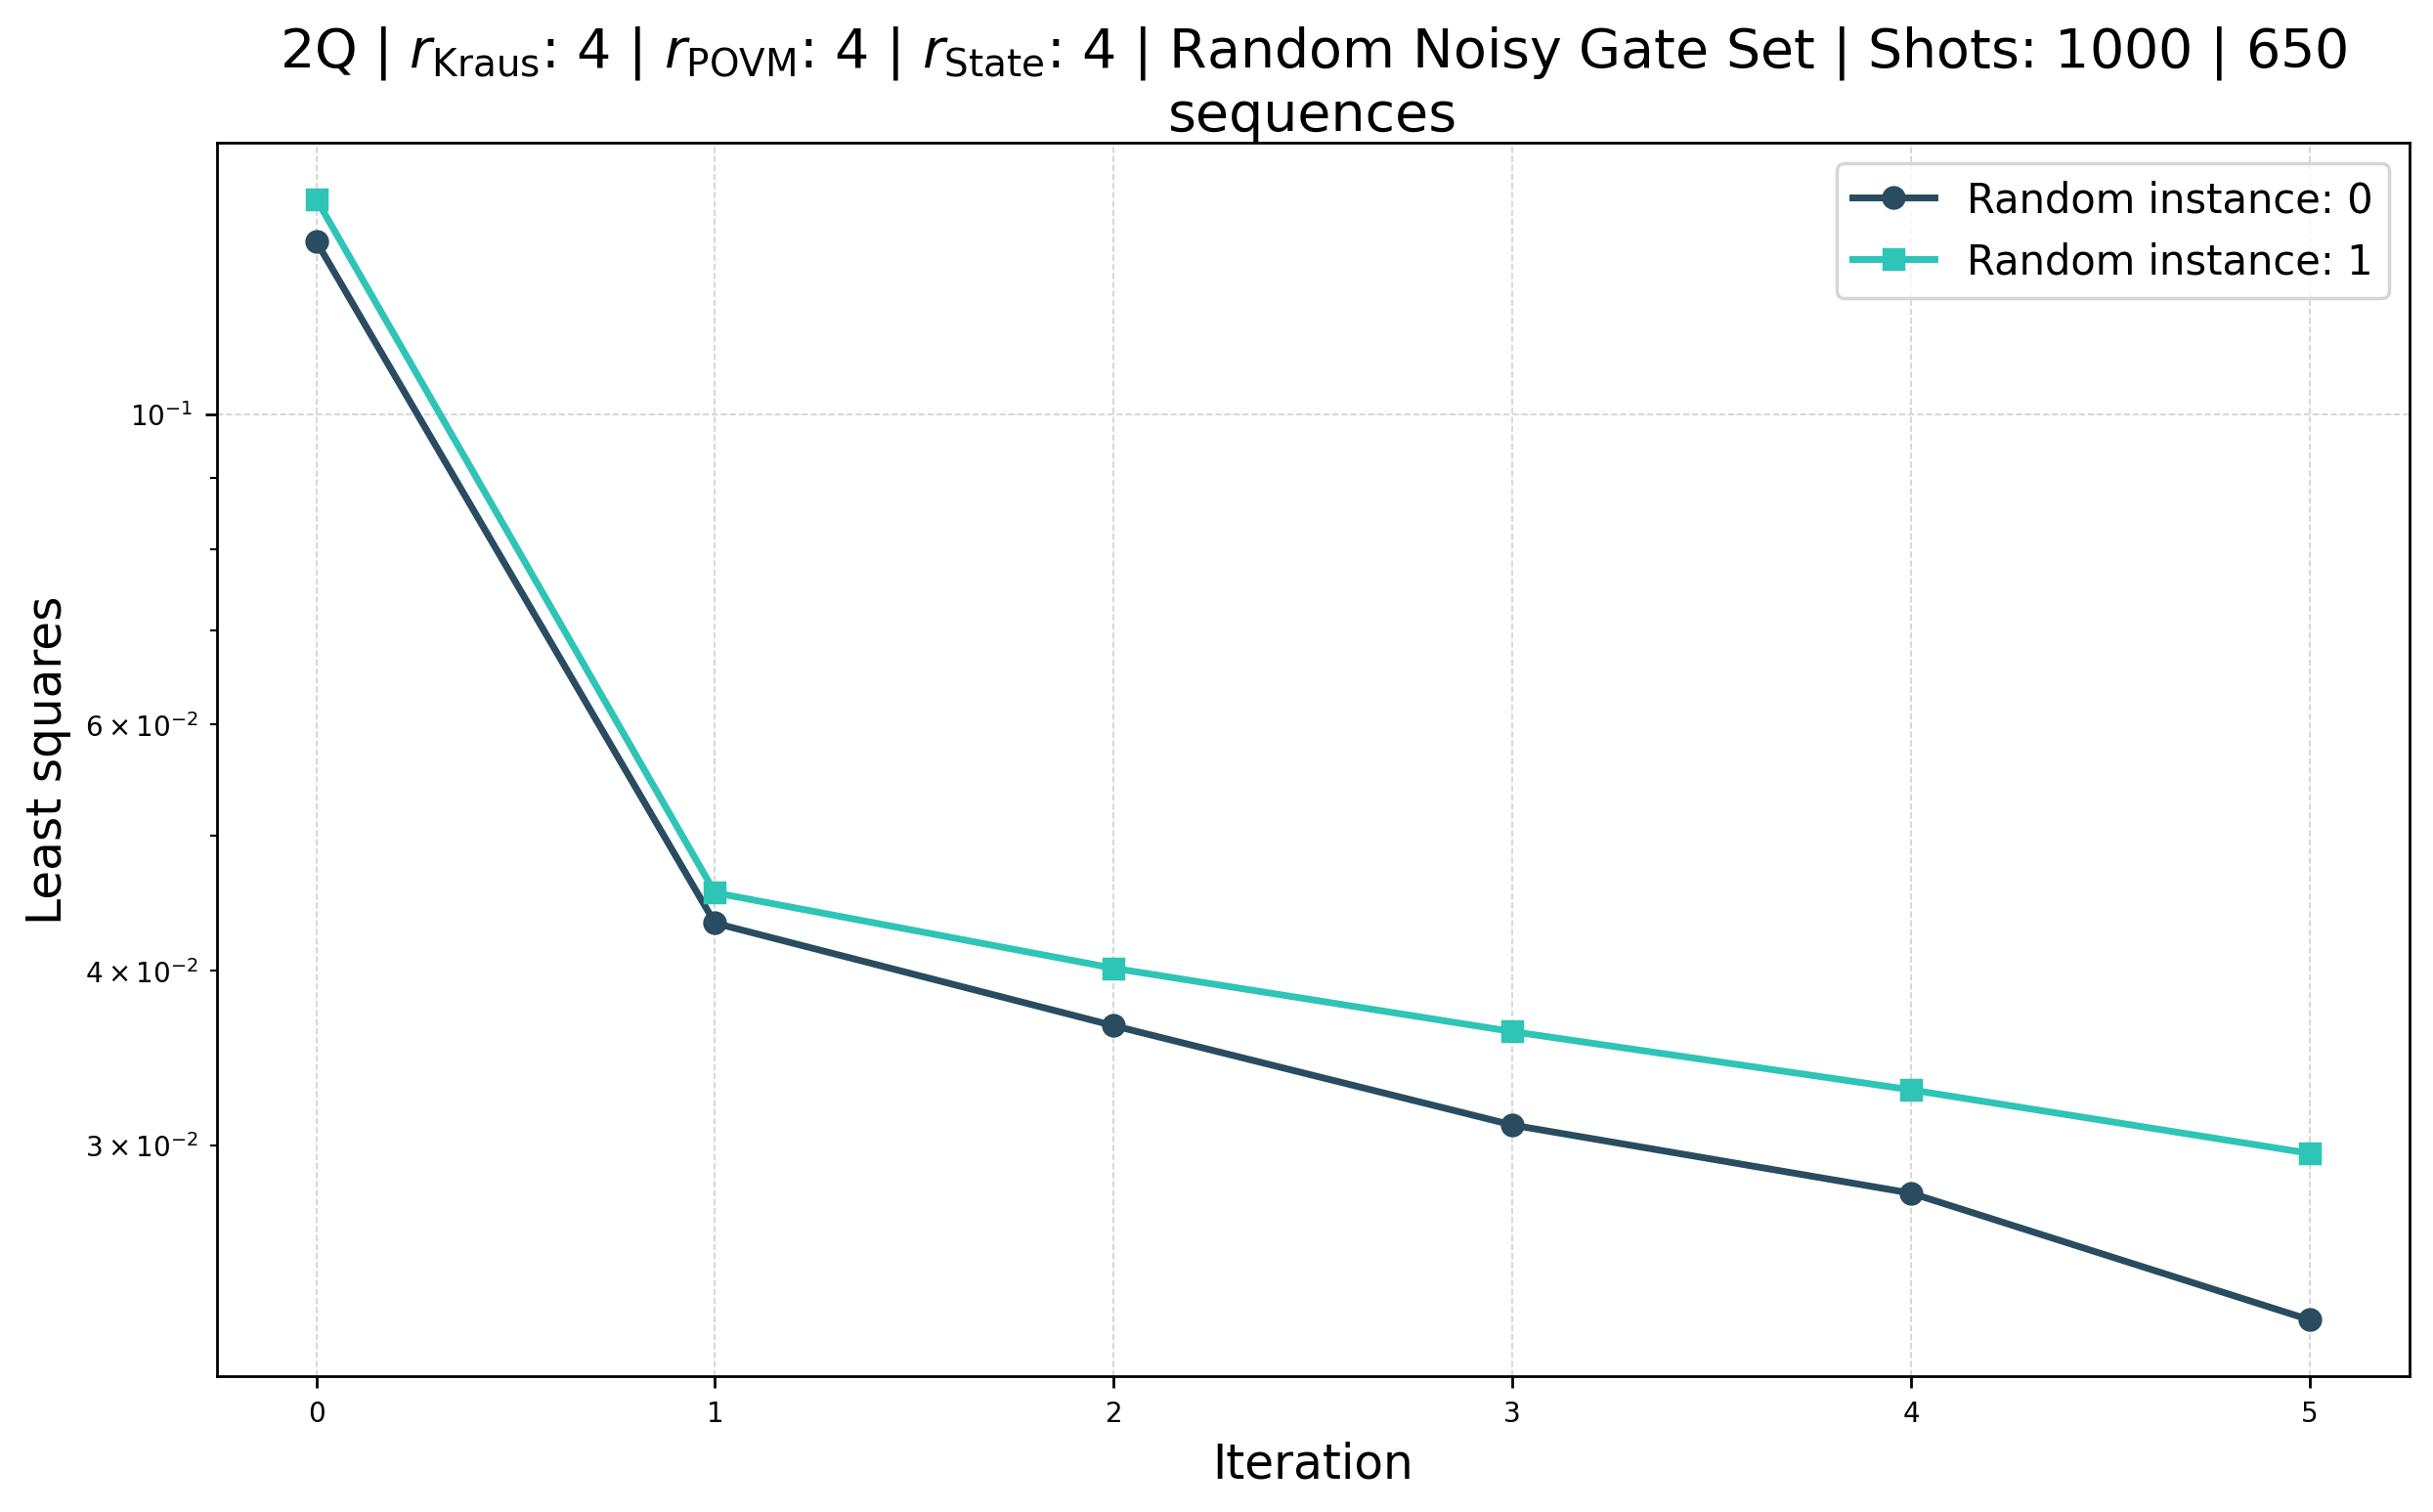

In [122]:
sequences_test = 650

final_results_test = get_all_realizations_for_key(final_results_1, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_1, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

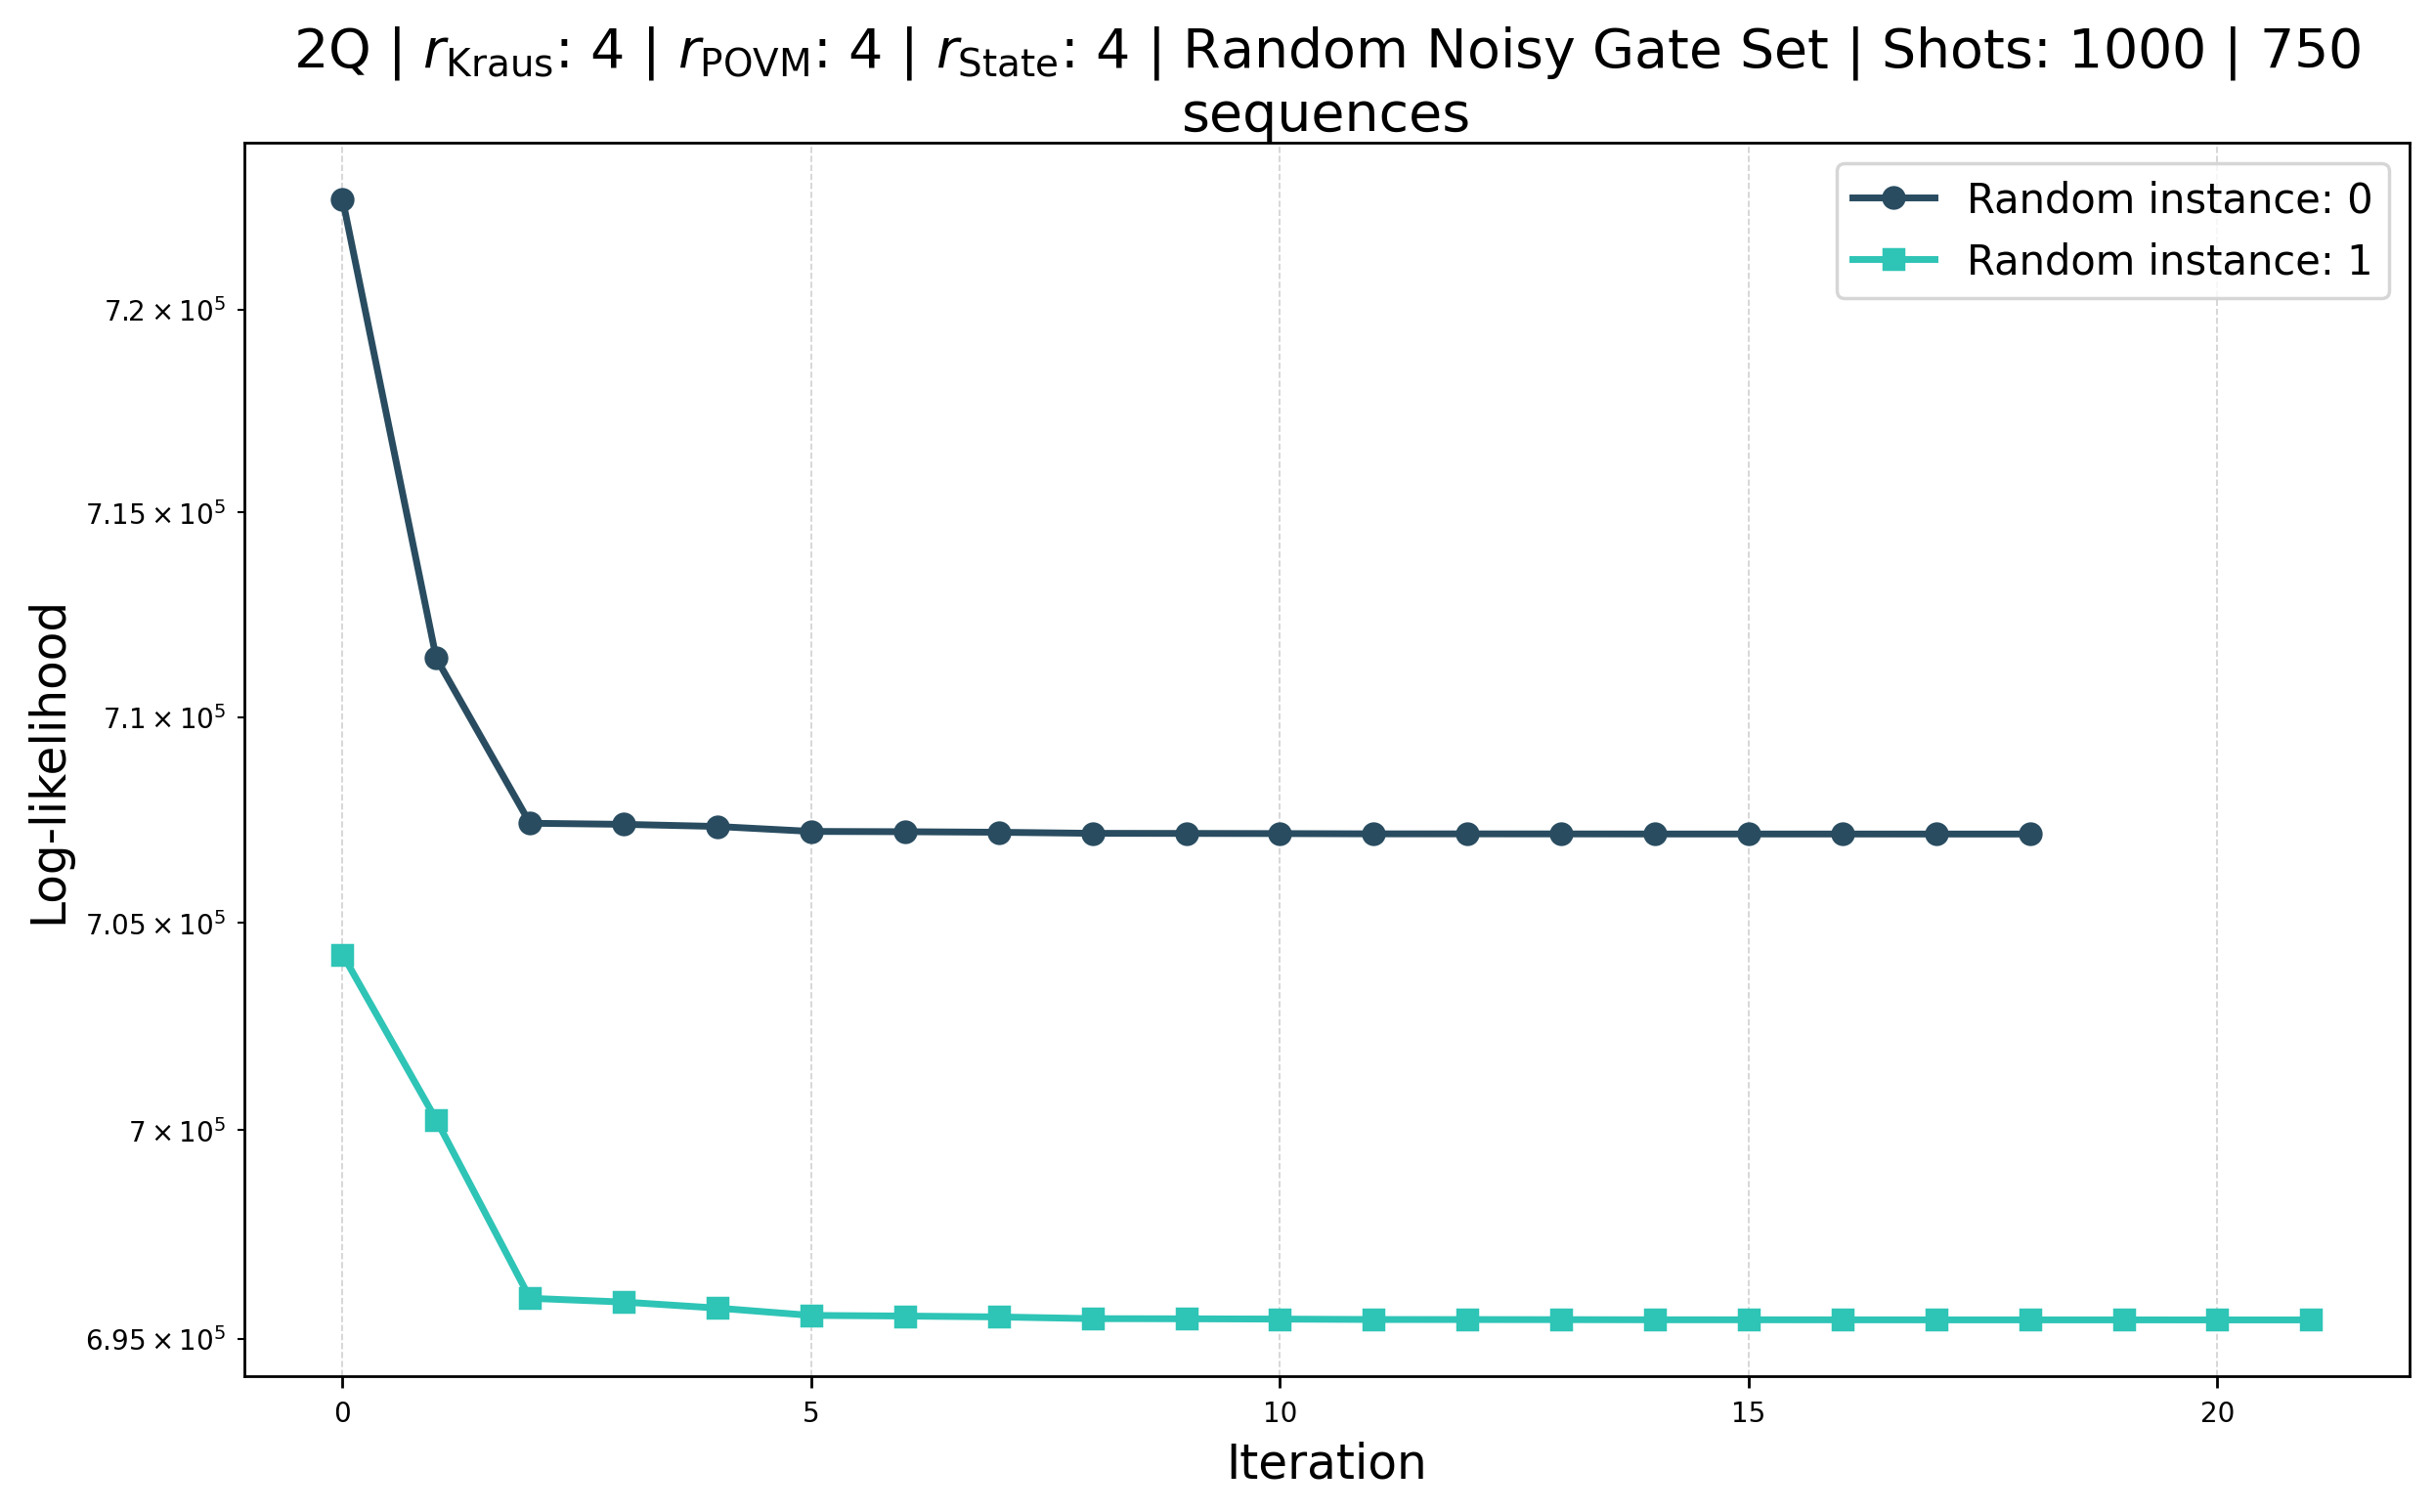

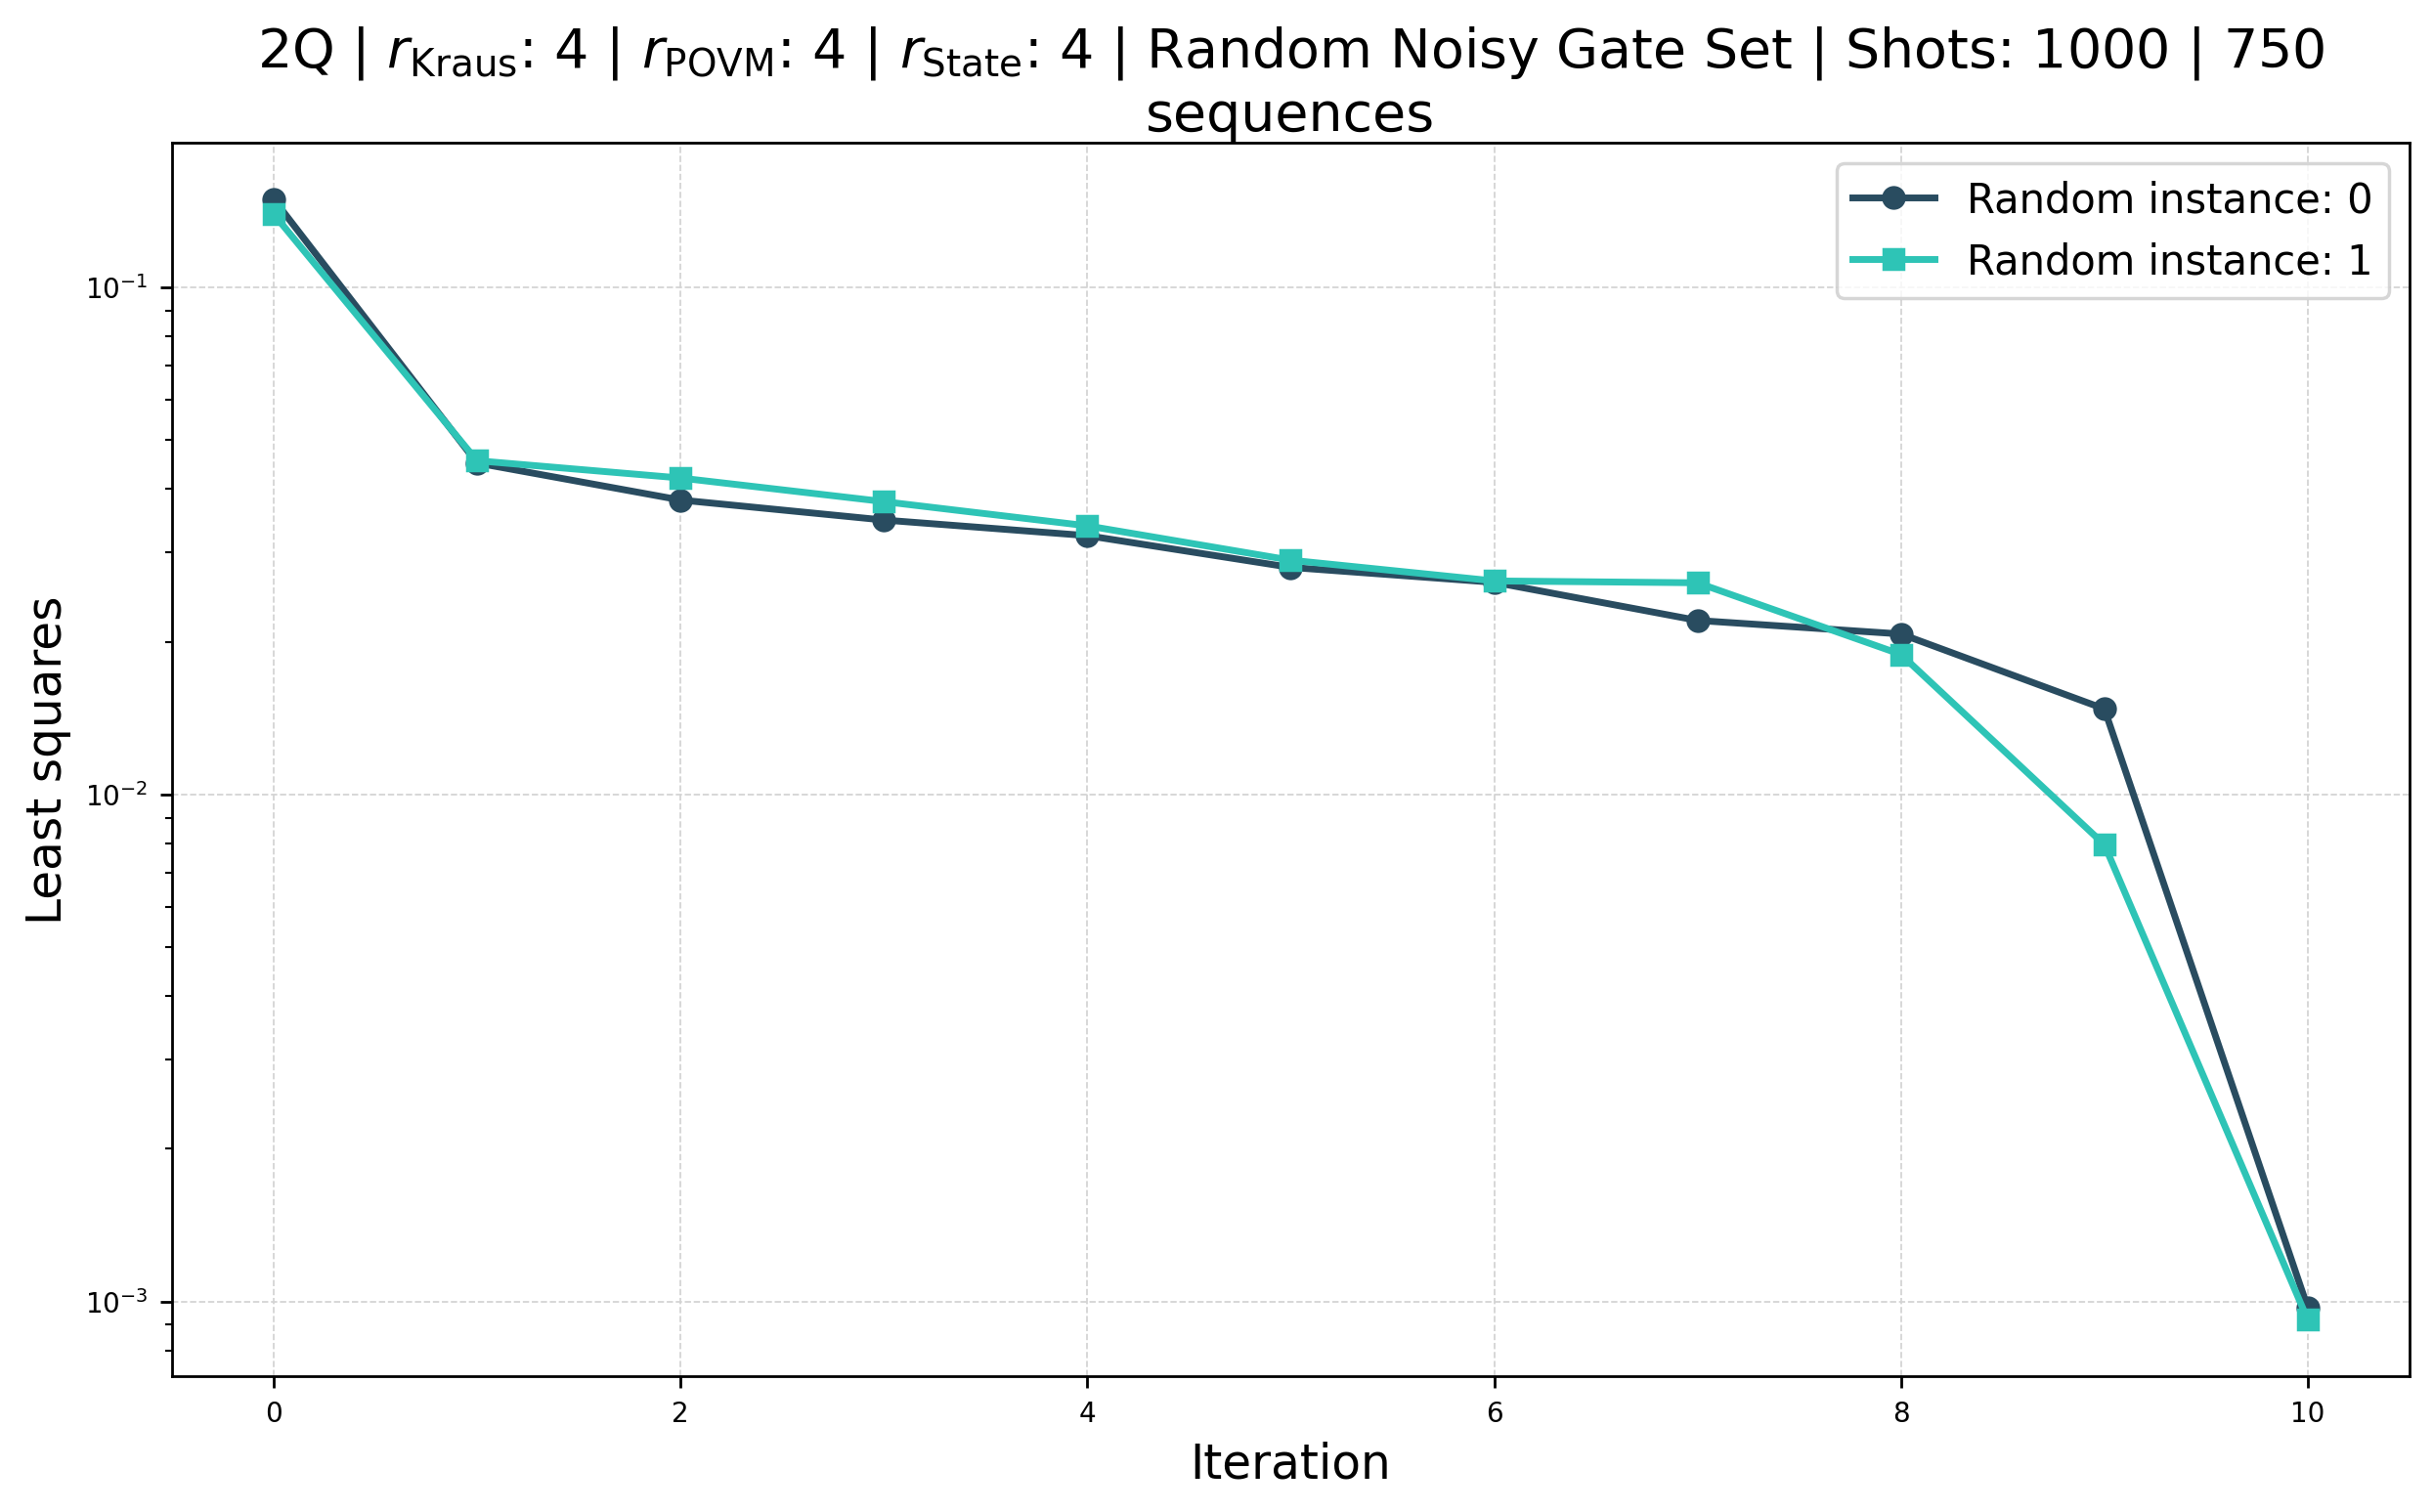

In [131]:
sequences_test = 750

final_results_test = get_all_realizations_for_key(final_results_3, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_3, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

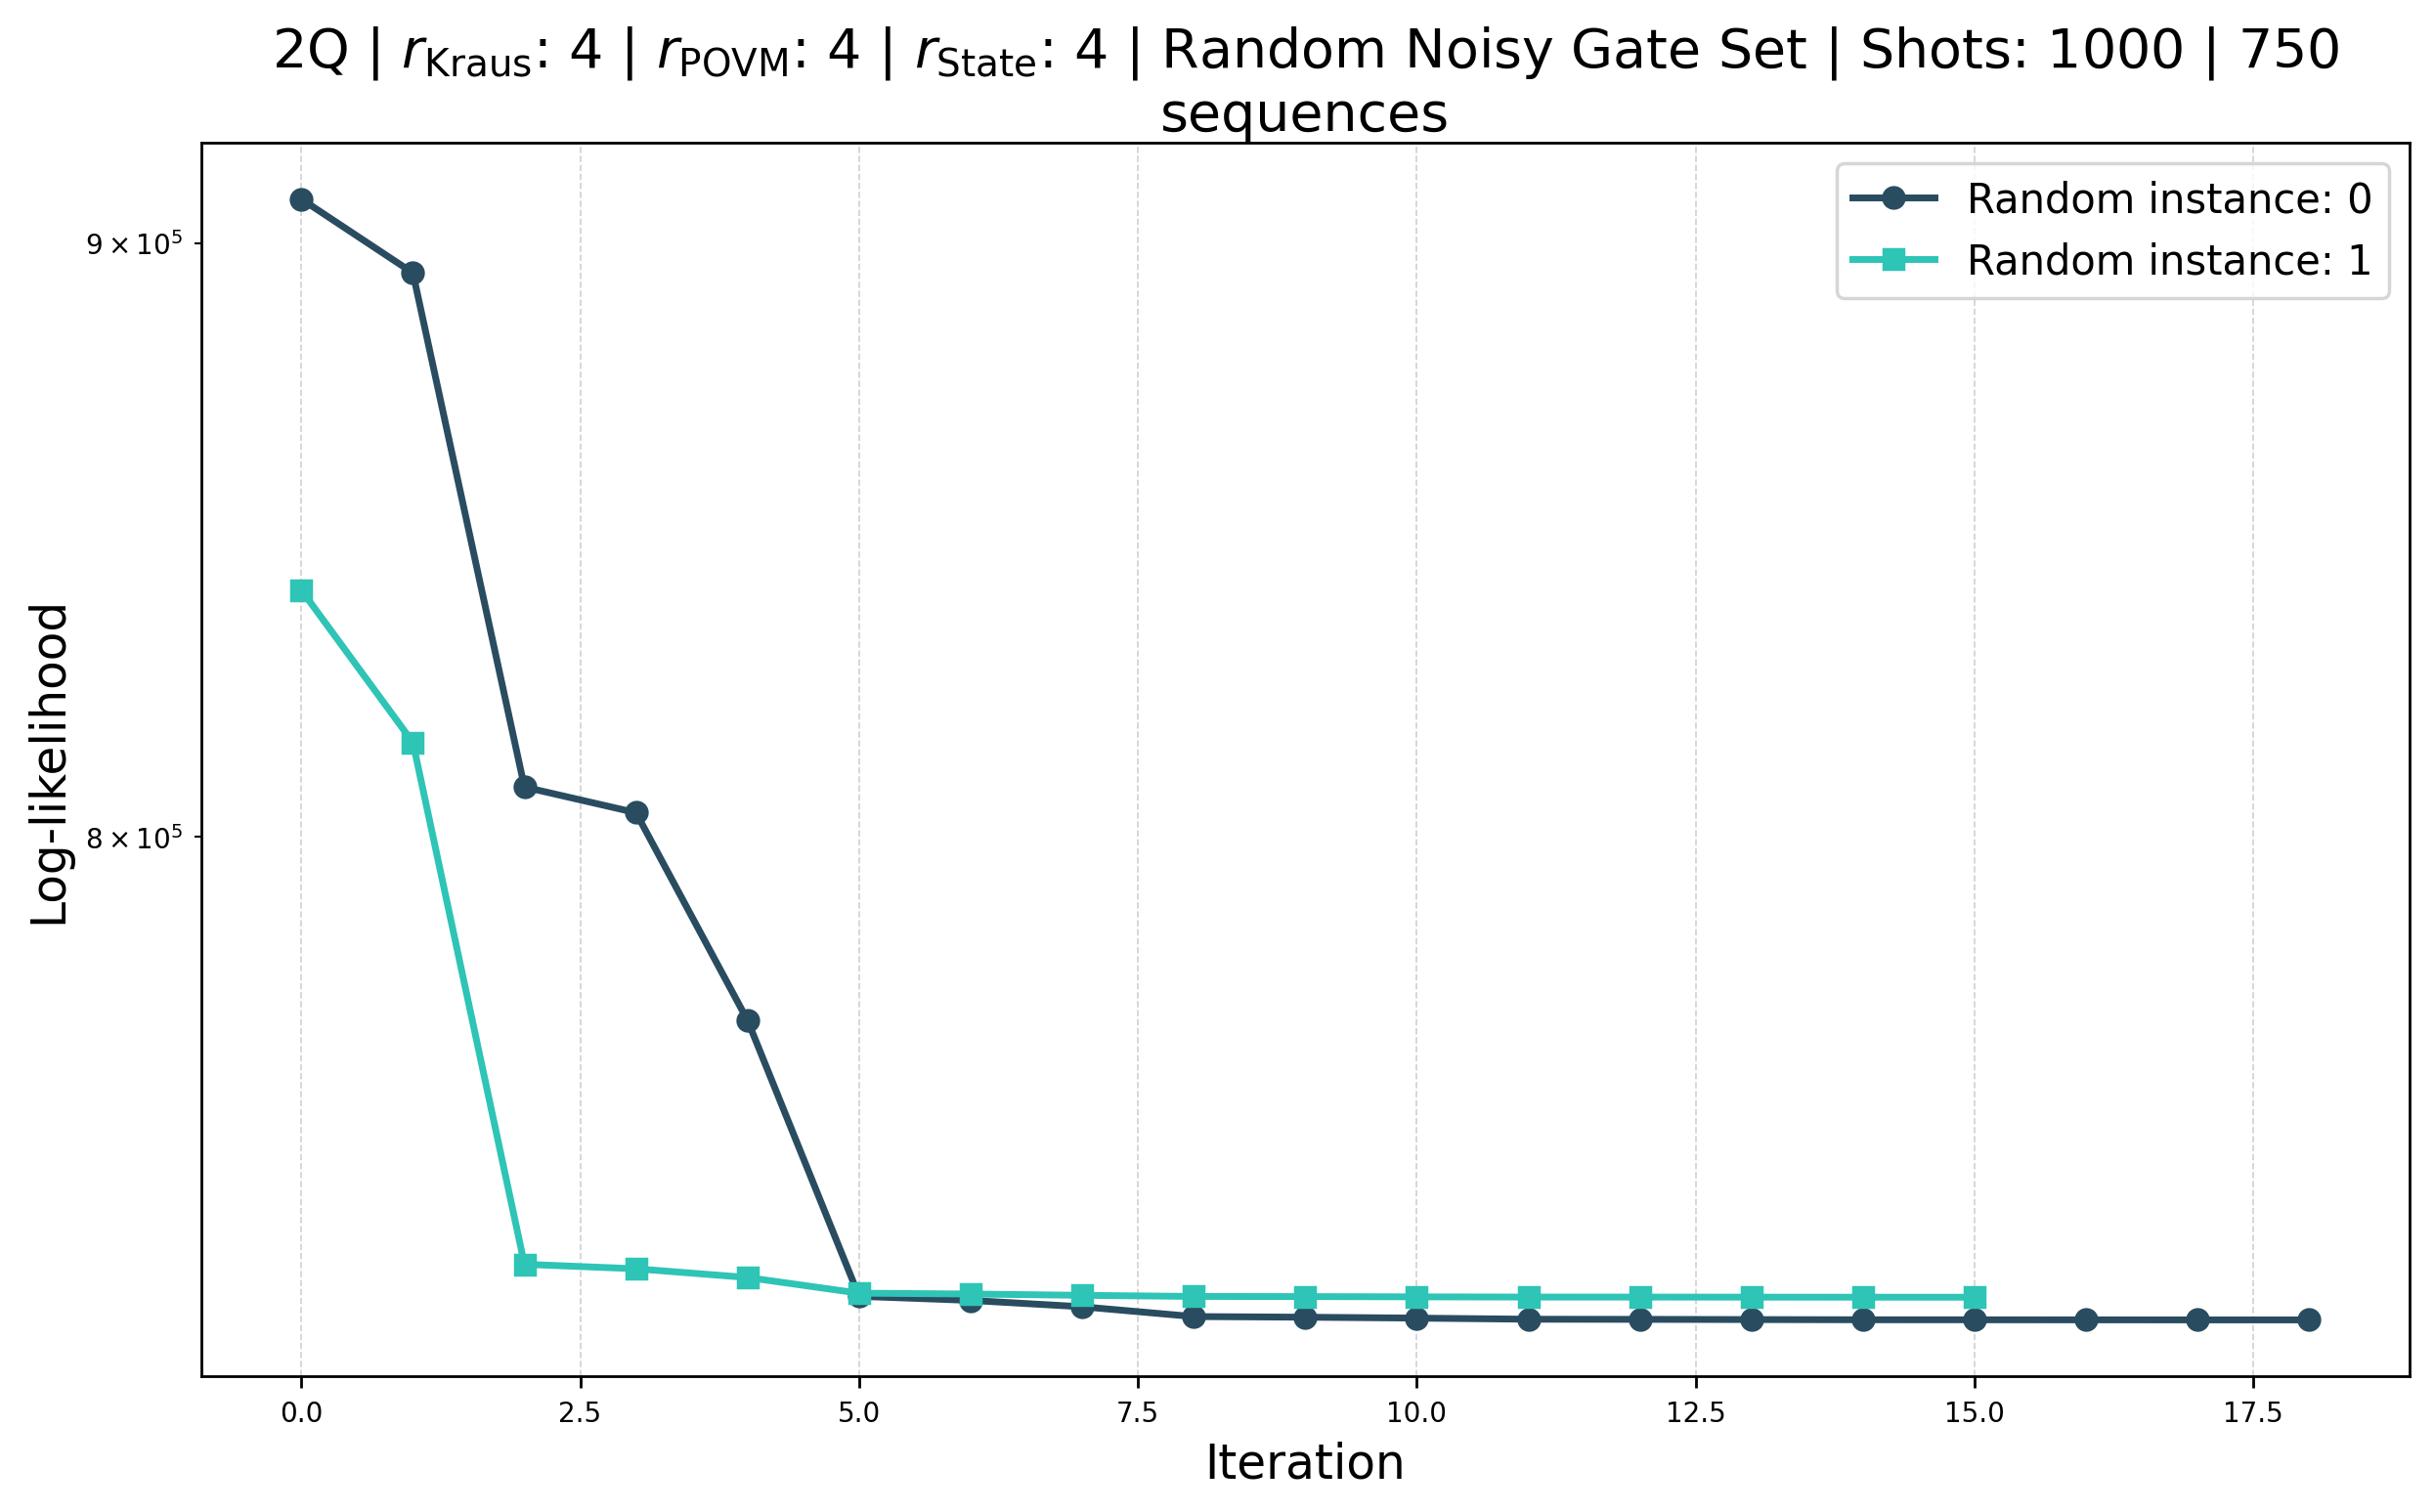

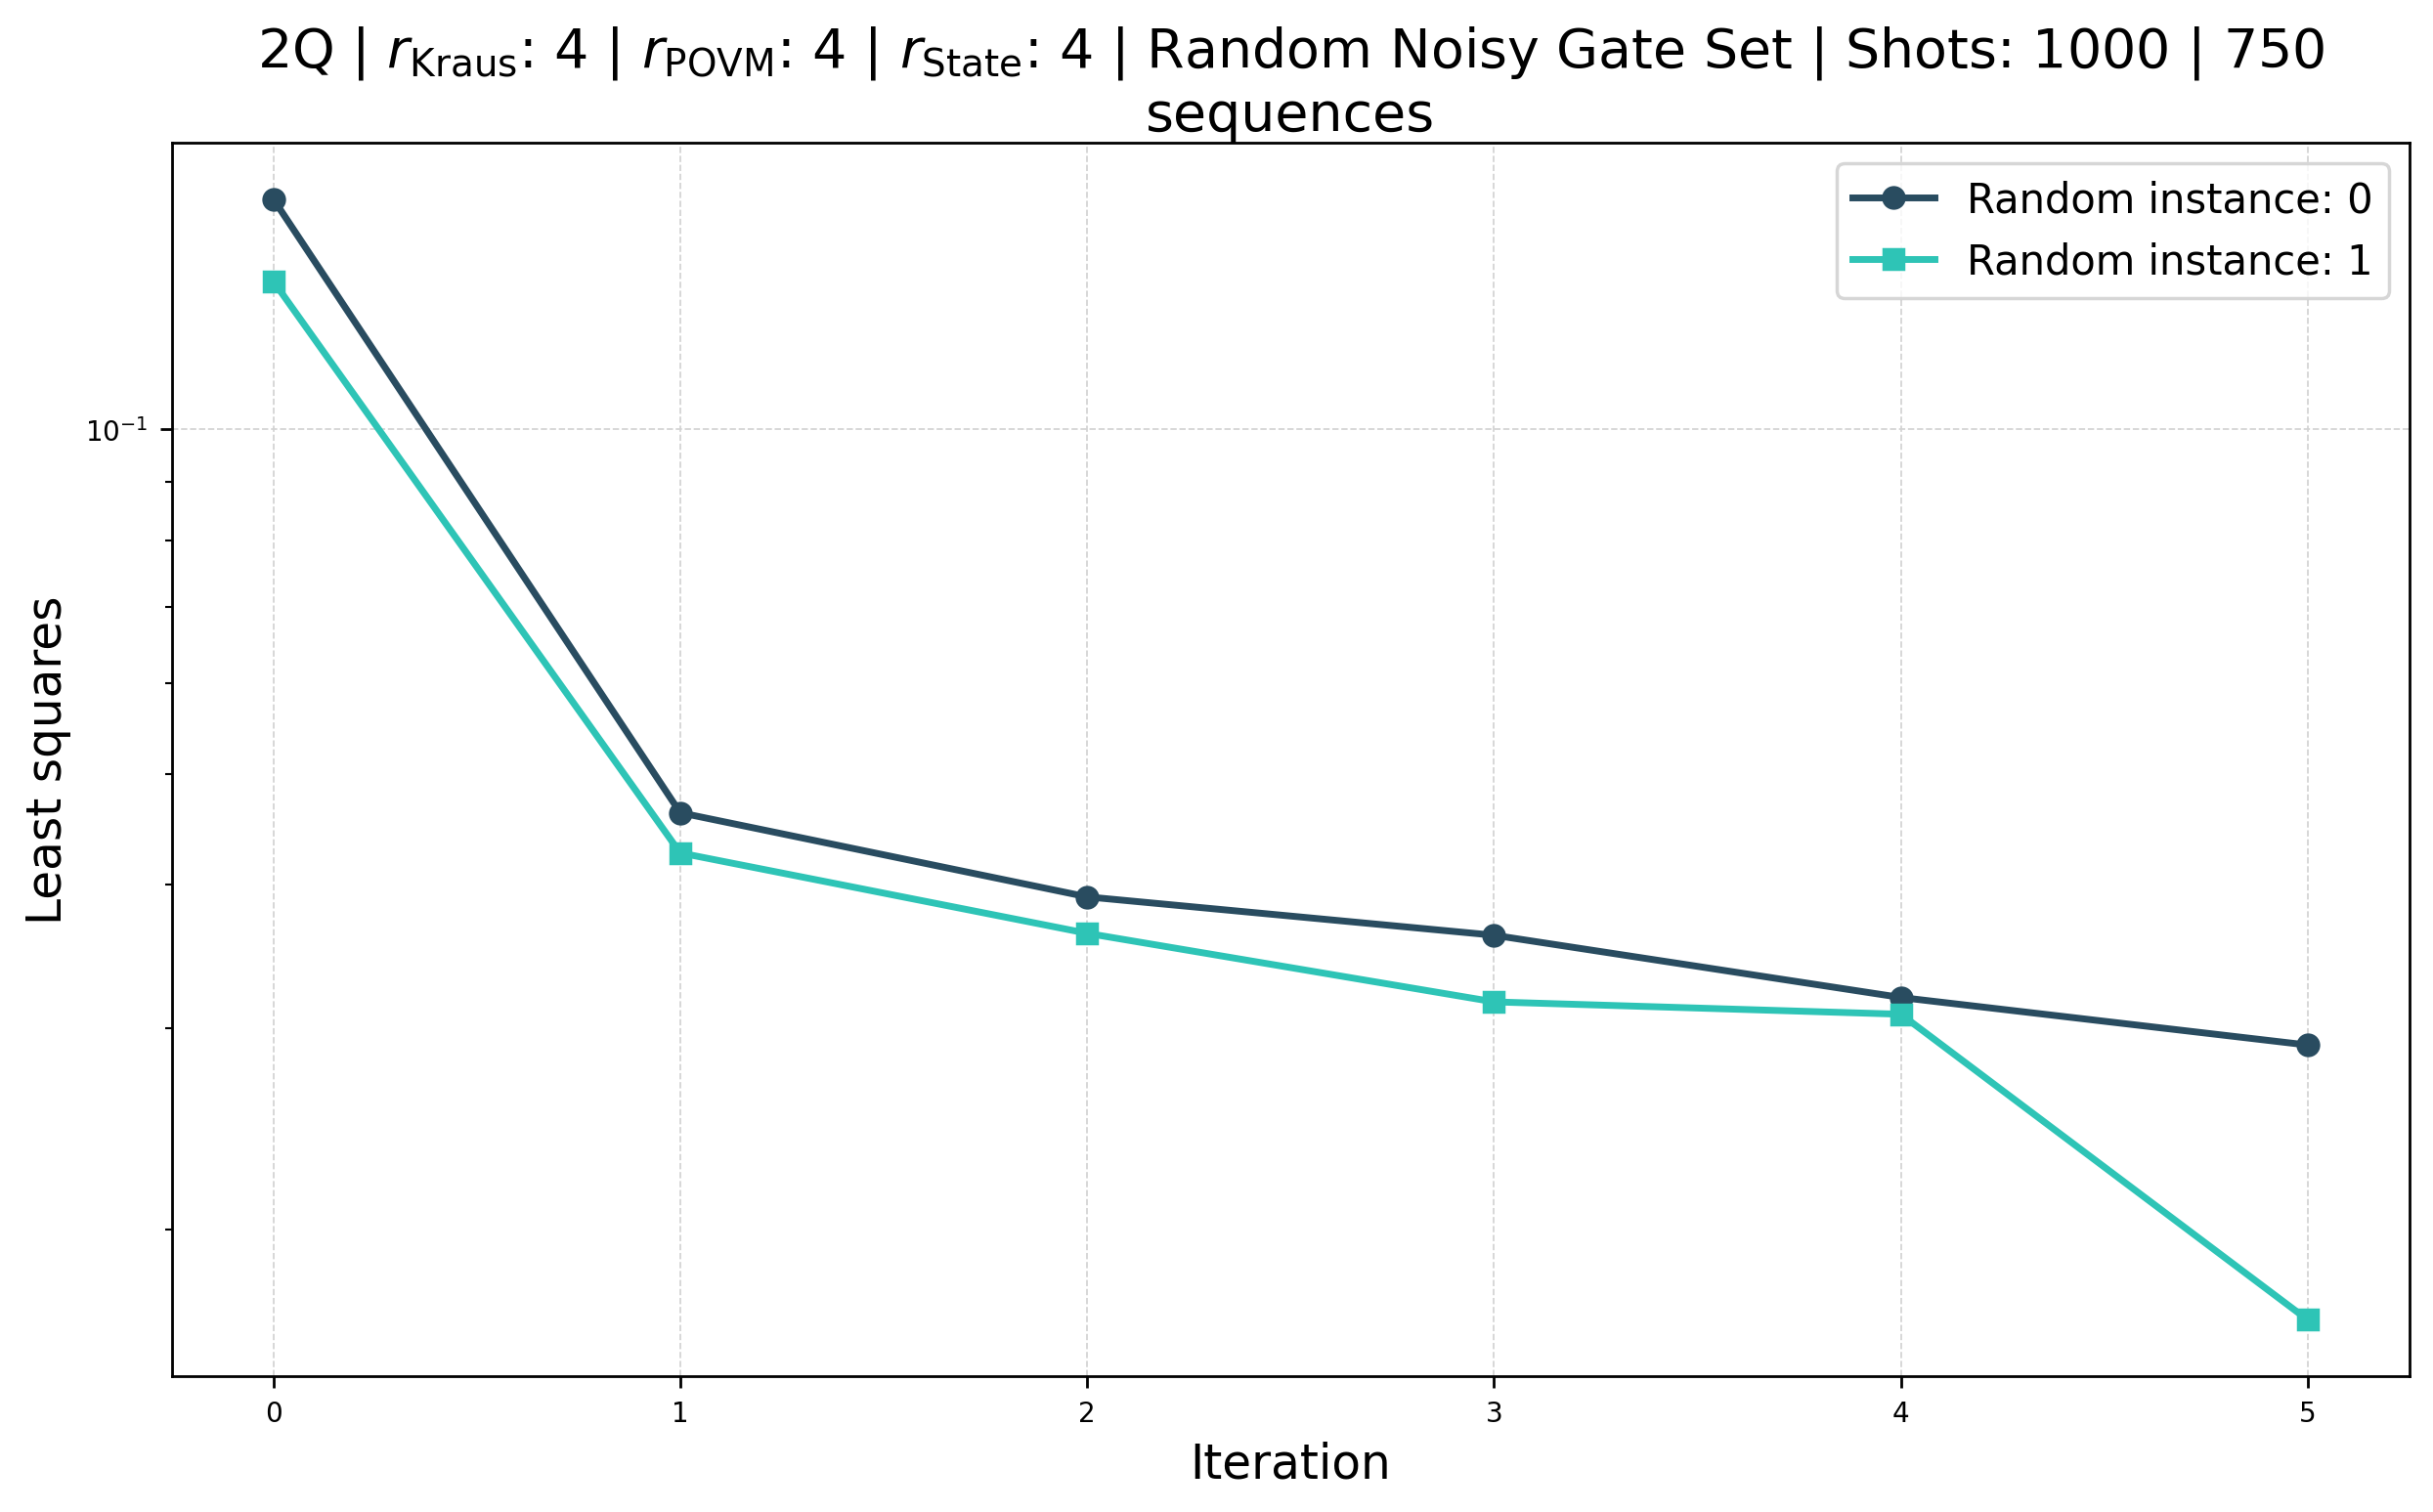

In [118]:
sequences_test = 750

final_results_test = get_all_realizations_for_key(final_results_3, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_3, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

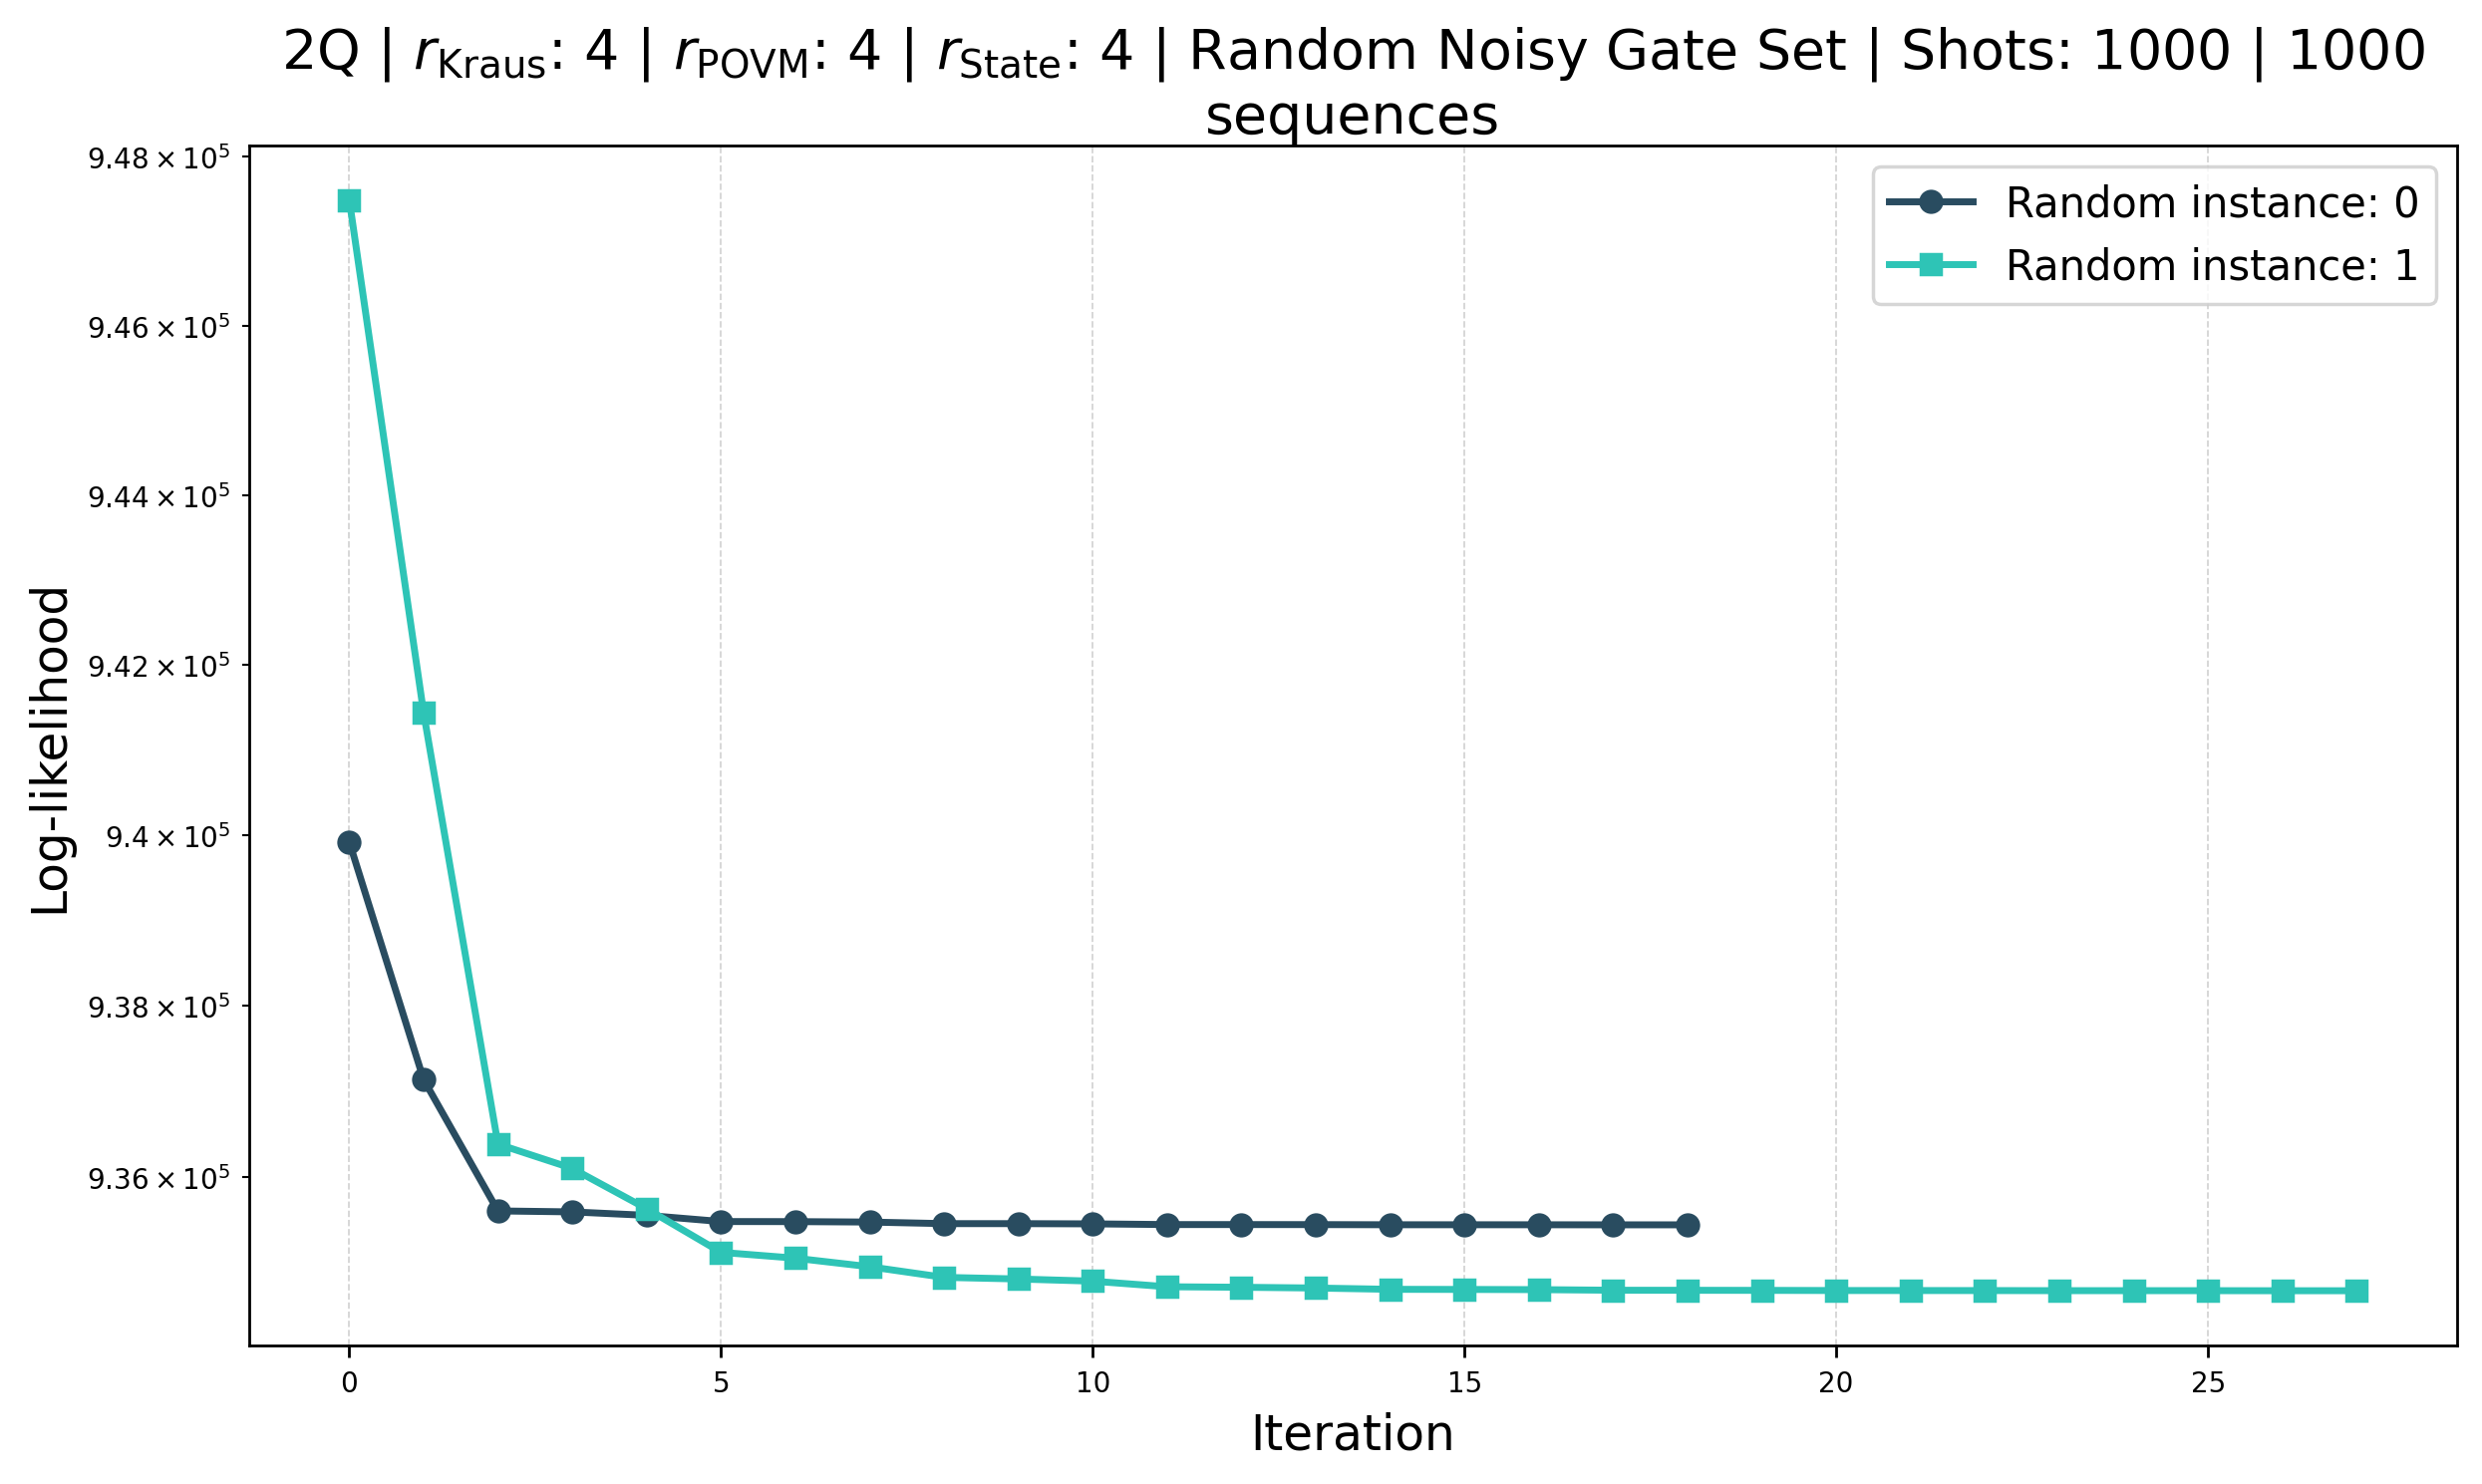

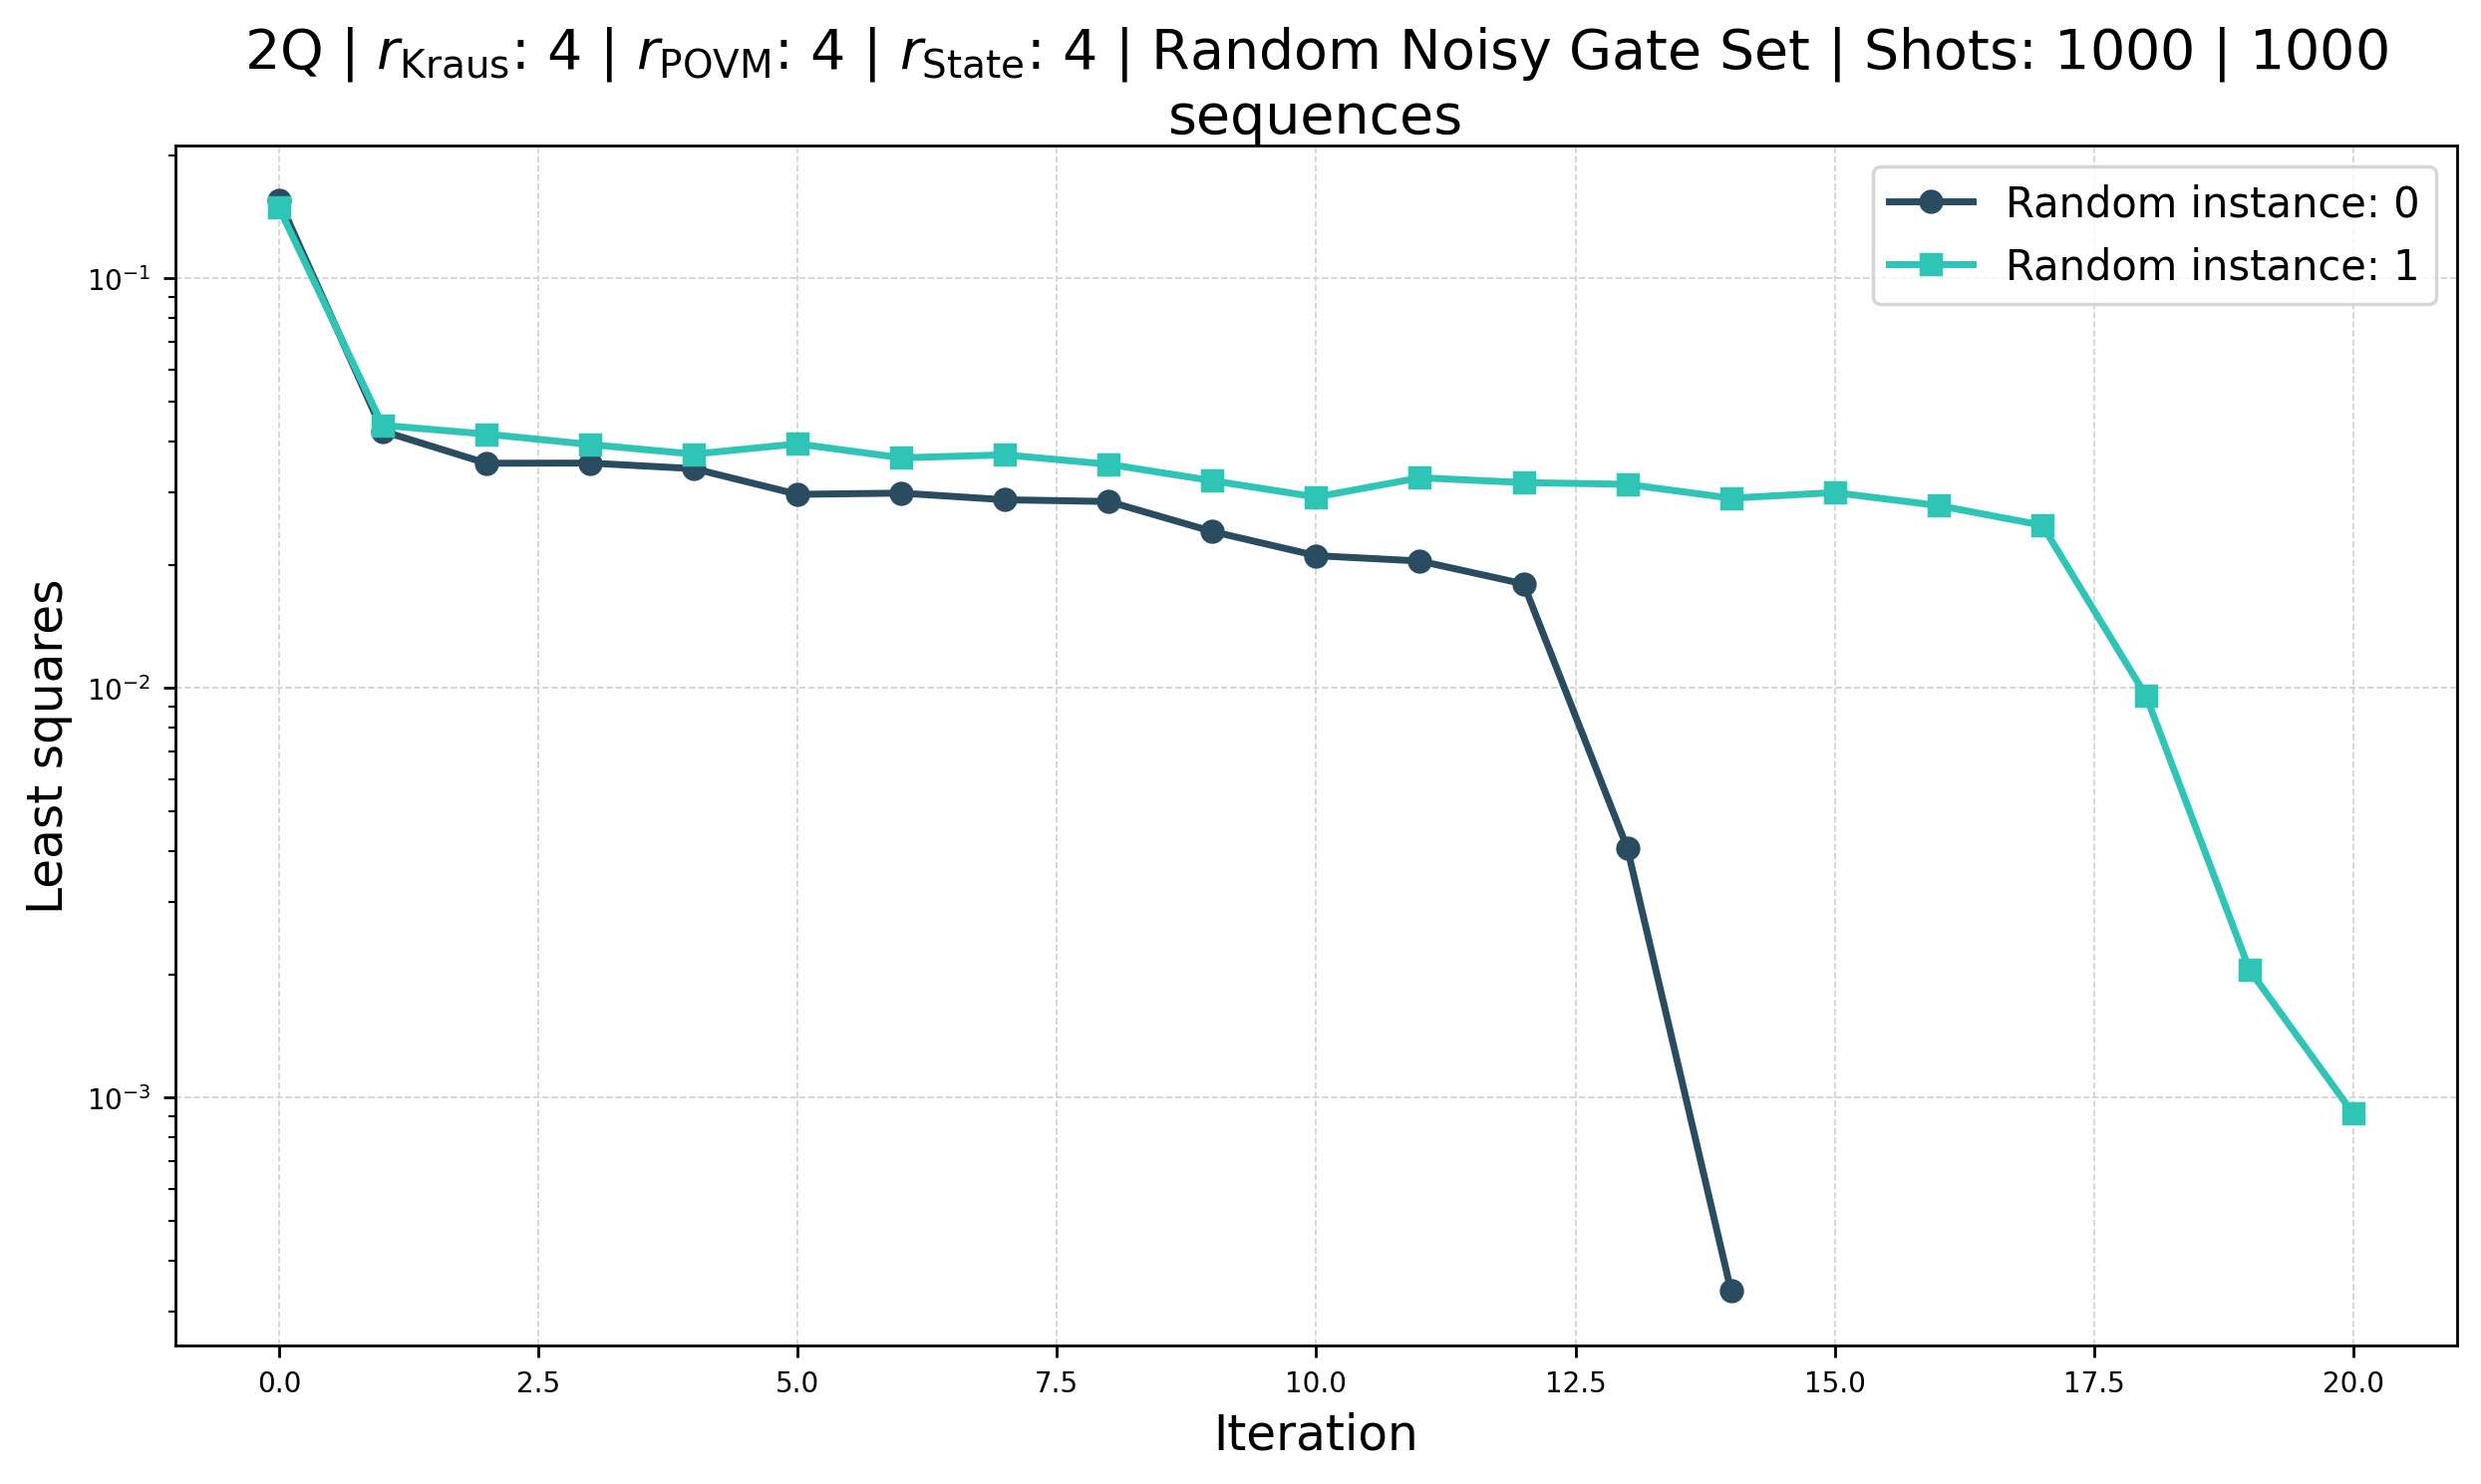

In [162]:
sequences_test = 1000

final_results_test = get_all_realizations_for_key(final_results_5, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_5, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

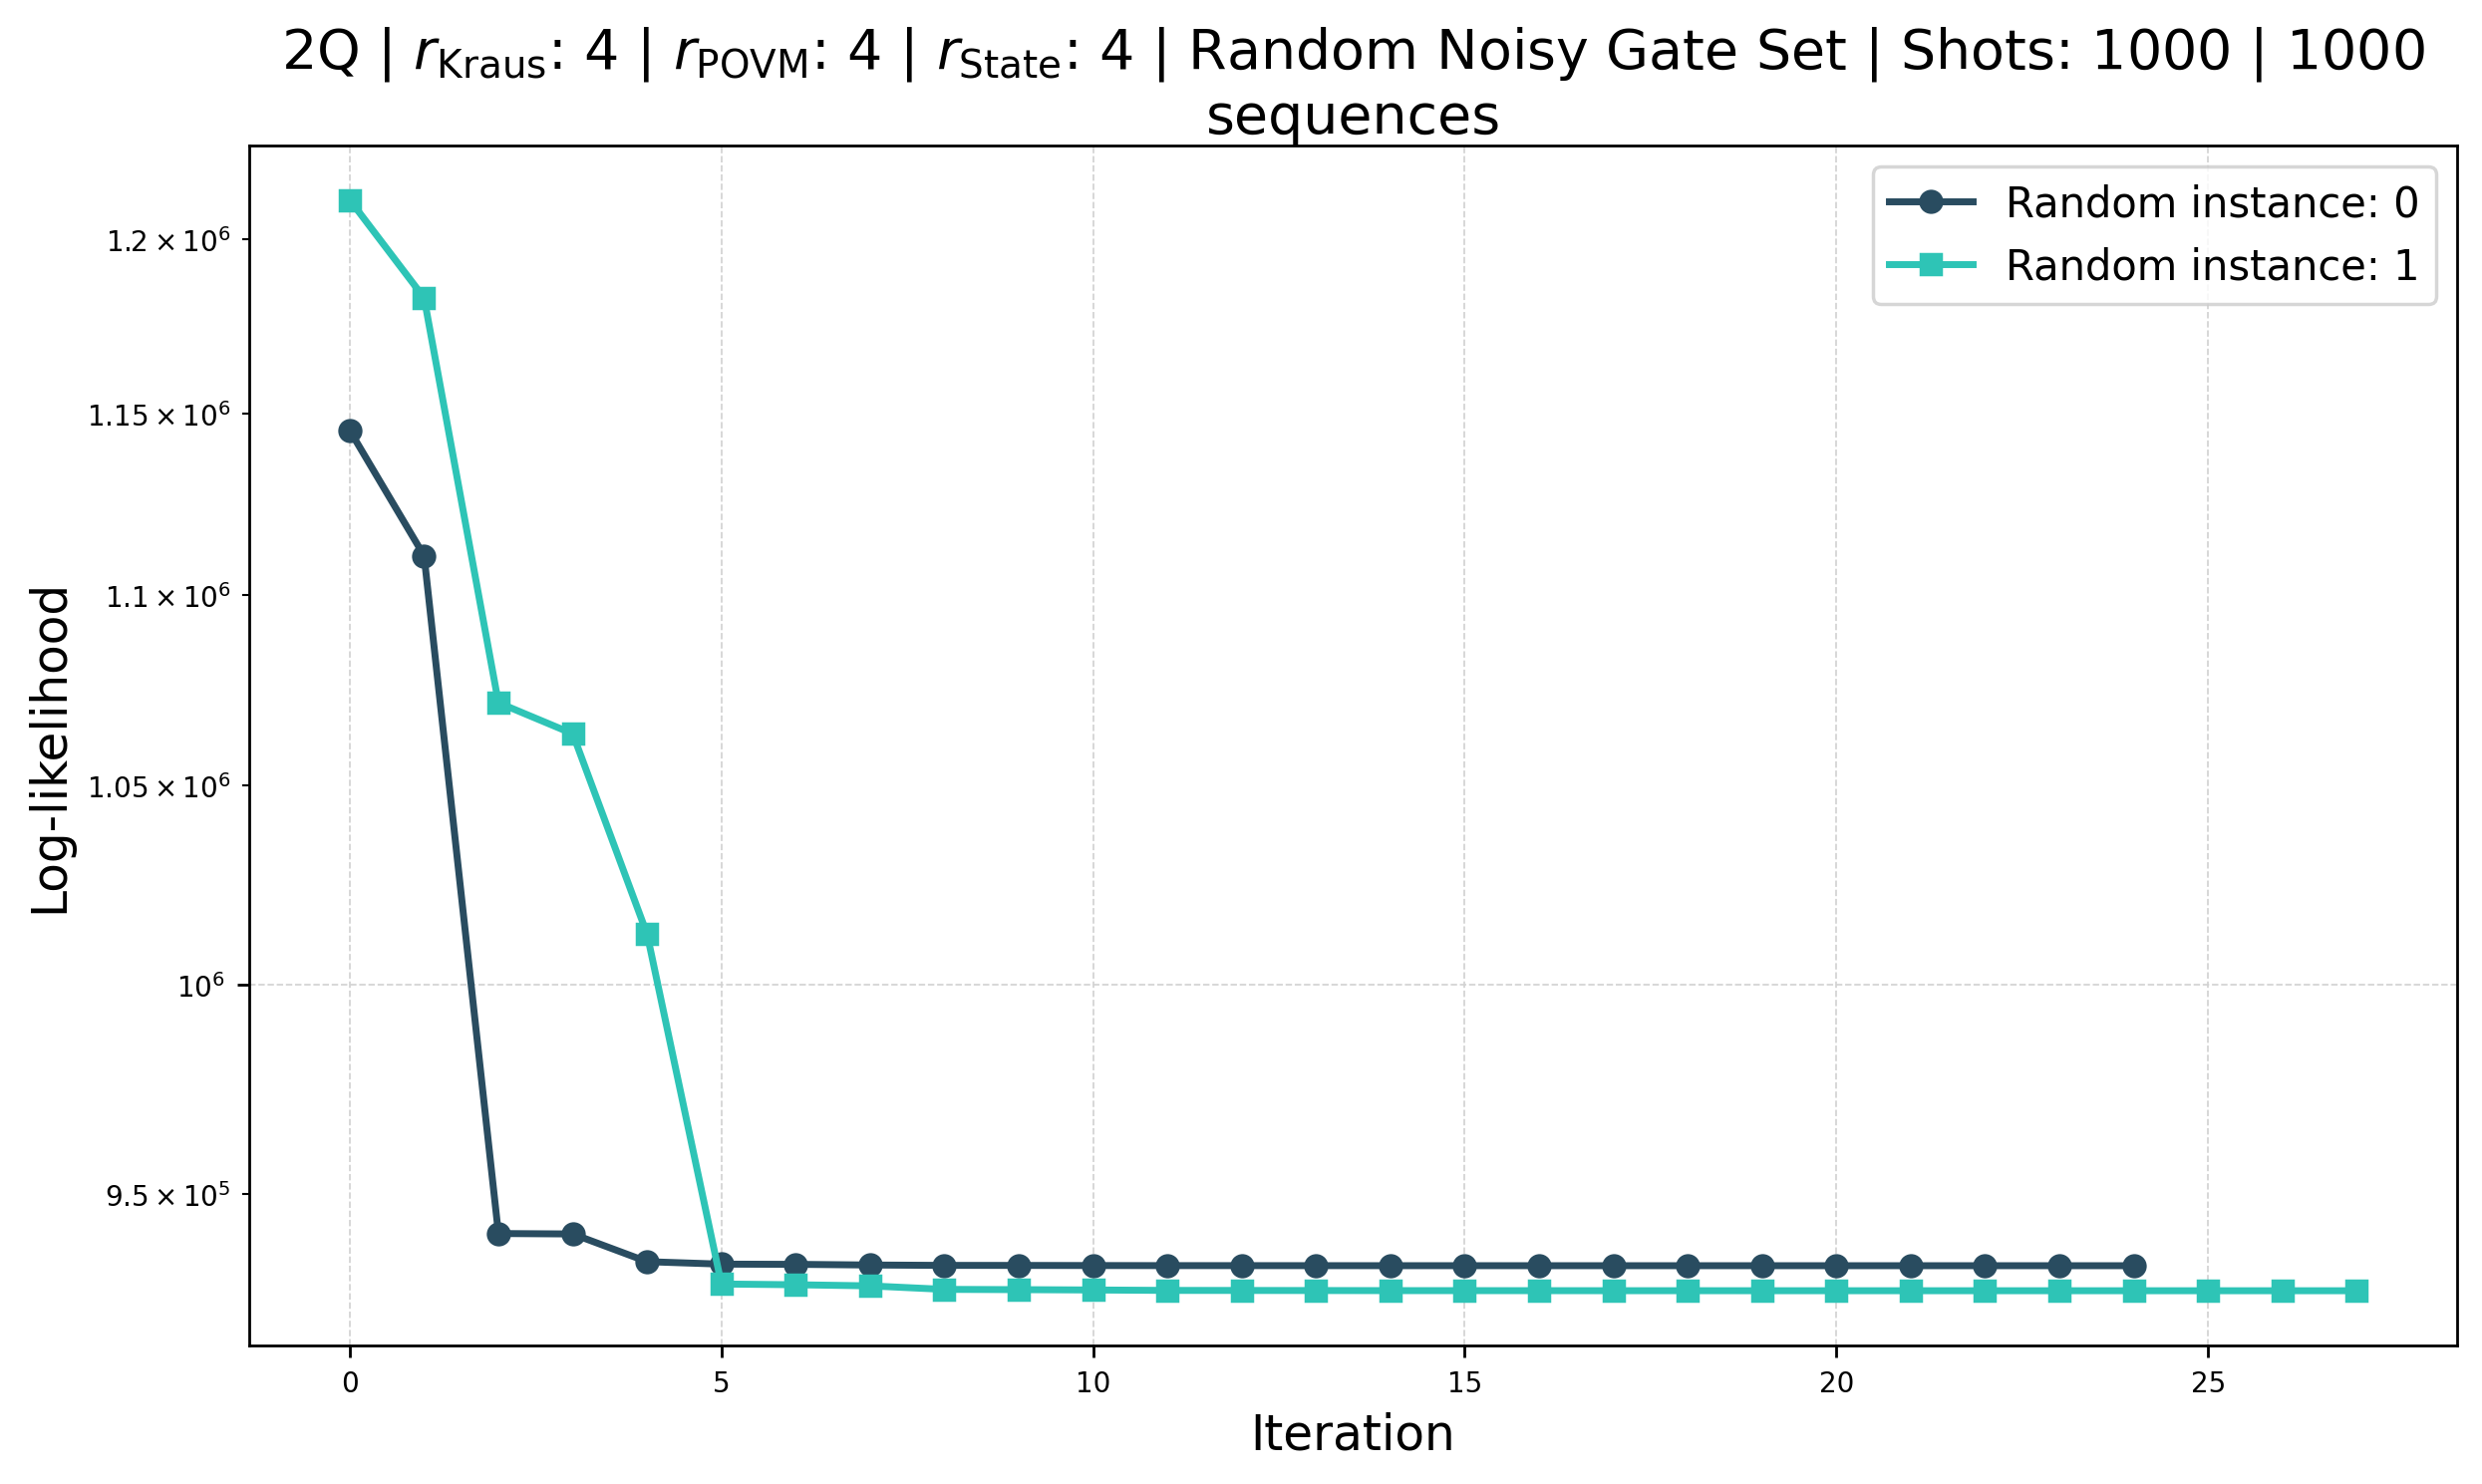

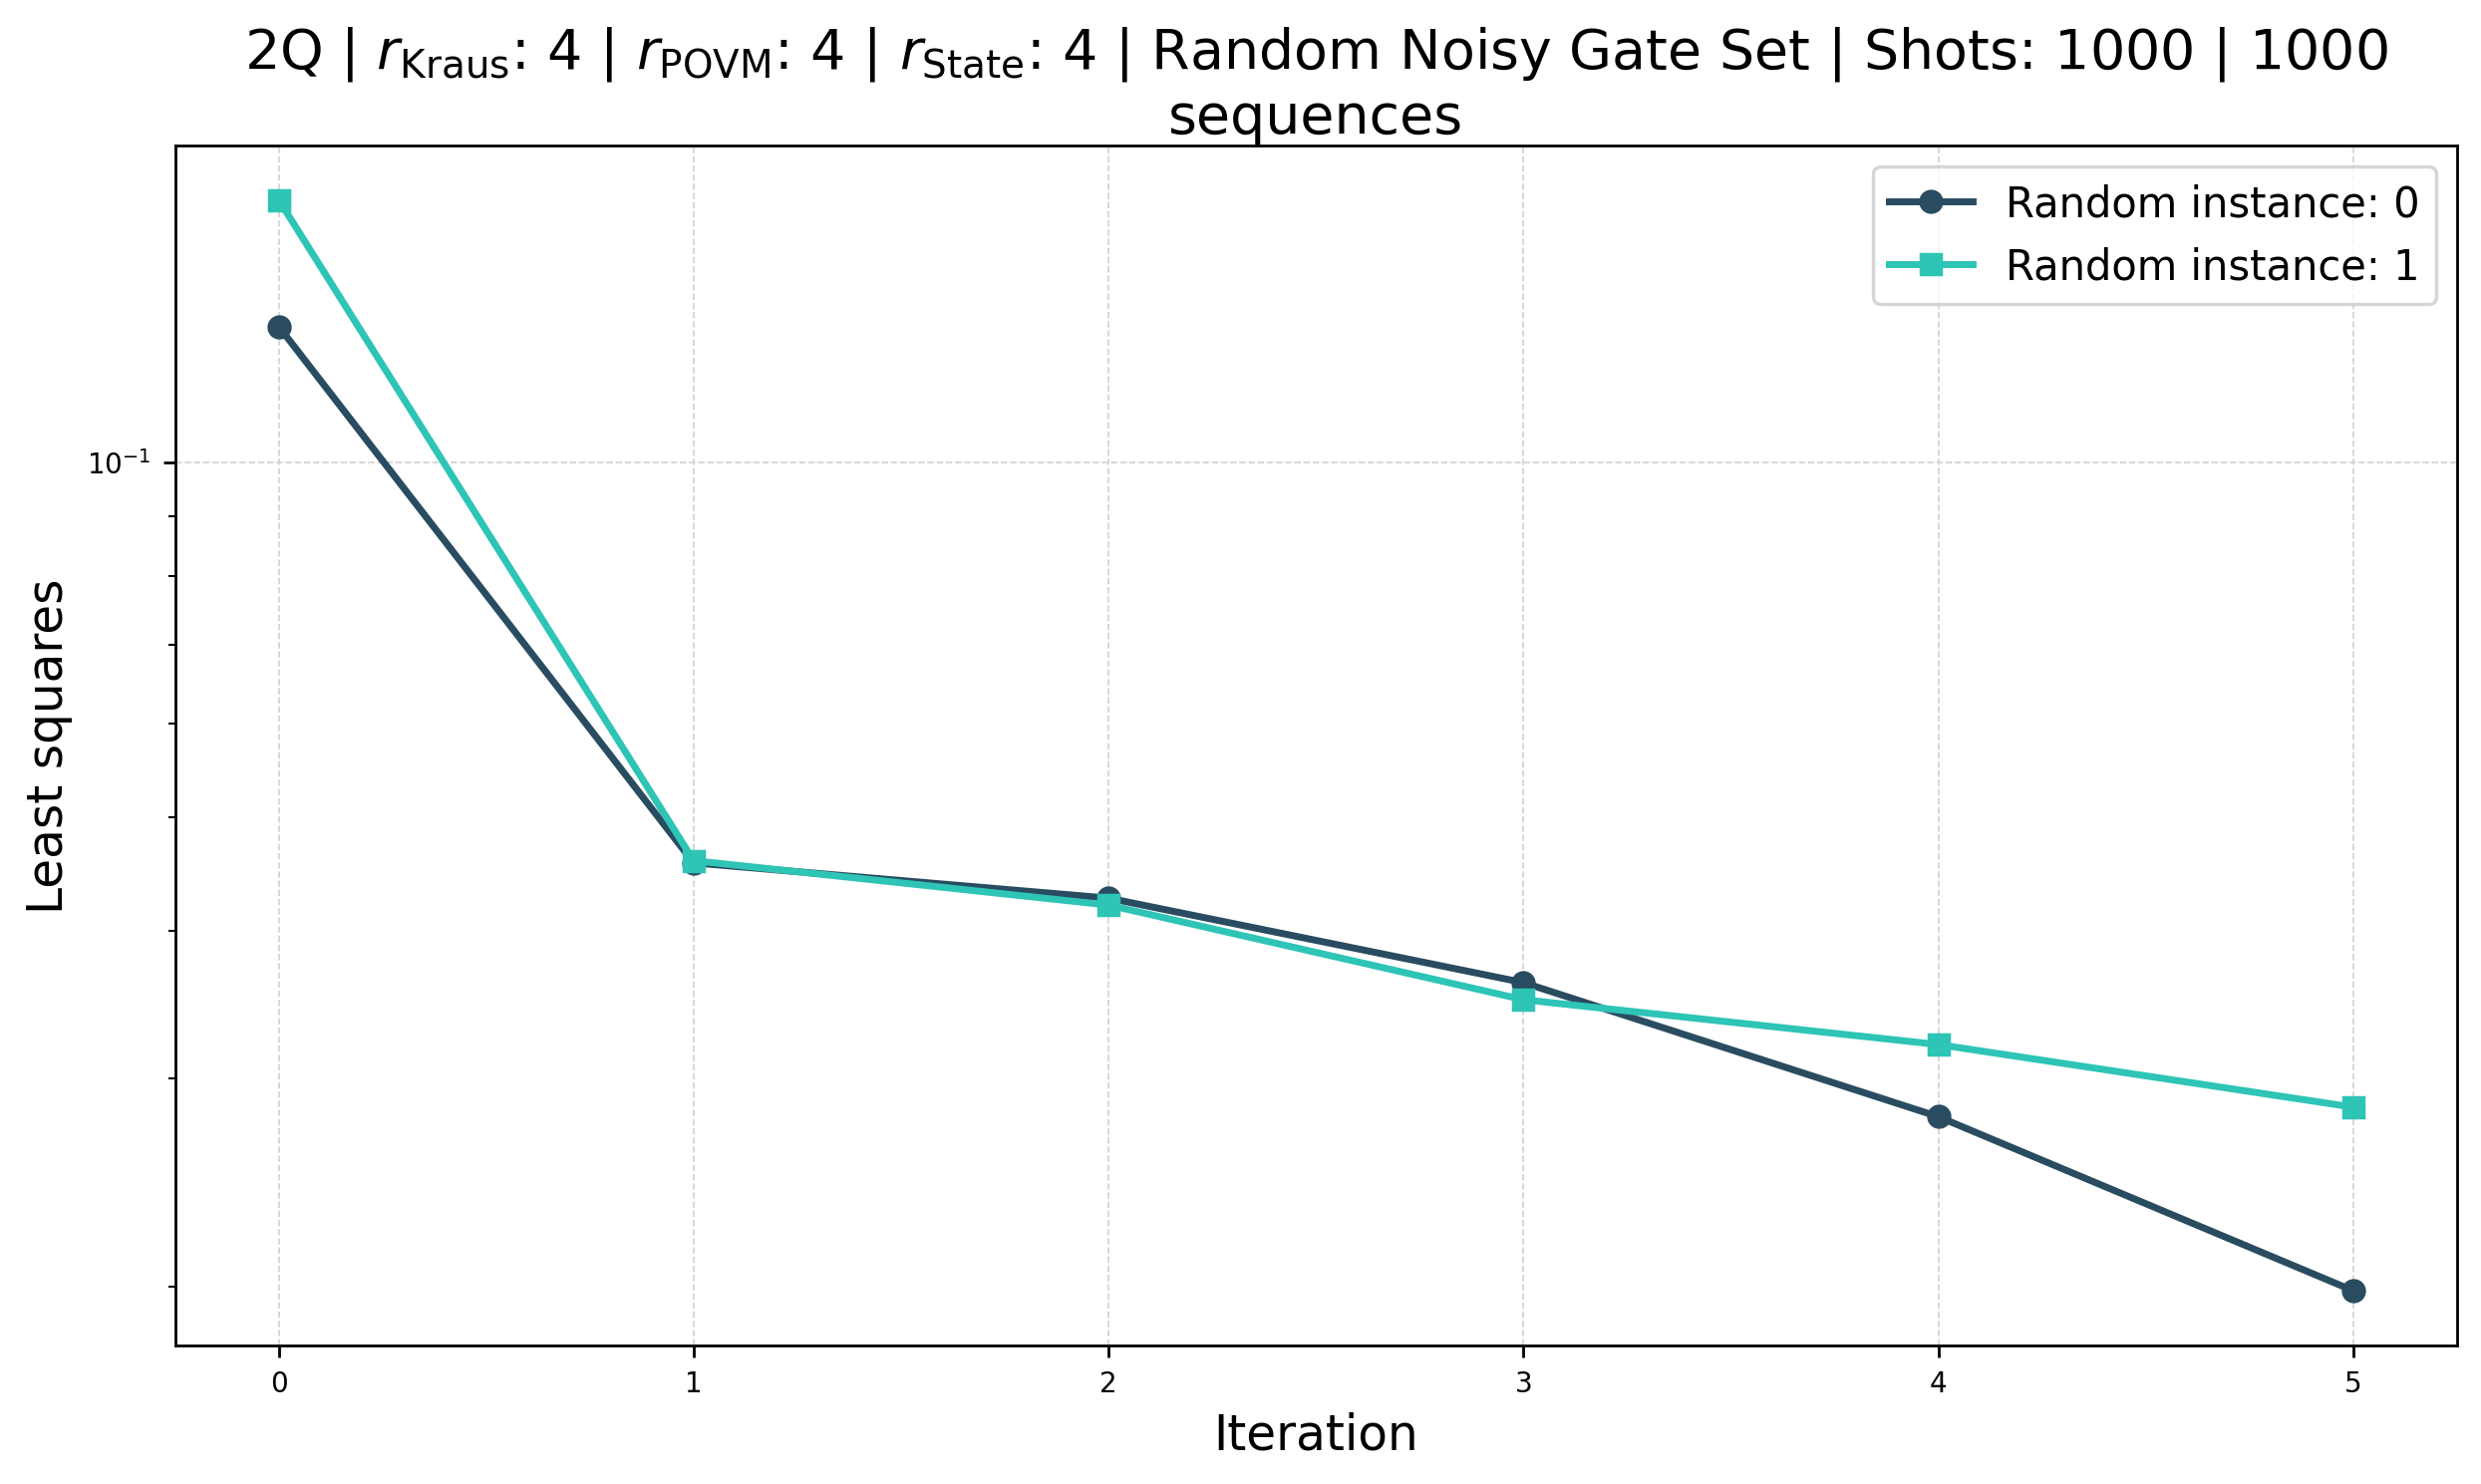

In [112]:
sequences_test = 1000

final_results_test = get_all_realizations_for_key(final_results_4, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_4, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

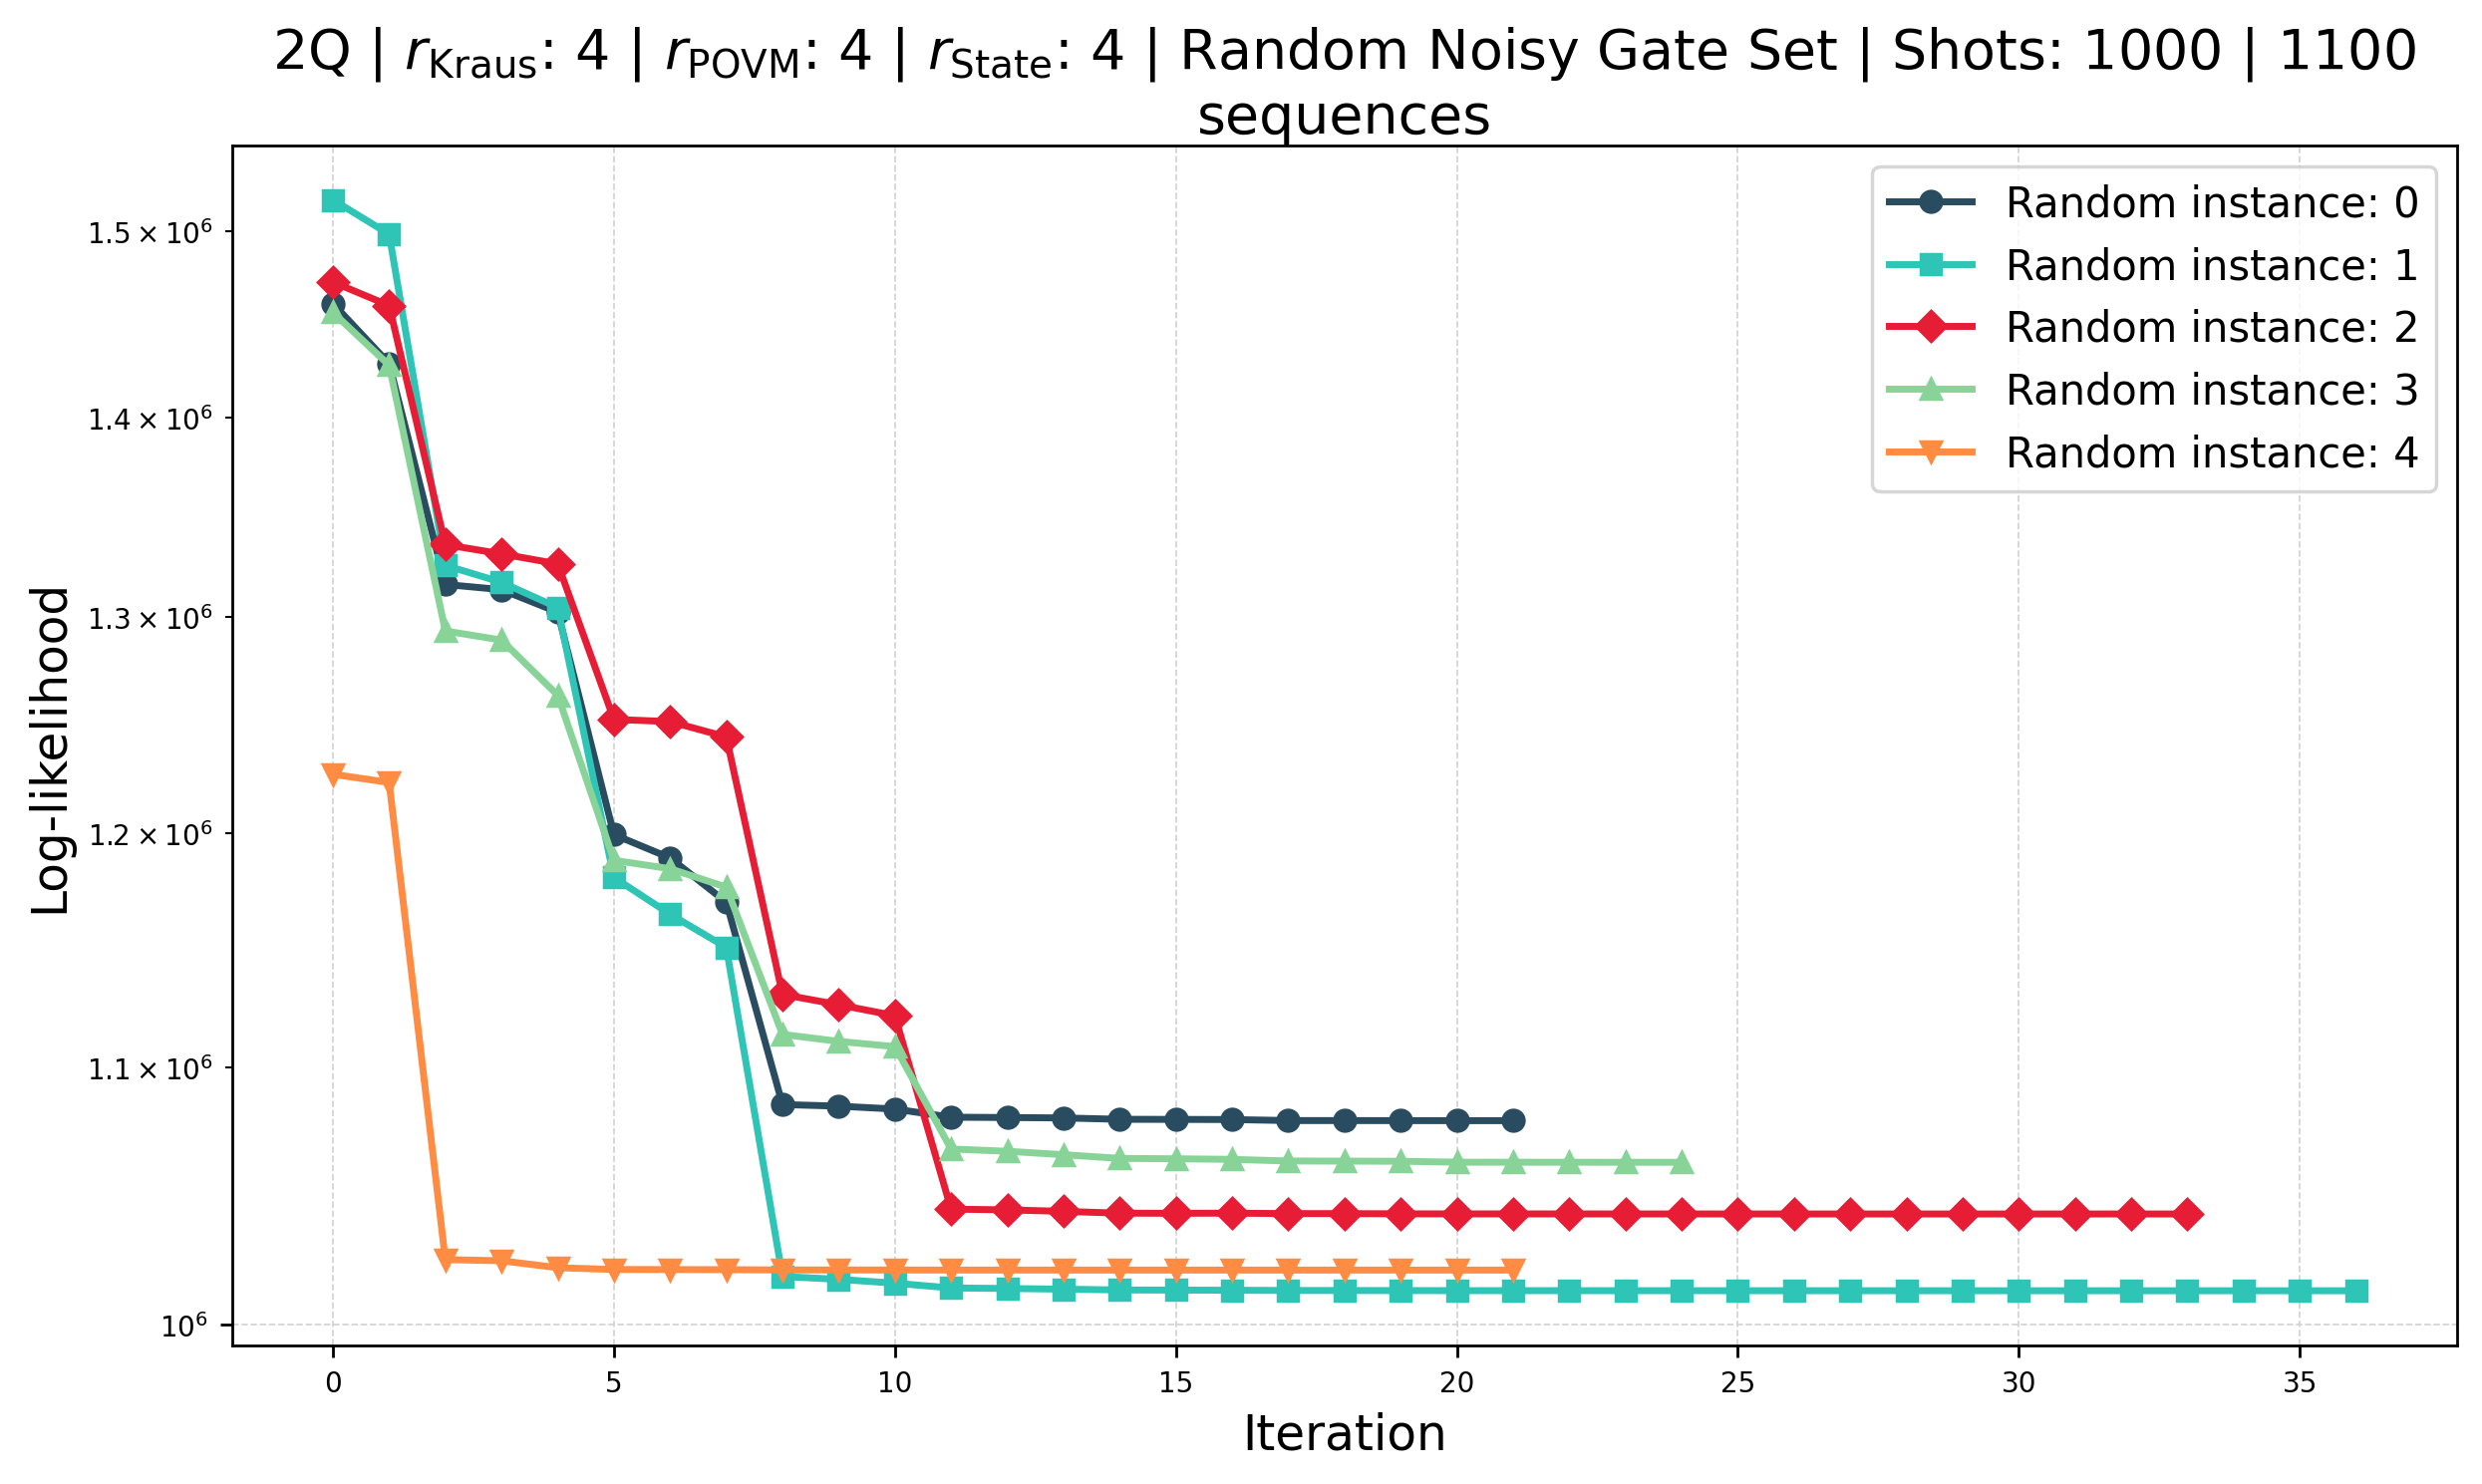

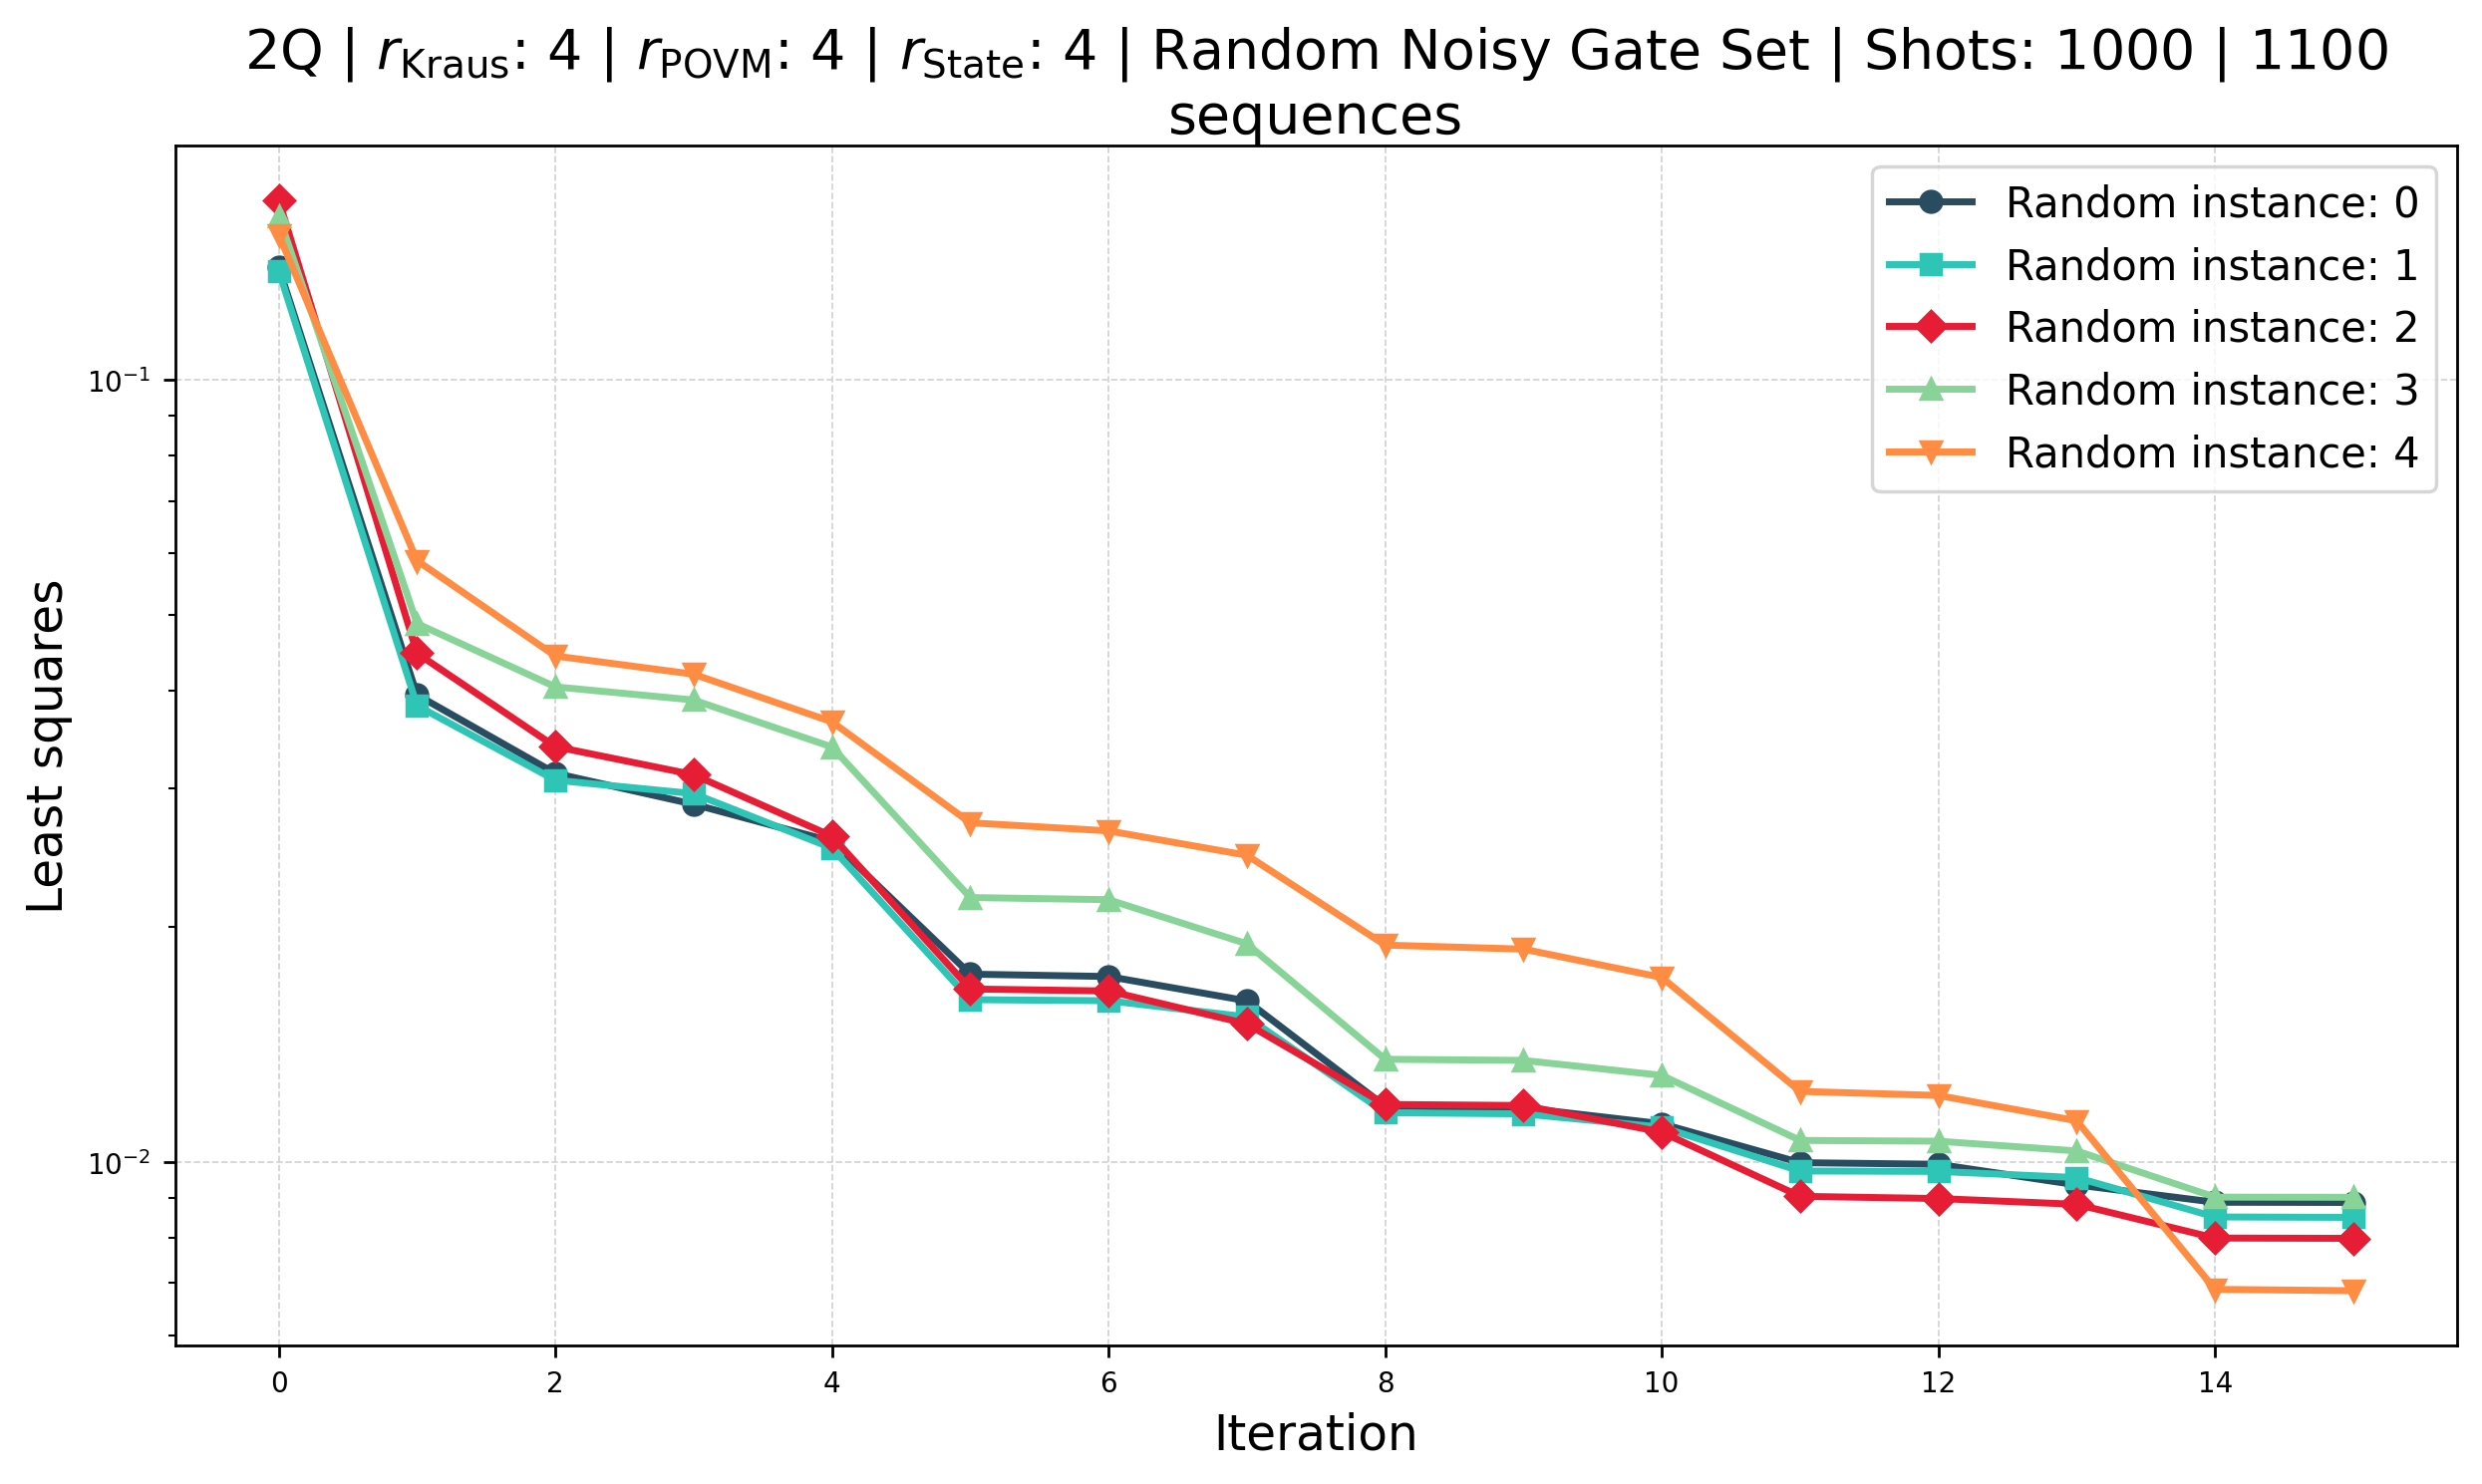

In [ ]:
sequences_test = 1000

final_results_test = get_all_realizations_for_key(final_results_4, str(sequences_test))

costs_test_final = [res["cost_fn_history"]["main"] for res in final_results_test]
labels_random_inits = [f"Random instance: {i}" for i in range(len(final_results_test))]

title = title_init + f" | {sequences_test} sequences"

plot_cost_function(costs_test_final[:], title=title, labels=labels_random_inits[:], ylabel="Log-likelihood")

partial_results_test = get_all_realizations_for_key(partial_results_4, str(sequences_test))

costs_test_partial = [res["cost_fn_history"]["main"] for res in partial_results_test]

plot_cost_function(costs_test_partial[:], title=title, labels=labels_random_inits[:], ylabel="Least squares")

# MVE

In [156]:
mve_results_0, wve_results_large_0 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_0,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_0

[{'100': {'mean': Array(0.36484922, dtype=float64),
   'std': Array(0.0049805, dtype=float64)},
  '150': {'mean': Array(0.07364065, dtype=float64),
   'std': Array(0.00435321, dtype=float64)}},
 {'100': {'mean': Array(0.0503904, dtype=float64),
   'std': Array(0.00527011, dtype=float64)},
  '150': {'mean': Array(0.01121048, dtype=float64),
   'std': Array(0.00026012, dtype=float64)}}]

In [157]:
mve_results_1, wve_results_large_1 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_1,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)

In [140]:
mve_results_1

[{'600': {'mean': Array(0.00534526, dtype=float64),
   'std': Array(5.9740795e-05, dtype=float64)},
  '650': {'mean': Array(0.00487994, dtype=float64),
   'std': Array(5.67801622e-05, dtype=float64)}},
 {'600': {'mean': Array(0.00448299, dtype=float64),
   'std': Array(0.00010177, dtype=float64)},
  '650': {'mean': Array(0.00471619, dtype=float64),
   'std': Array(7.60167755e-05, dtype=float64)}}]

In [147]:
mve_results_2, wve_results_large_2 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_2,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)

In [148]:
mve_results_2

[{'500': {'mean': Array(0.00587815, dtype=float64),
   'std': Array(7.36294298e-05, dtype=float64)},
  '550': {'mean': Array(0.05954307, dtype=float64),
   'std': Array(0.00384927, dtype=float64)}},
 {'500': {'mean': Array(0.00580847, dtype=float64),
   'std': Array(0.00011778, dtype=float64)},
  '550': {'mean': Array(0.00509902, dtype=float64),
   'std': Array(7.87002132e-05, dtype=float64)}},
 {'500': {'mean': Array(0.00529004, dtype=float64),
   'std': Array(9.80921659e-05, dtype=float64)},
  '550': {'mean': Array(0.00552136, dtype=float64),
   'std': Array(0.00011025, dtype=float64)}},
 {'500': {'mean': Array(0.00589885, dtype=float64),
   'std': Array(0.0001483, dtype=float64)},
  '550': {'mean': Array(0.00565028, dtype=float64),
   'std': Array(9.82191153e-05, dtype=float64)}},
 {'500': {'mean': Array(0.00631851, dtype=float64),
   'std': Array(0.00011441, dtype=float64)},
  '550': {'mean': Array(0.00578916, dtype=float64),
   'std': Array(8.39945201e-05, dtype=float64)}}]

In [132]:
mve_results_3, wve_results_large_3 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_3,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)

In [133]:
mve_results_3

[{'700': {'mean': Array(0.00545152, dtype=float64),
   'std': Array(8.23905083e-05, dtype=float64)},
  '750': {'mean': Array(0.00497923, dtype=float64),
   'std': Array(8.77735192e-05, dtype=float64)}},
 {'700': {'mean': Array(0.00501733, dtype=float64),
   'std': Array(8.00254466e-05, dtype=float64)},
  '750': {'mean': Array(0.00516564, dtype=float64),
   'std': Array(0.00012592, dtype=float64)}}]

In [113]:
mve_results_4, wve_results_large_4 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_4,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)

In [115]:
mve_results_4

[{'1000': {'mean': Array(0.00489905, dtype=float64),
   'std': Array(0.00010383, dtype=float64)}},
 {'1000': {'mean': Array(0.00399239, dtype=float64),
   'std': Array(4.0105814e-05, dtype=float64)}}]

In [163]:
mve_results_5, wve_results_large_5 = compute_mve_and_wve_for_all_realizations(
    optimization_results=final_results_5,
    true_superops=noisy_gate_set_superop,
    sequence_length=mve_seq_length,
    num_circuits_sampled=num_circuits_sampled,
    num_repetitions=num_random_runs,
    which_data="optimized_operators",
)
mve_results_5

[{'1000': {'mean': Array(0.00434232, dtype=float64),
   'std': Array(4.65112416e-05, dtype=float64)}},
 {'1000': {'mean': Array(0.00430934, dtype=float64),
   'std': Array(4.62509243e-05, dtype=float64)}}]

In [158]:
mve_combined = combine_error_results(mve_results_0, mve_results_2[1:3], mve_results_1, mve_results_3, mve_results_4)
mean_mve_results_combined = compute_avg_and_std_along_keys(list_of_errors=mve_combined)

In [164]:
result_1000_seq = mve_results_test["1000"]
result_1000_seq_dict = {key: result_1000_seq for key in mean_mve_results_combined}
result_1000_seq

{'mean': Array(0.00376728, dtype=float64),
 'std': Array(4.57926501e-05, dtype=float64)}

In [159]:
mean_mve_results_combined

{'100': {'mean': Array(0.20761981, dtype=float64),
  'std': Array(0.15722941, dtype=float64)},
 '150': {'mean': Array(0.04242557, dtype=float64),
  'std': Array(0.03121509, dtype=float64)},
 '500': {'mean': Array(0.00554926, dtype=float64),
  'std': Array(0.00025921, dtype=float64)},
 '550': {'mean': Array(0.00531019, dtype=float64),
  'std': Array(0.00021117, dtype=float64)},
 '600': {'mean': Array(0.00496106, dtype=float64),
  'std': Array(0.0004812, dtype=float64)},
 '650': {'mean': Array(0.0047662, dtype=float64),
  'std': Array(9.40657071e-05, dtype=float64)},
 '700': {'mean': Array(0.00523442, dtype=float64),
  'std': Array(0.0002171, dtype=float64)},
 '750': {'mean': Array(0.00507244, dtype=float64),
  'std': Array(9.32042562e-05, dtype=float64)},
 '1000': {'mean': Array(0.00444572, dtype=float64),
  'std': Array(0.00045333, dtype=float64)}}

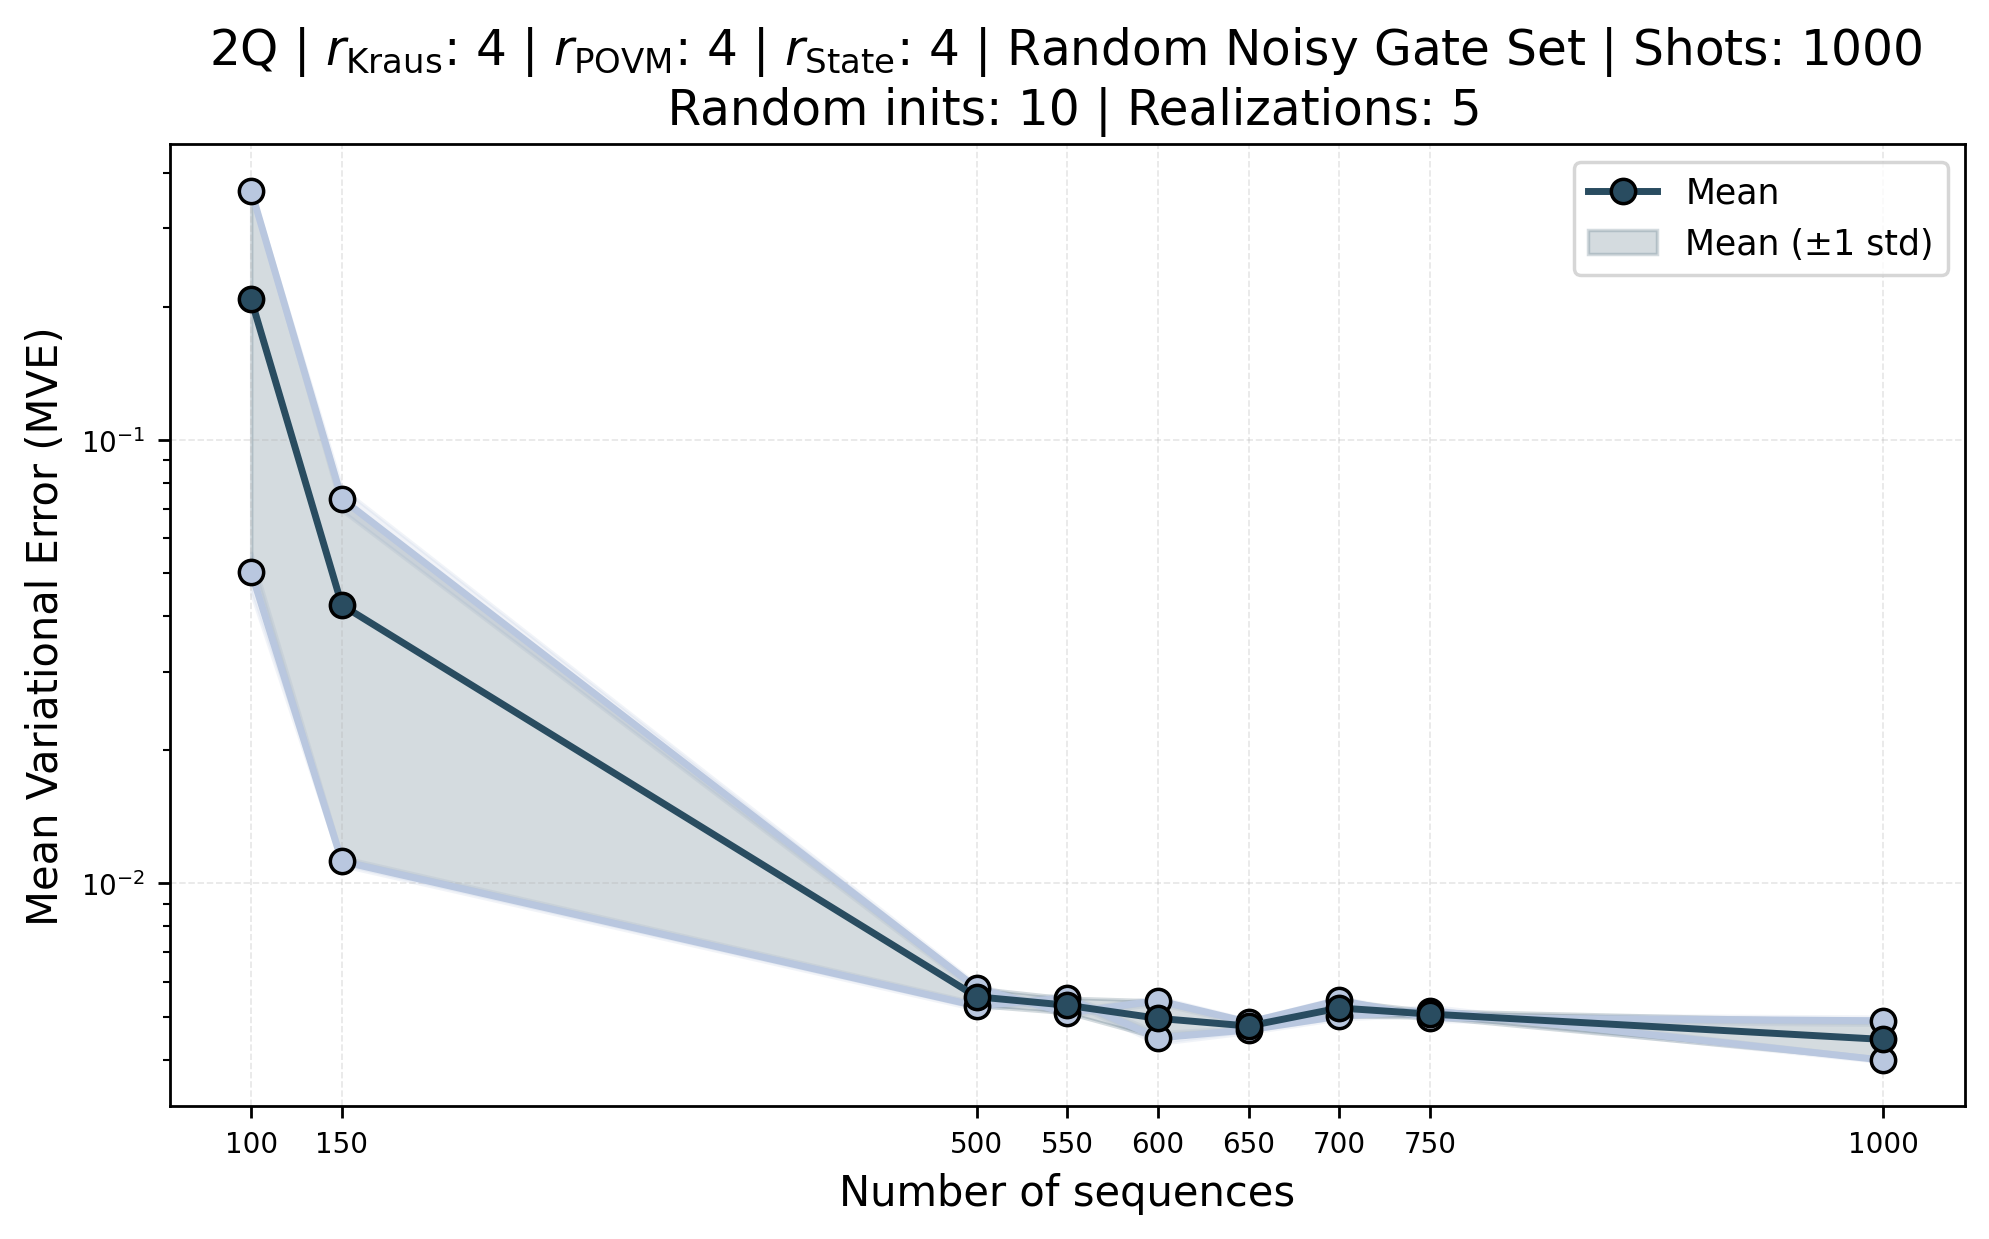

In [173]:
fig_all_mve = plot_many_mean_std_vs_x(
    data=mve_combined,
    title=title_mve,
    ylabel=f"Mean Variational Error (MVE)",
    use_log_scale="y",
    main_curve=mean_mve_results_combined,
    main_curve_label="Mean",
    # main_curve=result_1000_seq_dict,
    # main_curve_label="1000 Sequences (target init)",
    show=False,
)

In [175]:
min_expected, max_expected

(623, 815)

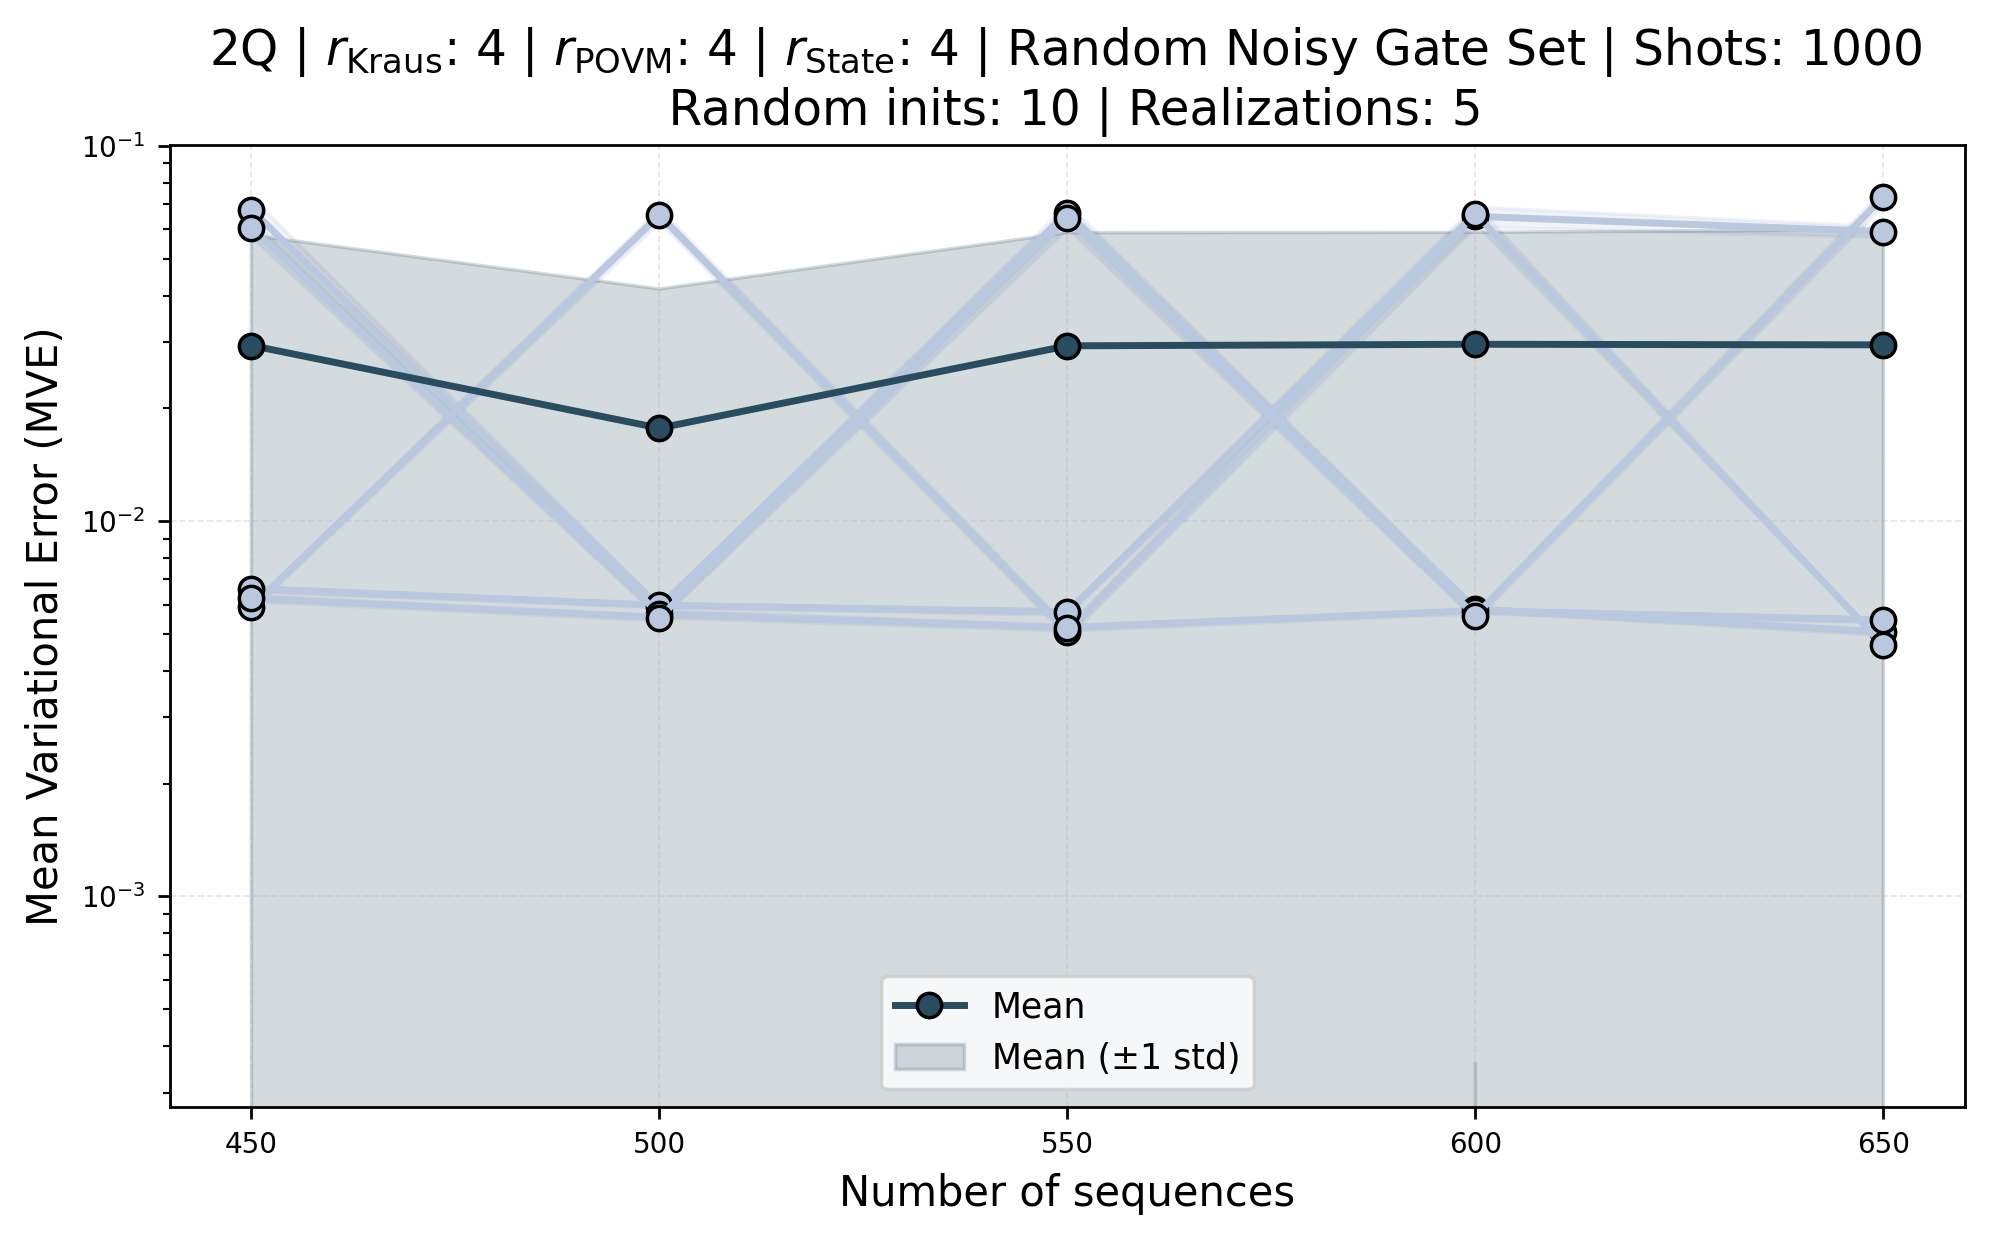

In [35]:
fig_all_mve_ammended = plot_many_mean_std_vs_x(
    data=mve_combined,
    title=title_mve,
    ylabel=f"Mean Variational Error (MVE)",
    use_log_scale="y",
    main_curve=mean_mve_results_combined,
    main_curve_label="Mean",
    show=False,
)